In [3]:

from pathlib import Path
import pandas as pd

# Locate the main project folder.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Locate the Parquet dataset.
file_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "ca1_100_series_daily.parquet"
)

print("File exists:", file_path.exists())
print("Looking for file at:", file_path)

# Load the dataset.
df = pd.read_parquet(file_path)

print("\nRows and columns:", df.shape)
print("Unique products:", df["item_id"].nunique())

display(df.head(10))



File exists: True
Looking for file at: /Users/nikhilkoushik/Desktop/AI project/project-02-forecasting-ml/data/processed/ca1_100_series_daily.parquet

Rows and columns: (191300, 13)
Unique products: 100


,store_id,item_id,dept_id,cat_id,date,day_number,units_sold,wday,month,year,event_type_1,snap_ca,sell_price
0,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-01-29,1,3,1,1,2011,NaN,0,2.0000
1,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-01-30,2,0,2,1,2011,NaN,0,2.0000
2,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-01-31,3,0,3,1,2011,NaN,0,2.0000
3,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-01,4,1,4,2,2011,NaN,1,2.0000
4,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-02,5,4,5,2,2011,NaN,1,2.0000
5,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-03,6,2,6,2,2011,NaN,1,2.0000
6,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-04,7,0,7,2,2011,NaN,1,2.0000
7,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-05,8,2,1,2,2011,NaN,1,2.0000
8,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-06,9,0,2,2,2011,Sporting,1,2.0000
9,CA_1,FOODS_1_001,FOODS_1,FOODS,2011-02-07,10,0,3,2,2011,NaN,1,2.0000


In [2]:

import os

print(os.getcwd())


/Users/nikhilkoushik/Desktop/AI project/project-02-forecasting-ml/notebooks


In [6]:


# Calculate the average sales from the previous 28 days.
df["rolling_mean_28"] = (
    df.groupby(["store_id", "item_id"])["units_sold"]
    .transform(
        lambda sales: sales.shift(1)
        .rolling(window=28, min_periods=28)
        .mean()
    )
)

print("Rolling feature created successfully!")

display(
    df[
        ["item_id", "day_number",
         "units_sold", "rolling_mean_28"]
    ].iloc[27:37]
)



Rolling feature created successfully!


,item_id,day_number,units_sold,rolling_mean_28
27,FOODS_1_001,28,4,NaN
28,FOODS_1_001,29,2,1.392857
29,FOODS_1_001,30,2,1.357143
30,FOODS_1_001,31,0,1.428571
31,FOODS_1_001,32,2,1.428571
32,FOODS_1_001,33,1,1.464286
33,FOODS_1_001,34,7,1.357143
34,FOODS_1_001,35,1,1.535714
35,FOODS_1_001,36,2,1.571429
36,FOODS_1_001,37,3,1.571429


In [7]:

feature_columns = [
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_28",
]

print(df[feature_columns].isna().sum())


lag_7               700
lag_14             1400
lag_28             2800
rolling_mean_28    2800
dtype: int64


In [8]:

# Forecast origin: last day of known sales.
FORECAST_ORIGIN = 1857
HORIZON = 28

# Use only history available at forecast time.
history = df[
    df["day_number"] <= FORECAST_ORIGIN
].copy()

# Take the last 28 observations for each product.
last_28_days = (
    history.groupby(["store_id", "item_id"])
    .tail(28)
)

# Calculate features using only known sales.
features = (
    last_28_days
    .groupby(["store_id", "item_id"])
    .agg(
        mean_sales_last_28=("units_sold", "mean"),
        total_sales_last_28=("units_sold", "sum"),
        zero_sales_days_last_28=(
            "units_sold",
            lambda x: (x == 0).sum()
        ),
    )
    .reset_index()
)

print("Forecast origin:", FORECAST_ORIGIN)
print("Products with historical features:", len(features))

display(features.head(10))


Forecast origin: 1857
Products with historical features: 100


,store_id,item_id,mean_sales_last_28,total_sales_last_28,zero_sales_days_last_28
0,CA_1,FOODS_1_001,0.714286,20,16
1,CA_1,FOODS_1_002,0.500000,14,21
2,CA_1,FOODS_1_003,0.714286,20,16
3,CA_1,FOODS_1_004,2.107143,59,23
4,CA_1,FOODS_1_005,1.392857,39,10
5,CA_1,FOODS_1_006,2.321429,65,3
6,CA_1,FOODS_1_008,0.500000,14,19
7,CA_1,FOODS_1_009,0.285714,8,24
8,CA_1,FOODS_1_010,0.142857,4,25
9,CA_1,FOODS_1_011,1.178571,33,11


In [9]:

assert history["day_number"].max() == FORECAST_ORIGIN

assert (
    last_28_days.groupby(["store_id", "item_id"])
    .size()
    .eq(28)
    .all()
)

assert len(features) == 100

print("Forecast-origin checks passed!")
print("Last historical day:", history["day_number"].max())
print("Product series:", len(features))


Forecast-origin checks passed!
Last historical day: 1857
Product series: 100


In [10]:

import pandas as pd

# Start with three historical forecast origins.
# All target dates remain inside our training period.
TRAIN_ORIGINS = [1500, 1528, 1556]

training_examples = []

for origin in TRAIN_ORIGINS:

    # Only sales known at this historical origin.
    past = df[
        (df["day_number"] > origin - 28)
        & (df["day_number"] <= origin)
    ].copy()

    # Historical summary for each product.
    past_features = (
        past.groupby(["store_id", "item_id"])
        .agg(
            mean_sales_28=("units_sold", "mean"),
            total_sales_28=("units_sold", "sum"),
            zero_days_28=(
                "units_sold",
                lambda x: (x == 0).sum()
            ),
        )
        .reset_index()
    )

    # Actual future sales are labels, not inputs.
    future = df[
        (df["day_number"] > origin)
        & (df["day_number"] <= origin + 28)
    ][
        ["store_id", "item_id", "day_number",
         "wday", "month", "units_sold"]
    ].copy()

    # Number of days ahead being predicted.
    future["horizon"] = future["day_number"] - origin

    # Attach only the features known at the origin.
    examples = future.merge(
        past_features,
        on=["store_id", "item_id"],
        how="left",
        validate="many_to_one",
    )

    examples["forecast_origin"] = origin

    training_examples.append(examples)

# Combine historical examples into one dataset.
train_examples = pd.concat(
    training_examples,
    ignore_index=True,
)

display(train_examples.head(10))

print("Training examples:", len(train_examples))
print("Historical origins:", train_examples["forecast_origin"].nunique())
print("Products:", train_examples["item_id"].nunique())
print("Maximum target day:", train_examples["day_number"].max())


,store_id,item_id,day_number,wday,month,units_sold,horizon,mean_sales_28,total_sales_28,zero_days_28,forecast_origin
0,CA_1,FOODS_1_001,1501,3,3,0,1,0.892857,25,13,1500
1,CA_1,FOODS_1_001,1502,4,3,1,2,0.892857,25,13,1500
2,CA_1,FOODS_1_001,1503,5,3,0,3,0.892857,25,13,1500
3,CA_1,FOODS_1_001,1504,6,3,1,4,0.892857,25,13,1500
4,CA_1,FOODS_1_001,1505,7,3,2,5,0.892857,25,13,1500
5,CA_1,FOODS_1_001,1506,1,3,1,6,0.892857,25,13,1500
6,CA_1,FOODS_1_001,1507,2,3,1,7,0.892857,25,13,1500
7,CA_1,FOODS_1_001,1508,3,3,2,8,0.892857,25,13,1500
8,CA_1,FOODS_1_001,1509,4,3,0,9,0.892857,25,13,1500
9,CA_1,FOODS_1_001,1510,5,3,0,10,0.892857,25,13,1500


Training examples: 8400
Historical origins: 3
Products: 100
Maximum target day: 1584


In [12]:

assert len(train_examples) == 8400

assert train_examples["horizon"].between(1, 28).all()

assert (
    train_examples["day_number"]
    == train_examples["forecast_origin"]
       + train_examples["horizon"]
).all()

assert train_examples["day_number"].max() <= 1857

assert train_examples[
    ["mean_sales_28", "total_sales_28", "zero_days_28"]
].notna().all().all()

print("Training example checks passed!")
print("Total examples:", len(train_examples))
print("Forecast origins:", sorted(TRAIN_ORIGINS))
print("Target day range:",
      train_examples["day_number"].min(),
      "to",
      train_examples["day_number"].max())


Training example checks passed!
Total examples: 8400
Forecast origins: [1500, 1528, 1556]
Target day range: 1501 to 1584


In [13]:

# Generate many historical training examples.
# Each origin uses only the preceding 28 days.

TRAIN_END = 1857
HORIZON = 28

TRAIN_ORIGINS_FULL = list(
    range(365, TRAIN_END - HORIZON + 1, 28)
)

def build_examples(origin):
    # Historical data available at forecast time.
    past = df[
        (df["day_number"] > origin - 28)
        & (df["day_number"] <= origin)
    ]

    past_features = (
        past.groupby(["store_id", "item_id"])
        .agg(
            mean_sales_28=("units_sold", "mean"),
            total_sales_28=("units_sold", "sum"),
            zero_days_28=(
                "units_sold",
                lambda x: (x == 0).sum()
            ),
        )
        .reset_index()
    )

    # Future sales are labels, never model inputs.
    future = df[
        (df["day_number"] > origin)
        & (df["day_number"] <= origin + HORIZON)
    ][
        ["store_id", "item_id", "day_number",
         "wday", "month", "units_sold"]
    ].copy()

    future["horizon"] = future["day_number"] - origin

    examples = future.merge(
        past_features,
        on=["store_id", "item_id"],
        how="left",
        validate="many_to_one"
    )

    examples["forecast_origin"] = origin

    return examples


train_full = pd.concat(
    [build_examples(origin) for origin in TRAIN_ORIGINS_FULL],
    ignore_index=True
)

validation_full = build_examples(1857)

print("Training origins:", len(TRAIN_ORIGINS_FULL))
print("Training rows:", len(train_full))
print("Validation rows:", len(validation_full))
print("Last training target day:", train_full["day_number"].max())
print("Validation target range:",
      validation_full["day_number"].min(),
      "to",
      validation_full["day_number"].max())


Training origins: 53
Training rows: 148400
Validation rows: 2800
Last training target day: 1849
Validation target range: 1858 to 1885


In [14]:

assert len(TRAIN_ORIGINS_FULL) == 53

assert len(train_full) == 148400
assert len(validation_full) == 2800

assert train_full["day_number"].max() <= 1857

assert validation_full["day_number"].min() == 1858
assert validation_full["day_number"].max() == 1885

assert train_full["horizon"].between(1, 28).all()
assert validation_full["horizon"].between(1, 28).all()

assert (
    train_full["day_number"]
    == train_full["forecast_origin"] + train_full["horizon"]
).all()

feature_cols = [
    "mean_sales_28",
    "total_sales_28",
    "zero_days_28"
]

assert train_full[feature_cols].notna().all().all()
assert validation_full[feature_cols].notna().all().all()

print("Full training dataset validation passed!")
print("Training examples:", f"{len(train_full):,}")
print("Validation examples:", f"{len(validation_full):,}")
print("Training origins:", len(TRAIN_ORIGINS_FULL))


Full training dataset validation passed!
Training examples: 148,400
Validation examples: 2,800
Training origins: 53


In [16]:

import lightgbm as lgb
import numpy as np
import pandas as pd

# Columns the model is allowed to use.
MODEL_FEATURES = [
    "item_id",
    "wday",
    "month",
    "horizon",
    "mean_sales_28",
    "zero_days_28",
]

TARGET = "units_sold"

# Prepare copies so we don't modify our originals.
X_train = train_full[MODEL_FEATURES].copy()
y_train = train_full[TARGET].copy()

X_val = validation_full[MODEL_FEATURES].copy()
y_val = validation_full[TARGET].copy()

# Tell LightGBM that product IDs are categories,
# not numerical measurements.
X_train["item_id"] = X_train["item_id"].astype("category")

X_val["item_id"] = pd.Categorical(
    X_val["item_id"],
    categories=X_train["item_id"].cat.categories
)

# Create our first LightGBM model.
model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Learn from historical training examples only.
model.fit(
    X_train,
    y_train,
    categorical_feature=["item_id"]
)

# Predict the 28 validation days.
val_predictions = model.predict(X_val)

# Sales forecasts cannot be negative.
val_predictions = np.maximum(val_predictions, 0)

print("LightGBM training completed!")
print("Training examples:", len(X_train))
print("Validation predictions:", len(val_predictions))
print("First 10 predictions:")
print(np.round(val_predictions[:10], 2))


LightGBM training completed!
Training examples: 148400
Validation predictions: 2800
First 10 predictions:
[0.66 0.63 0.63 0.64 0.77 0.93 0.82 0.64 0.64 0.64]


In [17]:

import numpy as np

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    total_actual = actual.sum()

    if total_actual == 0:
        raise ValueError("Total actual demand is zero.")

    # Weighted Absolute Percentage Error
    wape = (
        np.abs(actual - predicted).sum()
        / total_actual
        * 100
    )

    # Signed forecast bias
    bias = (
        (predicted - actual).sum()
        / total_actual
        * 100
    )

    return wape, bias


lgb_wape, lgb_bias = calculate_metrics(
    y_val,
    val_predictions
)

print("=== LIGHTGBM VALIDATION RESULTS ===")
print("Products:", validation_full["item_id"].nunique())
print("Forecast horizon: 28 days")
print("WAPE:", round(lgb_wape, 2), "%")
print("Bias:", round(lgb_bias, 2), "%")


=== LIGHTGBM VALIDATION RESULTS ===
Products: 100
Forecast horizon: 28 days
WAPE: 84.1 %
Bias: -0.75 %


In [18]:

FORECAST_ORIGIN = 1857

# Use the last seven days known at prediction time.
last_week = df[
    df["day_number"].between(
        FORECAST_ORIGIN - 6,
        FORECAST_ORIGIN
    )
][
    ["store_id", "item_id", "day_number", "units_sold"]
].copy()

# Assign positions 0 through 6.
last_week["week_position"] = (
    last_week["day_number"] - (FORECAST_ORIGIN - 6)
)

# Create one baseline prediction per validation row.
baseline_val = validation_full[
    ["store_id", "item_id", "horizon", "units_sold"]
].copy()

baseline_val["week_position"] = (
    baseline_val["horizon"] - 1
) % 7

# Repeat the last observed week across 28 days.
baseline_val = baseline_val.merge(
    last_week[
        ["store_id", "item_id", "week_position", "units_sold"]
    ],
    on=["store_id", "item_id", "week_position"],
    how="left",
    suffixes=("_actual", "_baseline"),
    validate="many_to_one"
)

assert len(baseline_val) == len(validation_full)
assert baseline_val["units_sold_baseline"].notna().all()

baseline_wape, baseline_bias = calculate_metrics(
    baseline_val["units_sold_actual"],
    baseline_val["units_sold_baseline"]
)

print("=== SEASONAL NAIVE (100 PRODUCTS) ===")
print("WAPE:", round(baseline_wape, 2), "%")
print("Bias:", round(baseline_bias, 2), "%")


=== SEASONAL NAIVE (100 PRODUCTS) ===
WAPE: 87.78 %
Bias: -13.73 %


In [19]:

comparison = pd.DataFrame({
    "Model": ["Seasonal Naive", "LightGBM"],
    "WAPE (%)": [
        round(baseline_wape, 2),
        round(lgb_wape, 2)
    ],
    "Bias (%)": [
        round(baseline_bias, 2),
        round(lgb_bias, 2)
    ]
})

display(comparison)


,Model,WAPE (%),Bias (%)
0,Seasonal Naive,87.78,-13.73
1,LightGBM,84.10,-0.75


Matplotlib is building the font cache; this may take a moment.


,feature,importance
4,mean_sales_28,3111
0,item_id,1615
3,horizon,1584
2,month,1415
5,zero_days_28,673
1,wday,602


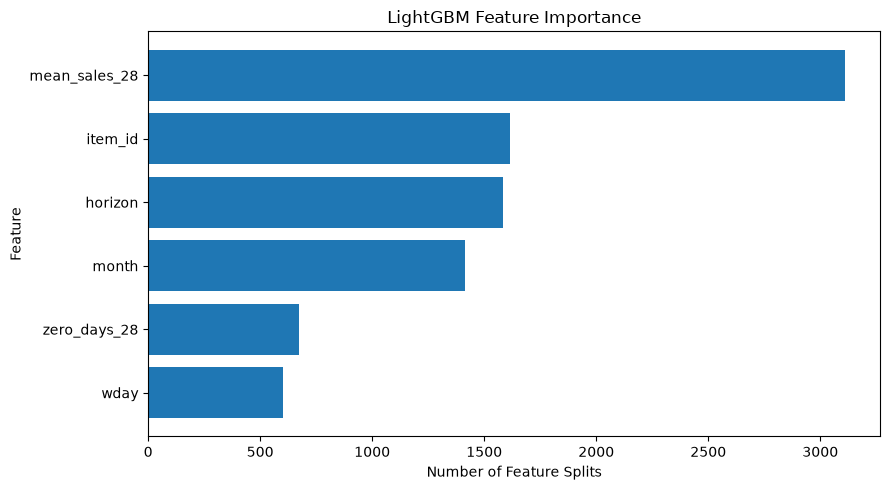

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "feature": MODEL_FEATURES,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.gca().invert_yaxis()

plt.title("LightGBM Feature Importance")
plt.xlabel("Number of Feature Splits")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [22]:

product_results = validation_full[
    ["item_id", "day_number", "units_sold"]
].copy()

product_results["prediction"] = val_predictions

product_results["absolute_error"] = (
    product_results["units_sold"]
    - product_results["prediction"]
).abs()

product_summary = (
    product_results.groupby("item_id")
    .agg(
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum")
    )
    .reset_index()
)

product_summary["wape_pct"] = (
    product_summary["absolute_error"]
    / product_summary["actual_units"].replace(0, float("nan"))
    * 100
)

display(
    product_summary.sort_values(
        "absolute_error",
        ascending=False
    ).head(10)
)

print(
    "Products with zero actual demand:",
    (product_summary["actual_units"] == 0).sum()
)


,item_id,actual_units,predicted_units,absolute_error,wape_pct
80,FOODS_1_082,318,171.194523,165.146737,51.932936
3,FOODS_1_004,0,154.690221,154.690221,NaN
17,FOODS_1_019,218,131.373951,144.966091,66.498207
97,FOODS_1_099,310,303.945511,135.099975,43.580637
16,FOODS_1_018,320,273.176849,129.956788,40.611496
83,FOODS_1_085,331,340.844071,123.399301,37.280756
84,FOODS_1_086,166,112.147075,114.647928,69.065017
44,FOODS_1_046,241,208.180388,99.779811,41.402411
30,FOODS_1_032,72,109.247822,84.691824,117.627533
40,FOODS_1_042,111,99.913014,73.781609,66.469918


Products with zero actual demand: 14


In [23]:

import numpy as np
import pandas as pd

def build_examples_v2(origin):

    # Only historical records available at the origin.
    past = df[
        (df["day_number"] > origin - 28)
        & (df["day_number"] <= origin)
    ].copy()

    # Sort product histories chronologically.
    past = past.sort_values(
        ["store_id", "item_id", "day_number"]
    )

    def summarize_product(group):
        sales = group["units_sold"].to_numpy()

        last_7 = sales[-7:]
        last_14 = sales[-14:]
        previous_14 = sales[-28:-14]

        nonzero_positions = np.flatnonzero(sales > 0)

        days_since_last_sale = (
            len(sales) - 1 - nonzero_positions[-1]
            if len(nonzero_positions) > 0
            else 28
        )

        return pd.Series({
            "mean_sales_7": last_7.mean(),
            "mean_sales_14": last_14.mean(),
            "mean_sales_28": sales.mean(),
            "std_sales_28": sales.std(),
            "zero_days_28": (sales == 0).sum(),
            "sales_trend_28": (
                last_14.mean() - previous_14.mean()
            ),
            "days_since_last_sale": days_since_last_sale
        })

    past_features = (
        past.groupby(["store_id", "item_id"])
        .apply(
            summarize_product,
            include_groups=False
        )
        .reset_index()
    )

    # Future sales are labels, not historical features.
    future = df[
        (df["day_number"] > origin)
        & (df["day_number"] <= origin + 28)
    ][
        ["store_id", "item_id", "day_number",
         "wday", "month", "units_sold"]
    ].copy()

    future["horizon"] = future["day_number"] - origin

    examples = future.merge(
        past_features,
        on=["store_id", "item_id"],
        how="left",
        validate="many_to_one"
    )

    examples["forecast_origin"] = origin

    return examples


In [24]:

train_v2 = pd.concat(
    [
        build_examples_v2(origin)
        for origin in TRAIN_ORIGINS_FULL
    ],
    ignore_index=True
)

validation_v2 = build_examples_v2(1857)

NEW_FEATURES = [
    "mean_sales_7",
    "mean_sales_14",
    "mean_sales_28",
    "std_sales_28",
    "zero_days_28",
    "sales_trend_28",
    "days_since_last_sale",
]

assert len(train_v2) == 148400
assert len(validation_v2) == 2800

assert train_v2["day_number"].max() <= 1857
assert validation_v2["day_number"].min() == 1858
assert validation_v2["day_number"].max() == 1885

assert train_v2[NEW_FEATURES].notna().all().all()
assert validation_v2[NEW_FEATURES].notna().all().all()

print("LightGBM Version 2 features created!")
print("Training records:", len(train_v2))
print("Validation records:", len(validation_v2))

display(
    train_v2[
        ["item_id", "forecast_origin",
         "mean_sales_7", "mean_sales_28",
         "sales_trend_28",
         "days_since_last_sale"]
    ].head(10)
)


LightGBM Version 2 features created!
Training records: 148400
Validation records: 2800


,item_id,forecast_origin,mean_sales_7,mean_sales_28,sales_trend_28,days_since_last_sale
0,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
1,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
2,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
3,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
4,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
5,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
6,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
7,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
8,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0
9,FOODS_1_001,365,0.428571,0.678571,0.214286,0.0


In [25]:

import lightgbm as lgb
import numpy as np
import pandas as pd

MODEL_FEATURES_V2 = [
    "item_id",
    "wday",
    "month",
    "horizon",
    "mean_sales_7",
    "mean_sales_14",
    "mean_sales_28",
    "std_sales_28",
    "zero_days_28",
    "sales_trend_28",
    "days_since_last_sale",
]

# Separate model inputs from actual sales.
X_train_v2 = train_v2[MODEL_FEATURES_V2].copy()
y_train_v2 = train_v2["units_sold"].copy()

X_val_v2 = validation_v2[MODEL_FEATURES_V2].copy()
y_val_v2 = validation_v2["units_sold"].copy()

# Treat product IDs as categories.
X_train_v2["item_id"] = X_train_v2["item_id"].astype(
    "category"
)

X_val_v2["item_id"] = pd.Categorical(
    X_val_v2["item_id"],
    categories=X_train_v2["item_id"].cat.categories
)

# Same hyperparameters as Version 1.
model_v2 = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# Train using historical examples.
model_v2.fit(
    X_train_v2,
    y_train_v2,
    categorical_feature=["item_id"]
)

# Forecast the validation window.
val_predictions_v2 = model_v2.predict(X_val_v2)

# Demand forecasts must not be negative.
val_predictions_v2 = np.maximum(
    val_predictions_v2,
    0
)

print("LightGBM Version 2 training completed!")
print("Training records:", len(X_train_v2))
print("Validation predictions:", len(val_predictions_v2))

print("\nFirst 10 predictions:")
print(np.round(val_predictions_v2[:10], 2))


LightGBM Version 2 training completed!
Training records: 148400
Validation predictions: 2800

First 10 predictions:
[0.5  0.5  0.5  0.51 0.62 0.77 0.68 0.52 0.52 0.52]


In [26]:

# Reuse our existing evaluation function.
v2_wape, v2_bias = calculate_metrics(
    y_val_v2,
    val_predictions_v2
)

comparison_v2 = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM V1",
        "LightGBM V2"
    ],
    "WAPE (%)": [
        round(baseline_wape, 2),
        round(lgb_wape, 2),
        round(v2_wape, 2)
    ],
    "Bias (%)": [
        round(baseline_bias, 2),
        round(lgb_bias, 2),
        round(v2_bias, 2)
    ]
})

display(comparison_v2)

print(
    "\nV2 improvement over V1:",
    round(lgb_wape - v2_wape, 2),
    "WAPE percentage points"
)


,Model,WAPE (%),Bias (%)
0,Seasonal Naive,87.78,-13.73
1,LightGBM V1,84.10,-0.75
2,LightGBM V2,82.01,3.10



V2 improvement over V1: 2.1 WAPE percentage points


In [27]:

BACKTEST_ORIGINS = [1773, 1801, 1829, 1857]
HORIZON = 28

backtest_windows = []

for origin in BACKTEST_ORIGINS:
    backtest_windows.append({
        "forecast_origin": origin,
        "forecast_start": origin + 1,
        "forecast_end": origin + HORIZON,
        "history_available_through": origin
    })

backtest_plan = pd.DataFrame(backtest_windows)

display(backtest_plan)

assert backtest_plan["forecast_end"].max() == 1885
assert backtest_plan["forecast_end"].is_monotonic_increasing

print("Backtest windows validated!")
print("Number of windows:", len(backtest_plan))
print("Forecasts per window:", 100 * HORIZON)


,forecast_origin,forecast_start,forecast_end,history_available_through
0,1773,1774,1801,1773
1,1801,1802,1829,1801
2,1829,1830,1857,1829
3,1857,1858,1885,1857


Backtest windows validated!
Number of windows: 4
Forecasts per window: 2800


In [28]:

import numpy as np
import pandas as pd

BACKTEST_ORIGINS = [1773, 1801, 1829, 1857]
HORIZON = 28

baseline_backtest_results = []

for origin in BACKTEST_ORIGINS:

    # Actual sales during the next 28 days.
    future = df[
        df["day_number"].between(
            origin + 1,
            origin + HORIZON
        )
    ][
        ["store_id", "item_id",
         "day_number", "units_sold"]
    ].copy()

    future["week_position"] = (
        (future["day_number"] - origin - 1) % 7
    )

    # The last seven days known at this origin.
    last_week = df[
        df["day_number"].between(
            origin - 6,
            origin
        )
    ][
        ["store_id", "item_id",
         "day_number", "units_sold"]
    ].copy()

    last_week["week_position"] = (
        last_week["day_number"] - (origin - 6)
    )

    # Repeat the last observed week.
    comparison = future.merge(
        last_week[
            ["store_id", "item_id",
             "week_position", "units_sold"]
        ],
        on=["store_id", "item_id", "week_position"],
        how="left",
        suffixes=("_actual", "_predicted"),
        validate="many_to_one"
    )

    assert len(comparison) == 2800
    assert comparison["units_sold_predicted"].notna().all()

    wape, bias = calculate_metrics(
        comparison["units_sold_actual"],
        comparison["units_sold_predicted"]
    )

    baseline_backtest_results.append({
        "forecast_origin": origin,
        "model": "Seasonal Naive",
        "wape_pct": round(wape, 2),
        "bias_pct": round(bias, 2)
    })

baseline_backtests = pd.DataFrame(
    baseline_backtest_results
)

display(baseline_backtests)

print(
    "Average window WAPE:",
    round(baseline_backtests["wape_pct"].mean(), 2),
    "%"
)

print(
    "Average window bias:",
    round(baseline_backtests["bias_pct"].mean(), 2),
    "%"
)


,forecast_origin,model,wape_pct,bias_pct
0,1773,Seasonal Naive,98.06,-22.79
1,1801,Seasonal Naive,94.03,-15.28
2,1829,Seasonal Naive,106.43,-2.94
3,1857,Seasonal Naive,87.78,-13.73


Average window WAPE: 96.57 %
Average window bias: -13.68 %


In [29]:

import lightgbm as lgb
import numpy as np
import pandas as pd

BACKTEST_ORIGIN = 1773

# Keep only training examples whose targets
# were already known by day 1773.
train_bt_v1 = train_full[
    train_full["day_number"] <= BACKTEST_ORIGIN
].copy()

train_bt_v2 = train_v2[
    train_v2["day_number"] <= BACKTEST_ORIGIN
].copy()

# Create predictions for days 1774–1801.
val_bt_v1 = build_examples(BACKTEST_ORIGIN)
val_bt_v2 = build_examples_v2(BACKTEST_ORIGIN)

assert train_bt_v1["day_number"].max() <= BACKTEST_ORIGIN
assert train_bt_v2["day_number"].max() <= BACKTEST_ORIGIN

assert val_bt_v1["day_number"].min() == 1774
assert val_bt_v1["day_number"].max() == 1801

assert len(val_bt_v1) == len(val_bt_v2) == 2800

# The two models must predict identical product-days.
KEYS = ["store_id", "item_id", "day_number"]

assert val_bt_v1[KEYS].equals(val_bt_v2[KEYS])
assert val_bt_v1["units_sold"].equals(
    val_bt_v2["units_sold"]
)

print("Historical training cutoff verified!")
print("V1 training rows:", len(train_bt_v1))
print("V2 training rows:", len(train_bt_v2))
print("Forecast origin:", BACKTEST_ORIGIN)


Historical training cutoff verified!
V1 training rows: 140800
V2 training rows: 140800
Forecast origin: 1773


In [30]:

def fit_backtest_model(training, validation, feature_names):

    X_train = training[feature_names].copy()
    X_val = validation[feature_names].copy()

    X_train["item_id"] = X_train["item_id"].astype(
        "category"
    )

    X_val["item_id"] = pd.Categorical(
        X_val["item_id"],
        categories=X_train["item_id"].cat.categories
    )

    model_bt = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    model_bt.fit(
        X_train,
        training["units_sold"],
        categorical_feature=["item_id"]
    )

    predictions = np.maximum(
        model_bt.predict(X_val),
        0
    )

    return predictions


# Retrain Version 1 using only historical information.
pred_bt_v1 = fit_backtest_model(
    train_bt_v1,
    val_bt_v1,
    MODEL_FEATURES
)

# Retrain Version 2 using the same historical cutoff.
pred_bt_v2 = fit_backtest_model(
    train_bt_v2,
    val_bt_v2,
    MODEL_FEATURES_V2
)

v1_bt_wape, v1_bt_bias = calculate_metrics(
    val_bt_v1["units_sold"],
    pred_bt_v1
)

v2_bt_wape, v2_bt_bias = calculate_metrics(
    val_bt_v2["units_sold"],
    pred_bt_v2
)

first_backtest_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM V1",
        "LightGBM V2"
    ],
    "WAPE (%)": [
        98.06,
        round(v1_bt_wape, 2),
        round(v2_bt_wape, 2)
    ],
    "Bias (%)": [
        -22.79,
        round(v1_bt_bias, 2),
        round(v2_bt_bias, 2)
    ]
})

display(first_backtest_comparison)


,Model,WAPE (%),Bias (%)
0,Seasonal Naive,98.06,-22.79
1,LightGBM V1,90.62,-9.00
2,LightGBM V2,90.59,-2.67


In [31]:

BACKTEST_ORIGINS = [1773, 1801, 1829, 1857]

all_backtest_results = []

for origin in BACKTEST_ORIGINS:

    print(f"\nRunning backtest at origin d_{origin}...")

    # Only use training labels observed by this origin.
    train_v1_bt = train_full[
        train_full["day_number"] <= origin
    ].copy()

    train_v2_bt = train_v2[
        train_v2["day_number"] <= origin
    ].copy()

    # Create forecast-origin-safe validation features.
    val_v1_bt = build_examples(origin)
    val_v2_bt = build_examples_v2(origin)

    # Check chronological separation.
    assert train_v1_bt["day_number"].max() <= origin
    assert train_v2_bt["day_number"].max() <= origin

    # Both models must predict the same product-days.
    keys = ["store_id", "item_id", "day_number"]

    assert val_v1_bt[keys].equals(val_v2_bt[keys])
    assert val_v1_bt["units_sold"].equals(
        val_v2_bt["units_sold"]
    )

    # Train and forecast using Version 1.
    predictions_v1 = fit_backtest_model(
        train_v1_bt,
        val_v1_bt,
        MODEL_FEATURES
    )

    # Train and forecast using Version 2.
    predictions_v2 = fit_backtest_model(
        train_v2_bt,
        val_v2_bt,
        MODEL_FEATURES_V2
    )

    # Evaluate both.
    for model_name, predictions in [
        ("LightGBM V1", predictions_v1),
        ("LightGBM V2", predictions_v2)
    ]:
        actual = val_v1_bt["units_sold"].to_numpy()

        wape, bias = calculate_metrics(
            actual,
            predictions
        )

        all_backtest_results.append({
            "forecast_origin": origin,
            "model": model_name,
            "wape_pct": round(wape, 2),
            "bias_pct": round(bias, 2),
            "actual_units": float(actual.sum()),
            "absolute_error": float(
                np.abs(actual - predictions).sum()
            ),
            "signed_error": float(
                (predictions - actual).sum()
            )
        })

    print(f"Completed origin d_{origin}")

ml_backtests = pd.DataFrame(all_backtest_results)

display(ml_backtests)



Running backtest at origin d_1773...
Completed origin d_1773

Running backtest at origin d_1801...
Completed origin d_1801

Running backtest at origin d_1829...
Completed origin d_1829

Running backtest at origin d_1857...
Completed origin d_1857


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,LightGBM V1,90.62,-9.00,4538.0,4112.155470,-408.365825
1,1773,LightGBM V2,90.59,-2.67,4538.0,4111.093389,-121.072318
2,1801,LightGBM V1,83.69,4.98,4155.0,3477.494246,206.727161
3,1801,LightGBM V2,79.65,-2.29,4155.0,3309.280992,-95.094864
4,1829,LightGBM V1,96.76,10.30,4290.0,4150.889099,441.933384
5,1829,LightGBM V2,97.04,9.14,4290.0,4162.864743,392.016561
6,1857,LightGBM V1,84.10,-0.75,4516.0,3798.155169,-33.715333
7,1857,LightGBM V2,82.01,3.10,4516.0,3703.530349,139.992405


In [32]:

# Combine previously calculated Seasonal Naive results
# with the new LightGBM results.

baseline_summary = baseline_backtests[
    ["forecast_origin", "model",
     "wape_pct", "bias_pct"]
].copy()

ml_summary = ml_backtests[
    ["forecast_origin", "model",
     "wape_pct", "bias_pct"]
].copy()

combined_backtests = pd.concat(
    [baseline_summary, ml_summary],
    ignore_index=True
)

# Show WAPE for each model at each forecast origin.
wape_table = combined_backtests.pivot(
    index="forecast_origin",
    columns="model",
    values="wape_pct"
)

display(wape_table)

# Report the unweighted mean of the four window WAPEs.
average_wape = (
    combined_backtests.groupby("model")["wape_pct"]
    .mean()
    .sort_values()
)

print("\nAverage WAPE across four windows:")
display(average_wape)


model,LightGBM V1,LightGBM V2,Seasonal Naive
forecast_origin,,,
1773,90.62,90.59,98.06
1801,83.69,79.65,94.03
1829,96.76,97.04,106.43
1857,84.10,82.01,87.78



Average WAPE across four windows:


model
LightGBM V2       87.3225
LightGBM V1       88.7925
Seasonal Naive    96.5750
Name: wape_pct, dtype: float64

In [33]:

# Calculate raw error totals for Seasonal Naive
# over the same four historical windows.

baseline_totals = []

for origin in BACKTEST_ORIGINS:

    future = df[
        df["day_number"].between(origin + 1, origin + 28)
    ][["store_id", "item_id", "day_number", "units_sold"]].copy()

    future["week_position"] = (
        future["day_number"] - origin - 1
    ) % 7

    previous_week = df[
        df["day_number"].between(origin - 6, origin)
    ][["store_id", "item_id", "day_number", "units_sold"]].copy()

    previous_week["week_position"] = (
        previous_week["day_number"] - (origin - 6)
    )

    merged = future.merge(
        previous_week[
            ["store_id", "item_id",
             "week_position", "units_sold"]
        ],
        on=["store_id", "item_id", "week_position"],
        suffixes=("_actual", "_predicted"),
        validate="many_to_one"
    )

    actual = merged["units_sold_actual"]
    predicted = merged["units_sold_predicted"]

    baseline_totals.append({
        "forecast_origin": origin,
        "model": "Seasonal Naive",
        "actual_units": actual.sum(),
        "absolute_error": (actual - predicted).abs().sum(),
        "signed_error": (predicted - actual).sum()
    })

baseline_raw = pd.DataFrame(baseline_totals)

# Combine the baseline with LightGBM's saved results.
all_results = pd.concat([
    baseline_raw,
    ml_backtests[
        ["forecast_origin", "model", "actual_units",
         "absolute_error", "signed_error"]
    ]
], ignore_index=True)

# Pool the underlying units and errors.
summary = (
    all_results.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

summary["pooled_wape_pct"] = (
    100 * summary["absolute_error"]
    / summary["actual_units"]
)

summary["pooled_bias_pct"] = (
    100 * summary["signed_error"]
    / summary["actual_units"]
)

summary = summary.sort_values("pooled_wape_pct")

display(summary.round(2))


,actual_units,absolute_error,signed_error,pooled_wape_pct,pooled_bias_pct
model,,,,,
LightGBM V2,17499.0,15286.77,315.84,87.36,1.80
LightGBM V1,17499.0,15538.69,206.58,88.80,1.18
Seasonal Naive,17499.0,16887.00,-2415.00,96.50,-13.80


In [34]:

# Final test forecast origin
FINAL_ORIGIN = 1885

# Include our existing training examples and
# the recently completed validation window.
recent_examples = build_examples_v2(1857)

final_train = pd.concat(
    [train_v2, recent_examples],
    ignore_index=True
)

# Create final-test prediction rows.
final_test = build_examples_v2(FINAL_ORIGIN)

# Verify no future sales enter model training.
assert final_train["day_number"].max() <= FINAL_ORIGIN

assert final_test["day_number"].min() == 1886
assert final_test["day_number"].max() == 1913

assert len(final_test) == 2800

# Check for repeated training examples.
assert not final_train.duplicated(
    ["store_id", "item_id", "forecast_origin", "horizon"]
).any()

print("Final-test preparation successful!")
print("Training records:", len(final_train))
print("Test records:", len(final_test))
print("Latest training target:", final_train["day_number"].max())
print("Test target range:",
      final_test["day_number"].min(),
      "to",
      final_test["day_number"].max())


Final-test preparation successful!
Training records: 151200
Test records: 2800
Latest training target: 1885
Test target range: 1886 to 1913


In [35]:

# Reuse the same V2 features and model settings
# selected during backtesting.
final_predictions = fit_backtest_model(
    final_train,
    final_test,
    MODEL_FEATURES_V2
)

assert len(final_predictions) == 2800
assert np.isfinite(final_predictions).all()
assert (final_predictions >= 0).all()

print("Final LightGBM V2 forecast generated!")
print("Predictions:", len(final_predictions))
print("First 10 predictions:")
print(np.round(final_predictions[:10], 2))


Final LightGBM V2 forecast generated!
Predictions: 2800
First 10 predictions:
[0.73 0.73 0.73 0.74 0.84 1.02 0.91 0.75 0.75 0.75]


In [36]:

final_wape, final_bias = calculate_metrics(
    final_test["units_sold"],
    final_predictions
)

print("=== LIGHTGBM V2 FINAL TEST ===")
print("Products:", final_test["item_id"].nunique())
print("Forecast days: 28")
print("Actual units:", final_test["units_sold"].sum())
print("WAPE:", round(final_wape, 2), "%")
print("Bias:", round(final_bias, 2), "%")


=== LIGHTGBM V2 FINAL TEST ===
Products: 100
Forecast days: 28
Actual units: 4014
WAPE: 87.44 %
Bias: 22.47 %


In [37]:

# Final-test Seasonal Naive benchmark
# Forecast origin = day 1885.

origin = 1885

# Actual sales for days 1886–1913.
future = df[
    df["day_number"].between(
        origin + 1,
        origin + 28
    )
][
    ["store_id", "item_id",
     "day_number", "units_sold"]
].copy()

future["week_position"] = (
    future["day_number"] - origin - 1
) % 7

# Last observed week: days 1879–1885.
last_week = df[
    df["day_number"].between(
        origin - 6,
        origin
    )
][
    ["store_id", "item_id",
     "day_number", "units_sold"]
].copy()

last_week["week_position"] = (
    last_week["day_number"] - (origin - 6)
)

# Repeat the last week's sales four times.
baseline_final = future.merge(
    last_week[
        ["store_id", "item_id",
         "week_position", "units_sold"]
    ],
    on=["store_id", "item_id", "week_position"],
    how="left",
    suffixes=("_actual", "_predicted"),
    validate="many_to_one"
)

assert len(baseline_final) == 2800
assert baseline_final["units_sold_predicted"].notna().all()

# Evaluate against the same final-test actuals.
baseline_final_wape, baseline_final_bias = calculate_metrics(
    baseline_final["units_sold_actual"],
    baseline_final["units_sold_predicted"]
)

final_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM V2"
    ],
    "WAPE (%)": [
        round(baseline_final_wape, 2),
        round(final_wape, 2)
    ],
    "Bias (%)": [
        round(baseline_final_bias, 2),
        round(final_bias, 2)
    ]
})

display(final_comparison)

print(
    "Final-test WAPE improvement (Naive - V2):",
    round(baseline_final_wape - final_wape, 2),
    "percentage points"
)


,Model,WAPE (%),Bias (%)
0,Seasonal Naive,111.11,31.84
1,LightGBM V2,87.44,22.47


Final-test WAPE improvement (Naive - V2): 23.67 percentage points


In [38]:

import pandas as pd
import numpy as np

# Analyze historical sales only through validation origin.
# This keeps the final test outside our model-development analysis.
DEMAND_ANALYSIS_ORIGIN = 1857

historical_sales = df[
    df["day_number"].between(
        DEMAND_ANALYSIS_ORIGIN - 89,
        DEMAND_ANALYSIS_ORIGIN
    )
].copy()

# Summarize 90 days of sales for each product.
demand_profiles = (
    historical_sales.groupby(["store_id", "item_id"])
    .agg(
        total_units=("units_sold", "sum"),
        average_daily_sales=("units_sold", "mean"),
        selling_days=("units_sold", lambda x: (x > 0).sum()),
        zero_sales_days=("units_sold", lambda x: (x == 0).sum()),
        max_daily_sales=("units_sold", "max")
    )
    .reset_index()
)

# Fraction of days when the product actually sold.
demand_profiles["selling_day_rate"] = (
    demand_profiles["selling_days"] / 90
)

# Initial, exploratory demand segmentation.
def classify_demand(rate):
    if rate >= 0.80:
        return "Regular demand"
    elif rate >= 0.30:
        return "Intermittent demand"
    else:
        return "Sparse demand"

demand_profiles["demand_type"] = (
    demand_profiles["selling_day_rate"]
    .apply(classify_demand)
)

print("Total products analyzed:", len(demand_profiles))

print("\nDemand-type distribution:")
display(
    demand_profiles["demand_type"]
    .value_counts()
    .rename_axis("Demand Type")
    .reset_index(name="Number of Products")
)

print("\nSample product demand profiles:")
display(
    demand_profiles[
        ["item_id", "average_daily_sales",
         "selling_days", "zero_sales_days",
         "selling_day_rate", "demand_type"]
    ].head(15)
)


Total products analyzed: 100

Demand-type distribution:


,Demand Type,Number of Products
0,Intermittent demand,61
1,Sparse demand,29
2,Regular demand,10



Sample product demand profiles:


,item_id,average_daily_sales,selling_days,zero_sales_days,selling_day_rate,demand_type
0,FOODS_1_001,0.677778,36,54,0.400000,Intermittent demand
1,FOODS_1_002,0.411111,22,68,0.244444,Sparse demand
2,FOODS_1_003,0.755556,34,56,0.377778,Intermittent demand
3,FOODS_1_004,4.166667,44,46,0.488889,Intermittent demand
4,FOODS_1_005,1.722222,59,31,0.655556,Intermittent demand
5,FOODS_1_006,1.822222,60,30,0.666667,Intermittent demand
6,FOODS_1_008,0.311111,18,72,0.200000,Sparse demand
7,FOODS_1_009,0.966667,36,54,0.400000,Intermittent demand
8,FOODS_1_010,0.222222,16,74,0.177778,Sparse demand
9,FOODS_1_011,0.766667,33,57,0.366667,Intermittent demand


In [39]:

# Use our existing validation predictions from V2.
# These cover days 1858–1885.

error_analysis = validation_v2[
    ["store_id", "item_id", "units_sold"]
].copy()

error_analysis["prediction"] = val_predictions_v2

# Attach demand categories defined using
# history through day 1857.
error_analysis = error_analysis.merge(
    demand_profiles[
        ["store_id", "item_id", "demand_type"]
    ],
    on=["store_id", "item_id"],
    how="left",
    validate="many_to_one"
)

assert len(error_analysis) == 2800
assert error_analysis["demand_type"].notna().all()

error_analysis["absolute_error"] = (
    error_analysis["units_sold"]
    - error_analysis["prediction"]
).abs()

error_analysis["signed_error"] = (
    error_analysis["prediction"]
    - error_analysis["units_sold"]
)

# Calculate accuracy for each demand category.
category_errors = (
    error_analysis.groupby("demand_type")
    .agg(
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum"),
        observations=("item_id", "size")
    )
    .reset_index()
)

category_errors["wape_pct"] = (
    category_errors["absolute_error"]
    / category_errors["actual_units"].replace(0, np.nan)
    * 100
)

category_errors["bias_pct"] = (
    category_errors["signed_error"]
    / category_errors["actual_units"].replace(0, np.nan)
    * 100
)

category_errors["error_share_pct"] = (
    category_errors["absolute_error"]
    / category_errors["absolute_error"].sum()
    * 100
)

display(category_errors.round(2))


,demand_type,actual_units,predicted_units,absolute_error,signed_error,observations,wape_pct,bias_pct,error_share_pct
0,Intermittent demand,2164,2401.78,2256.48,237.78,1708,104.27,10.99,60.93
1,Regular demand,1852,1818.32,909.16,-33.68,280,49.09,-1.82,24.55
2,Sparse demand,500,435.89,537.89,-64.11,812,107.58,-12.82,14.52


In [40]:

import numpy as np
import pandas as pd

def croston_forecast(sales, horizon=28, alpha=0.1):
    """
    Estimate intermittent demand using Croston's method
    and the SBA bias correction.

    sales: historical daily sales available at forecast origin
    horizon: number of future days to forecast
    alpha: smoothing parameter between 0 and 1
    """

    sales = np.asarray(sales, dtype=float)

    if len(sales) == 0:
        raise ValueError("Sales history cannot be empty.")

    if not 0 < alpha <= 1:
        raise ValueError("alpha must be between 0 and 1.")

    if np.any(sales < 0):
        raise ValueError("Sales cannot be negative.")

    nonzero_indices = np.flatnonzero(sales > 0)

    if len(nonzero_indices) == 0:
        return (
            np.zeros(horizon),
            np.zeros(horizon)
        )

    # Initial demand size and interval.
    first_sale = nonzero_indices[0]

    demand_size = sales[first_sale]
    demand_interval = first_sale + 1

    previous_sale = first_sale

    # Update estimates only when a sale occurs.
    for sale_index in nonzero_indices[1:]:

        observed_demand = sales[sale_index]

        observed_interval = sale_index - previous_sale

        demand_size = (
            alpha * observed_demand
            + (1 - alpha) * demand_size
        )

        demand_interval = (
            alpha * observed_interval
            + (1 - alpha) * demand_interval
        )

        previous_sale = sale_index

    # Croston estimates average demand per day.
    croston_rate = demand_size / demand_interval

    # SBA correction for Croston's positive bias.
    sba_rate = (1 - alpha / 2) * croston_rate

    return (
        np.full(horizon, croston_rate),
        np.full(horizon, sba_rate)
    )



In [41]:

example_sales = [
    0, 0, 6, 0, 0, 3, 0,
    0, 0, 9, 0, 0, 0, 6
]

croston_pred, sba_pred = croston_forecast(
    example_sales,
    horizon=7,
    alpha=0.1
)

print("Historical sales:", example_sales)
print("Croston forecast:", np.round(croston_pred, 2))
print("SBA forecast:", np.round(sba_pred, 2))


Historical sales: [0, 0, 6, 0, 0, 3, 0, 0, 0, 9, 0, 0, 0, 6]
Croston forecast: [1.89 1.89 1.89 1.89 1.89 1.89 1.89]
SBA forecast: [1.79 1.79 1.79 1.79 1.79 1.79 1.79]


In [42]:

CROSTON_BACKTEST_ORIGINS = [1773, 1801, 1829, 1857]

croston_results = []

for origin in CROSTON_BACKTEST_ORIGINS:

    print(f"Testing origin d_{origin}...")

    # Historical data: only the 90 days before
    # and including the forecast origin.
    history = df[
        df["day_number"].between(origin - 89, origin)
    ].copy()

    # Future data: actual sales for evaluation only.
    future = df[
        df["day_number"].between(origin + 1, origin + 28)
    ].copy()

    actual = []
    predictions_croston = []
    predictions_sba = []

    for (store_id, item_id), product_history in history.groupby(
        ["store_id", "item_id"]
    ):

        product_history = product_history.sort_values(
            "day_number"
        )

        sales_history = product_history[
            "units_sold"
        ].to_numpy()

        assert len(sales_history) == 90

        croston_pred, sba_pred = croston_forecast(
            sales_history,
            horizon=28,
            alpha=0.1
        )

        product_future = future[
            (future["store_id"] == store_id)
            & (future["item_id"] == item_id)
        ].sort_values("day_number")

        assert len(product_future) == 28

        actual.extend(
            product_future["units_sold"].to_numpy()
        )

        predictions_croston.extend(croston_pred)
        predictions_sba.extend(sba_pred)

    actual = np.asarray(actual)

    for model_name, predictions in [
        ("Croston", predictions_croston),
        ("SBA", predictions_sba)
    ]:

        predictions = np.asarray(predictions)

        wape, bias = calculate_metrics(
            actual,
            predictions
        )

        croston_results.append({
            "forecast_origin": origin,
            "model": model_name,
            "wape_pct": round(wape, 2),
            "bias_pct": round(bias, 2),
            "actual_units": actual.sum(),
            "absolute_error": np.abs(
                actual - predictions
            ).sum(),
            "signed_error": (
                predictions - actual
            ).sum()
        })

croston_backtests = pd.DataFrame(croston_results)

print("\nCroston and SBA backtests completed!")
display(croston_backtests.round(2))


Testing origin d_1773...
Testing origin d_1801...
Testing origin d_1829...
Testing origin d_1857...

Croston and SBA backtests completed!


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,Croston,87.77,-20.80,4538,3983.10,-943.95
1,1773,SBA,87.36,-24.76,4538,3964.46,-1123.65
2,1801,Croston,85.44,4.82,4155,3549.95,200.22
3,1801,SBA,83.95,-0.42,4155,3488.06,-17.54
4,1829,Croston,95.12,1.85,4290,4080.70,79.51
5,1829,SBA,93.73,-3.24,4290,4020.85,-138.96
6,1857,Croston,95.89,4.71,4516,4330.36,212.78
7,1857,SBA,94.34,-0.52,4516,4260.26,-23.66


In [43]:

# Combine saved historical backtest results.
all_five_models = pd.concat(
    [
        all_results,
        croston_backtests[
            ["forecast_origin", "model",
             "actual_units", "absolute_error",
             "signed_error"]
        ]
    ],
    ignore_index=True
)

# Calculate pooled performance.
five_model_summary = (
    all_five_models.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

five_model_summary["pooled_wape_pct"] = (
    five_model_summary["absolute_error"]
    / five_model_summary["actual_units"]
    * 100
)

five_model_summary["pooled_bias_pct"] = (
    five_model_summary["signed_error"]
    / five_model_summary["actual_units"]
    * 100
)

five_model_summary = five_model_summary.sort_values(
    "pooled_wape_pct"
)

display(
    five_model_summary[
        ["pooled_wape_pct", "pooled_bias_pct"]
    ].round(2)
)


,pooled_wape_pct,pooled_bias_pct
model,,
LightGBM V2,87.36,1.80
LightGBM V1,88.80,1.18
SBA,89.91,-7.45
Croston,91.11,-2.58
Seasonal Naive,96.50,-13.80


In [44]:

# Compare SBA and LightGBM V2 on the development
# validation period only: d_1858–d_1885.

ORIGIN = 1857

# Use the already saved V2 validation predictions.
comparison = validation_v2[
    ["store_id", "item_id", "day_number", "units_sold"]
].copy()

comparison["lightgbm_prediction"] = val_predictions_v2

sba_records = []

# Build SBA predictions using history known at d_1857.
history = df[
    df["day_number"].between(ORIGIN - 89, ORIGIN)
].copy()

for (store_id, item_id), group in history.groupby(
    ["store_id", "item_id"]
):
    group = group.sort_values("day_number")

    _, sba_forecast = croston_forecast(
        group["units_sold"].to_numpy(),
        horizon=28,
        alpha=0.1
    )

    for day, forecast_value in zip(
        range(ORIGIN + 1, ORIGIN + 29),
        sba_forecast
    ):
        sba_records.append({
            "store_id": store_id,
            "item_id": item_id,
            "day_number": day,
            "sba_prediction": forecast_value
        })

sba_predictions = pd.DataFrame(sba_records)

comparison = comparison.merge(
    sba_predictions,
    on=["store_id", "item_id", "day_number"],
    how="left",
    validate="one_to_one"
)

comparison = comparison.merge(
    demand_profiles[
        ["store_id", "item_id", "demand_type"]
    ],
    on=["store_id", "item_id"],
    how="left",
    validate="many_to_one"
)

assert len(comparison) == 2800
assert comparison[
    ["lightgbm_prediction", "sba_prediction", "demand_type"]
].notna().all().all()

category_comparison = []

for demand_type, group in comparison.groupby("demand_type"):

    for model_name, prediction_col in [
        ("LightGBM V2", "lightgbm_prediction"),
        ("SBA", "sba_prediction")
    ]:

        actual = group["units_sold"].to_numpy()
        predicted = group[prediction_col].to_numpy()

        wape, bias = calculate_metrics(actual, predicted)

        category_comparison.append({
            "demand_type": demand_type,
            "model": model_name,
            "wape_pct": round(wape, 2),
            "bias_pct": round(bias, 2),
            "absolute_error": np.abs(
                actual - predicted
            ).sum()
        })

category_model_results = pd.DataFrame(
    category_comparison
)

display(
    category_model_results.sort_values(
        ["demand_type", "wape_pct"]
    ).round(2)
)


,demand_type,model,wape_pct,bias_pct,absolute_error
0,Intermittent demand,LightGBM V2,104.27,10.99,2256.48
1,Intermittent demand,SBA,122.31,15.73,2646.71
2,Regular demand,LightGBM V2,49.09,-1.82,909.16
3,Regular demand,SBA,53.67,-5.62,993.94
4,Sparse demand,LightGBM V2,107.58,-12.82,537.89
5,Sparse demand,SBA,123.92,-52.02,619.60


In [45]:

import lightgbm as lgb
import numpy as np
import pandas as pd

# Use the SAME training/validation data as V2.
# We are not touching the final test period.

poisson_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

poisson_model.fit(
    X_train_v2,
    y_train_v2,
    categorical_feature=["item_id"]
)

poisson_predictions = poisson_model.predict(X_val_v2)

assert len(poisson_predictions) == 2800
assert np.isfinite(poisson_predictions).all()
assert (poisson_predictions >= 0).all()

poisson_wape, poisson_bias = calculate_metrics(
    y_val_v2,
    poisson_predictions
)

poisson_comparison = pd.DataFrame({
    "Model": [
        "LightGBM V2",
        "Poisson LightGBM"
    ],
    "WAPE (%)": [
        round(v2_wape, 2),
        round(poisson_wape, 2)
    ],
    "Bias (%)": [
        round(v2_bias, 2),
        round(poisson_bias, 2)
    ]
})

display(poisson_comparison)

print(
    "Poisson WAPE improvement:",
    round(v2_wape - poisson_wape, 2),
    "percentage points"
)


,Model,WAPE (%),Bias (%)
0,LightGBM V2,82.01,3.1
1,Poisson LightGBM,79.44,0.5


Poisson WAPE improvement: 2.57 percentage points


In [46]:

import lightgbm as lgb
import numpy as np
import pandas as pd

poisson_backtest_results = []

for origin in BACKTEST_ORIGINS:

    print(f"Running Poisson backtest: d_{origin}")

    # Use only training labels known at this origin.
    train_bt = train_v2[
        train_v2["day_number"] <= origin
    ].copy()

    # Generate historical-origin-safe features.
    val_bt = build_examples_v2(origin)

    assert train_bt["day_number"].max() <= origin
    assert val_bt["day_number"].min() == origin + 1
    assert val_bt["day_number"].max() == origin + 28

    X_train_bt = train_bt[MODEL_FEATURES_V2].copy()
    X_val_bt = val_bt[MODEL_FEATURES_V2].copy()

    X_train_bt["item_id"] = X_train_bt["item_id"].astype(
        "category"
    )

    X_val_bt["item_id"] = pd.Categorical(
        X_val_bt["item_id"],
        categories=X_train_bt["item_id"].cat.categories
    )

    model_bt = lgb.LGBMRegressor(
        objective="poisson",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    model_bt.fit(
        X_train_bt,
        train_bt["units_sold"],
        categorical_feature=["item_id"]
    )

    predictions = model_bt.predict(X_val_bt)

    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

    actual = val_bt["units_sold"].to_numpy()

    wape, bias = calculate_metrics(
        actual,
        predictions
    )

    poisson_backtest_results.append({
        "forecast_origin": origin,
        "model": "Poisson LightGBM",
        "wape_pct": round(wape, 2),
        "bias_pct": round(bias, 2),
        "actual_units": float(actual.sum()),
        "absolute_error": float(
            np.abs(actual - predictions).sum()
        ),
        "signed_error": float(
            (predictions - actual).sum()
        )
    })

    print(
        f"Completed d_{origin}: "
        f"WAPE={wape:.2f}%, Bias={bias:.2f}%"
    )

poisson_backtests = pd.DataFrame(
    poisson_backtest_results
)

display(poisson_backtests)


Running Poisson backtest: d_1773
Completed d_1773: WAPE=89.42%, Bias=-6.88%
Running Poisson backtest: d_1801
Completed d_1801: WAPE=78.80%, Bias=-4.27%
Running Poisson backtest: d_1829
Completed d_1829: WAPE=95.96%, Bias=10.06%
Running Poisson backtest: d_1857
Completed d_1857: WAPE=79.44%, Bias=0.50%


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,Poisson LightGBM,89.42,-6.88,4538.0,4057.700317,-312.058442
1,1801,Poisson LightGBM,78.80,-4.27,4155.0,3273.939232,-177.370363
2,1829,Poisson LightGBM,95.96,10.06,4290.0,4116.772462,431.640252
3,1857,Poisson LightGBM,79.44,0.50,4516.0,3587.290484,22.397931


In [47]:

# Combine all historical model results.
six_model_results = pd.concat(
    [
        all_five_models,
        poisson_backtests[
            [
                "forecast_origin",
                "model",
                "actual_units",
                "absolute_error",
                "signed_error"
            ]
        ]
    ],
    ignore_index=True
)

six_model_summary = (
    six_model_results.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

six_model_summary["pooled_wape_pct"] = (
    six_model_summary["absolute_error"]
    / six_model_summary["actual_units"]
    * 100
)

six_model_summary["pooled_bias_pct"] = (
    six_model_summary["signed_error"]
    / six_model_summary["actual_units"]
    * 100
)

six_model_summary = six_model_summary.sort_values(
    "pooled_wape_pct"
)

display(
    six_model_summary[
        ["pooled_wape_pct", "pooled_bias_pct"]
    ].round(2)
)


,pooled_wape_pct,pooled_bias_pct
model,,
Poisson LightGBM,85.92,-0.20
LightGBM V2,87.36,1.80
LightGBM V1,88.80,1.18
SBA,89.91,-7.45
Croston,91.11,-2.58
Seasonal Naive,96.50,-13.80


In [48]:

# Compare Poisson and LightGBM V2 by demand category.
# Validation window: d_1858 through d_1885.

category_analysis = validation_v2[
    ["store_id", "item_id", "day_number", "units_sold"]
].copy()

# Predictions already created earlier in the notebook.
category_analysis["lightgbm_v2"] = val_predictions_v2
category_analysis["poisson"] = poisson_predictions

# Demand categories based on history through d_1857.
category_analysis = category_analysis.merge(
    demand_profiles[
        ["store_id", "item_id", "demand_type"]
    ],
    on=["store_id", "item_id"],
    how="left",
    validate="many_to_one"
)

assert len(category_analysis) == 2800
assert category_analysis["demand_type"].notna().all()

results = []

for demand_type, group in category_analysis.groupby(
    "demand_type"
):

    for model_name, prediction_column in [
        ("LightGBM V2", "lightgbm_v2"),
        ("Poisson LightGBM", "poisson")
    ]:

        actual = group["units_sold"].to_numpy()
        predicted = group[prediction_column].to_numpy()

        wape, bias = calculate_metrics(
            actual,
            predicted
        )

        results.append({
            "demand_type": demand_type,
            "model": model_name,
            "actual_units": actual.sum(),
            "predicted_units": predicted.sum(),
            "wape_pct": round(wape, 2),
            "bias_pct": round(bias, 2),
            "absolute_error": round(
                np.abs(actual - predicted).sum(), 2
            )
        })

poisson_category_results = pd.DataFrame(results)

display(
    poisson_category_results.sort_values(
        ["demand_type", "wape_pct"]
    )
)


,demand_type,model,actual_units,predicted_units,wape_pct,bias_pct,absolute_error
1,Intermittent demand,Poisson LightGBM,2164,2233.838810,97.80,3.23,2116.49
0,Intermittent demand,LightGBM V2,2164,2401.783937,104.27,10.99,2256.48
2,Regular demand,LightGBM V2,1852,1818.316329,49.09,-1.82,909.16
3,Regular demand,Poisson LightGBM,1852,1831.419534,49.52,-1.11,917.08
4,Sparse demand,LightGBM V2,500,435.892138,107.58,-12.82,537.89
5,Sparse demand,Poisson LightGBM,500,473.139587,110.74,-5.37,553.72


In [49]:

import numpy as np
import pandas as pd

# Use the category analysis we already created.
hybrid_results = category_analysis.copy()

# Routing rule based on our development analysis:
# Intermittent -> Poisson
# Regular/Sparse -> LightGBM V2
hybrid_results["hybrid_prediction"] = np.where(
    hybrid_results["demand_type"] == "Intermittent demand",
    hybrid_results["poisson"],
    hybrid_results["lightgbm_v2"]
)

# Calculate hybrid performance.
hybrid_wape, hybrid_bias = calculate_metrics(
    hybrid_results["units_sold"],
    hybrid_results["hybrid_prediction"]
)

# Compare against the two individual models.
hybrid_comparison = pd.DataFrame({
    "Model": [
        "LightGBM V2",
        "Poisson LightGBM",
        "Hybrid"
    ],
    "WAPE (%)": [
        round(v2_wape, 2),
        round(poisson_wape, 2),
        round(hybrid_wape, 2)
    ],
    "Bias (%)": [
        round(v2_bias, 2),
        round(poisson_bias, 2),
        round(hybrid_bias, 2)
    ]
})

display(hybrid_comparison)

print(
    "Hybrid improvement over Poisson:",
    round(poisson_wape - hybrid_wape, 2),
    "WAPE percentage points"
)

print(
    "Total absolute error:",
    round(
        np.abs(
            hybrid_results["units_sold"]
            - hybrid_results["hybrid_prediction"]
        ).sum(),
        2
    )
)


,Model,WAPE (%),Bias (%)
0,LightGBM V2,82.01,3.10
1,Poisson LightGBM,79.44,0.50
2,Hybrid,78.91,-0.62


Hybrid improvement over Poisson: 0.53 WAPE percentage points
Total absolute error: 3563.54


In [50]:

def classify_products_at_origin(origin):
    history = df[
        df["day_number"].between(origin - 89, origin)
    ].copy()

    profiles = (
        history.groupby(["store_id", "item_id"])
        .agg(
            selling_days=(
                "units_sold",
                lambda x: (x > 0).sum()
            ),
            observed_days=("units_sold", "size")
        )
        .reset_index()
    )

    assert (profiles["observed_days"] == 90).all()

    profiles["selling_day_rate"] = (
        profiles["selling_days"] / 90
    )

    profiles["demand_type"] = np.select(
        [
            profiles["selling_day_rate"] >= 0.80,
            profiles["selling_day_rate"] >= 0.30
        ],
        [
            "Regular demand",
            "Intermittent demand"
        ],
        default="Sparse demand"
    )

    return profiles[
        ["store_id", "item_id", "demand_type"]
    ]


In [51]:

hybrid_backtest_results = []

for origin in BACKTEST_ORIGINS:

    print(f"Running hybrid backtest at d_{origin}...")

    # Historical training records only.
    historical_train = train_v2[
        train_v2["day_number"] <= origin
    ].copy()

    validation = build_examples_v2(origin)

    assert historical_train["day_number"].max() <= origin
    assert validation["day_number"].min() == origin + 1
    assert validation["day_number"].max() == origin + 28

    X_train = historical_train[MODEL_FEATURES_V2].copy()
    X_val = validation[MODEL_FEATURES_V2].copy()

    X_train["item_id"] = X_train["item_id"].astype(
        "category"
    )

    X_val["item_id"] = pd.Categorical(
        X_val["item_id"],
        categories=X_train["item_id"].cat.categories
    )

    # Original LightGBM V2
    standard_model = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    standard_model.fit(
        X_train,
        historical_train["units_sold"],
        categorical_feature=["item_id"]
    )

    standard_predictions = np.maximum(
        standard_model.predict(X_val), 0
    )

    # Poisson LightGBM
    count_model = lgb.LGBMRegressor(
        objective="poisson",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    count_model.fit(
        X_train,
        historical_train["units_sold"],
        categorical_feature=["item_id"]
    )

    poisson_predictions_bt = count_model.predict(X_val)

    # Classify products using only history available
    # at this particular forecast origin.
    profiles = classify_products_at_origin(origin)

    comparison = validation[
        ["store_id", "item_id", "day_number", "units_sold"]
    ].copy()

    comparison["standard"] = standard_predictions
    comparison["poisson"] = poisson_predictions_bt

    comparison = comparison.merge(
        profiles,
        on=["store_id", "item_id"],
        how="left",
        validate="many_to_one"
    )

    assert len(comparison) == 2800
    assert comparison["demand_type"].notna().all()

    comparison["hybrid"] = np.where(
        comparison["demand_type"] == "Intermittent demand",
        comparison["poisson"],
        comparison["standard"]
    )

    actual = comparison["units_sold"].to_numpy()
    predicted = comparison["hybrid"].to_numpy()

    wape, bias = calculate_metrics(actual, predicted)

    hybrid_backtest_results.append({
        "forecast_origin": origin,
        "model": "Hybrid",
        "wape_pct": round(wape, 2),
        "bias_pct": round(bias, 2),
        "actual_units": float(actual.sum()),
        "absolute_error": float(
            np.abs(actual - predicted).sum()
        ),
        "signed_error": float(
            (predicted - actual).sum()
        )
    })

    print(
        f"Completed d_{origin}: "
        f"WAPE={wape:.2f}%, Bias={bias:.2f}%"
    )

hybrid_backtests = pd.DataFrame(hybrid_backtest_results)

display(hybrid_backtests)


Running hybrid backtest at d_1773...
Completed d_1773: WAPE=90.52%, Bias=-2.51%
Running hybrid backtest at d_1801...
Completed d_1801: WAPE=78.98%, Bias=-2.93%
Running hybrid backtest at d_1829...
Completed d_1829: WAPE=96.63%, Bias=7.71%
Running hybrid backtest at d_1857...
Completed d_1857: WAPE=78.91%, Bias=-0.62%


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,Hybrid,90.52,-2.51,4538.0,4107.926013,-113.908359
1,1801,Hybrid,78.98,-2.93,4155.0,3281.635478,-121.681525
2,1829,Hybrid,96.63,7.71,4290.0,4145.490832,330.675405
3,1857,Hybrid,78.91,-0.62,4516.0,3563.535786,-27.952723


In [52]:

comparison_results = pd.concat(
    [
        poisson_backtests,
        hybrid_backtests
    ],
    ignore_index=True
)

pooled_comparison = (
    comparison_results.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

pooled_comparison["wape_pct"] = (
    pooled_comparison["absolute_error"]
    / pooled_comparison["actual_units"]
    * 100
)

pooled_comparison["bias_pct"] = (
    pooled_comparison["signed_error"]
    / pooled_comparison["actual_units"]
    * 100
)

display(
    pooled_comparison[
        ["wape_pct", "bias_pct"]
    ].sort_values("wape_pct").round(2)
)


,wape_pct,bias_pct
model,,
Poisson LightGBM,85.92,-0.20
Hybrid,86.28,0.38


In [53]:

import numpy as np
import pandas as pd
import lightgbm as lgb

# A sale occurred if units_sold > 0.
# Otherwise, no sale occurred.

train_stage1 = train_v2.copy()
val_stage1 = validation_v2.copy()

train_stage1["sale_occurred"] = (
    train_stage1["units_sold"] > 0
).astype(int)

val_stage1["sale_occurred"] = (
    val_stage1["units_sold"] > 0
).astype(int)

print("Training examples:", len(train_stage1))
print("Validation examples:", len(val_stage1))

print("\nTraining target distribution:")
display(
    train_stage1["sale_occurred"]
    .value_counts()
    .rename(index={0: "No sale", 1: "Sale occurred"})
)

print("\nValidation target distribution:")
display(
    val_stage1["sale_occurred"]
    .value_counts()
    .rename(index={0: "No sale", 1: "Sale occurred"})
)


Training examples: 148400
Validation examples: 2800

Training target distribution:


sale_occurred
No sale          84428
Sale occurred    63972
Name: count, dtype: int64


Validation target distribution:


sale_occurred
No sale          1544
Sale occurred    1256
Name: count, dtype: int64

In [54]:

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss
)
import lightgbm as lgb
import numpy as np
import pandas as pd

# Use the V2 feature set.
X_train_stage1 = train_stage1[MODEL_FEATURES_V2].copy()
y_train_stage1 = train_stage1["sale_occurred"]

X_val_stage1 = val_stage1[MODEL_FEATURES_V2].copy()
y_val_stage1 = val_stage1["sale_occurred"]

# Tell LightGBM that product IDs are categories.
X_train_stage1["item_id"] = (
    X_train_stage1["item_id"].astype("category")
)

X_val_stage1["item_id"] = pd.Categorical(
    X_val_stage1["item_id"],
    categories=X_train_stage1["item_id"].cat.categories
)

# Train a binary classifier.
stage1_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

stage1_model.fit(
    X_train_stage1,
    y_train_stage1,
    categorical_feature=["item_id"]
)

# Predict probability of at least one sale.
sale_probabilities = stage1_model.predict_proba(
    X_val_stage1
)[:, 1]

# Check that probabilities are valid.
assert len(sale_probabilities) == 2800
assert np.isfinite(sale_probabilities).all()
assert ((sale_probabilities >= 0) &
        (sale_probabilities <= 1)).all()

# Evaluate probability predictions.
stage1_auc = roc_auc_score(
    y_val_stage1,
    sale_probabilities
)

stage1_brier = brier_score_loss(
    y_val_stage1,
    sale_probabilities
)

stage1_logloss = log_loss(
    y_val_stage1,
    sale_probabilities
)

print("Stage 1 training completed!")
print("ROC-AUC:", round(stage1_auc, 4))
print("Brier score:", round(stage1_brier, 4))
print("Log loss:", round(stage1_logloss, 4))

print("\nFirst 10 sale probabilities:")
print(np.round(sale_probabilities[:10], 3))


Stage 1 training completed!
ROC-AUC: 0.8075
Brier score: 0.1767
Log loss: 0.5185

First 10 sale probabilities:
[0.358 0.364 0.366 0.382 0.475 0.494 0.463 0.386 0.392 0.392]


In [55]:

# Train Stage 2 only on days when sales occurred.
# We want to learn the quantity conditional on a sale.

train_stage2 = train_v2[
    train_v2["units_sold"] > 0
].copy()

# Stage 2 must predict on ALL validation rows,
# not only days where a sale actually occurred.
val_stage2 = validation_v2.copy()

print("Original training rows:", len(train_v2))
print("Positive-sales training rows:", len(train_stage2))
print("Validation rows to predict:", len(val_stage2))

print("\nPositive-sales quantity statistics:")
display(
    train_stage2["units_sold"].describe()
)

assert (train_stage2["units_sold"] > 0).all()
assert len(train_stage2) == 63972
assert len(val_stage2) == 2800


Original training rows: 148400
Positive-sales training rows: 63972
Validation rows to predict: 2800

Positive-sales quantity statistics:


count    63972.000000
mean         3.795410
std          4.507951
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         72.000000
Name: units_sold, dtype: float64

In [56]:

# Prepare Stage 2 model inputs.
X_train_stage2 = train_stage2[
    MODEL_FEATURES_V2
].copy()

y_train_stage2 = train_stage2["units_sold"].copy()

X_val_stage2 = val_stage2[
    MODEL_FEATURES_V2
].copy()

# Keep categorical encoding consistent.
X_train_stage2["item_id"] = (
    X_train_stage2["item_id"].astype("category")
)

X_val_stage2["item_id"] = pd.Categorical(
    X_val_stage2["item_id"],
    categories=X_train_stage2["item_id"].cat.categories
)

# Poisson objective for positive sales quantities.
stage2_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

stage2_model.fit(
    X_train_stage2,
    y_train_stage2,
    categorical_feature=["item_id"]
)

# Predict conditional sales quantities on all
# validation product-days.
conditional_quantities = stage2_model.predict(
    X_val_stage2
)

assert len(conditional_quantities) == 2800
assert np.isfinite(conditional_quantities).all()
assert (conditional_quantities >= 0).all()

print("Stage 2 training completed!")

print("\nFirst 10 predicted conditional quantities:")
print(np.round(conditional_quantities[:10], 2))


Stage 2 training completed!

First 10 predicted conditional quantities:
[1.67 1.66 1.66 1.64 1.78 1.81 1.76 1.66 1.65 1.65]


In [57]:

# Expected demand = probability of sale
# multiplied by quantity conditional on a sale.

two_stage_predictions = (
    sale_probabilities * conditional_quantities
)

assert len(two_stage_predictions) == 2800
assert np.isfinite(two_stage_predictions).all()
assert (two_stage_predictions >= 0).all()

two_stage_wape, two_stage_bias = calculate_metrics(
    validation_v2["units_sold"],
    two_stage_predictions
)

two_stage_comparison = pd.DataFrame({
    "Model": [
        "LightGBM V2",
        "Poisson LightGBM",
        "Two-Stage Model"
    ],
    "WAPE (%)": [
        round(v2_wape, 2),
        round(poisson_wape, 2),
        round(two_stage_wape, 2)
    ],
    "Bias (%)": [
        round(v2_bias, 2),
        round(poisson_bias, 2),
        round(two_stage_bias, 2)
    ]
})

display(two_stage_comparison)

print("\nFirst 10 two-stage predictions:")
print(np.round(two_stage_predictions[:10], 2))


,Model,WAPE (%),Bias (%)
0,LightGBM V2,82.01,3.1
1,Poisson LightGBM,79.44,0.5
2,Two-Stage Model,79.10,1.2



First 10 two-stage predictions:
[0.6  0.6  0.61 0.63 0.85 0.89 0.81 0.64 0.65 0.65]


In [58]:

def fit_two_stage_model(training, validation):

    features = MODEL_FEATURES_V2

    X_train = training[features].copy()
    X_val = validation[features].copy()

    X_train["item_id"] = X_train["item_id"].astype(
        "category"
    )

    X_val["item_id"] = pd.Categorical(
        X_val["item_id"],
        categories=X_train["item_id"].cat.categories
    )

    # STAGE 1: Probability of at least one sale.
    y_binary = (
        training["units_sold"] > 0
    ).astype(int)

    classifier = lgb.LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    classifier.fit(
        X_train,
        y_binary,
        categorical_feature=["item_id"]
    )

    probabilities = classifier.predict_proba(
        X_val
    )[:, 1]

    # STAGE 2: Quantity when a sale occurs.
    positive_mask = training["units_sold"] > 0

    quantity_model = lgb.LGBMRegressor(
        objective="poisson",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    quantity_model.fit(
        X_train.loc[positive_mask],
        training.loc[positive_mask, "units_sold"],
        categorical_feature=["item_id"]
    )

    conditional_quantities = quantity_model.predict(
        X_val
    )

    # Expected demand = P(sale) × E(quantity | sale).
    predictions = probabilities * conditional_quantities

    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

    return predictions


In [59]:

two_stage_backtest_results = []

for origin in BACKTEST_ORIGINS:

    print(f"Running two-stage backtest: d_{origin}")

    historical_training = train_v2[
        train_v2["day_number"] <= origin
    ].copy()

    validation_window = build_examples_v2(origin)

    assert historical_training["day_number"].max() <= origin
    assert validation_window["day_number"].min() == origin + 1
    assert validation_window["day_number"].max() == origin + 28

    predictions = fit_two_stage_model(
        historical_training,
        validation_window
    )

    actual = validation_window["units_sold"].to_numpy()

    wape, bias = calculate_metrics(
        actual,
        predictions
    )

    two_stage_backtest_results.append({
        "forecast_origin": origin,
        "model": "Two-Stage Model",
        "wape_pct": round(wape, 2),
        "bias_pct": round(bias, 2),
        "actual_units": float(actual.sum()),
        "absolute_error": float(
            np.abs(actual - predictions).sum()
        ),
        "signed_error": float(
            (predictions - actual).sum()
        )
    })

    print(
        f"Completed d_{origin}: "
        f"WAPE={wape:.2f}%, Bias={bias:.2f}%"
    )

two_stage_backtests = pd.DataFrame(
    two_stage_backtest_results
)

display(two_stage_backtests.round(2))


Running two-stage backtest: d_1773
Completed d_1773: WAPE=90.51%, Bias=-2.81%
Running two-stage backtest: d_1801
Completed d_1801: WAPE=79.76%, Bias=1.11%
Running two-stage backtest: d_1829
Completed d_1829: WAPE=95.41%, Bias=10.81%
Running two-stage backtest: d_1857
Completed d_1857: WAPE=79.10%, Bias=1.20%


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,Two-Stage Model,90.51,-2.81,4538.0,4107.40,-127.35
1,1801,Two-Stage Model,79.76,1.11,4155.0,3313.87,46.22
2,1829,Two-Stage Model,95.41,10.81,4290.0,4093.07,463.76
3,1857,Two-Stage Model,79.10,1.20,4516.0,3572.10,54.40


In [60]:

comparison = pd.concat(
    [
        poisson_backtests,
        two_stage_backtests
    ],
    ignore_index=True
)

summary = (
    comparison.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

summary["pooled_wape_pct"] = (
    100 * summary["absolute_error"]
    / summary["actual_units"]
)

summary["pooled_bias_pct"] = (
    100 * summary["signed_error"]
    / summary["actual_units"]
)

display(
    summary[
        ["pooled_wape_pct", "pooled_bias_pct"]
    ].sort_values("pooled_wape_pct").round(2)
)


,pooled_wape_pct,pooled_bias_pct
model,,
Poisson LightGBM,85.92,-0.2
Two-Stage Model,86.21,2.5


In [61]:

# Analyze historical sales patterns over different windows.
# Use development data only.

ORIGIN = 1857

history_90 = df[
    df["day_number"].between(ORIGIN - 89, ORIGIN)
].copy()

history_90 = history_90.sort_values(
    ["store_id", "item_id", "day_number"]
)

def summarize_long_term(group):

    sales = group["units_sold"].to_numpy()

    return pd.Series({
        "mean_7": sales[-7:].mean(),
        "mean_28": sales[-28:].mean(),
        "mean_56": sales[-56:].mean(),
        "mean_90": sales.mean(),
        "std_90": sales.std(),
        "zero_rate_90": (sales == 0).mean(),
        "recent_vs_long_term": (
            sales[-7:].mean() - sales.mean()
        )
    })

long_term_profiles = (
    history_90.groupby(["store_id", "item_id"])
    .apply(
        summarize_long_term,
        include_groups=False
    )
    .reset_index()
)

assert len(long_term_profiles) == 100

display(
    long_term_profiles[
        ["item_id", "mean_7", "mean_28",
         "mean_56", "mean_90",
         "recent_vs_long_term"]
    ].head(15).round(2)
)


,item_id,mean_7,mean_28,mean_56,mean_90,recent_vs_long_term
0,FOODS_1_001,0.14,0.71,0.62,0.68,-0.53
1,FOODS_1_002,0.00,0.50,0.36,0.41,-0.41
2,FOODS_1_003,0.71,0.71,0.89,0.76,-0.04
3,FOODS_1_004,0.00,2.11,4.30,4.17,-4.17
4,FOODS_1_005,0.57,1.39,1.50,1.72,-1.15
5,FOODS_1_006,2.57,2.32,1.96,1.82,0.75
6,FOODS_1_008,0.43,0.50,0.29,0.31,0.12
7,FOODS_1_009,0.00,0.29,0.71,0.97,-0.97
8,FOODS_1_010,0.00,0.14,0.27,0.22,-0.22
9,FOODS_1_011,1.14,1.18,1.23,0.77,0.38


In [62]:

import numpy as np
import pandas as pd

def build_examples_v3(origin):

    # Reuse all existing Version 2 features.
    examples = build_examples_v2(origin)

    # Take exactly the last 90 days known
    # at this forecasting origin.
    history = df[
        df["day_number"].between(
            origin - 89,
            origin
        )
    ].copy()

    history = history.sort_values(
        ["store_id", "item_id", "day_number"]
    )

    # Each product should have 90 historical days.
    history_counts = history.groupby(
        ["store_id", "item_id"]
    )["day_number"].count()

    assert (history_counts == 90).all()
    assert history["day_number"].max() <= origin

    # Calculate longer-term demand patterns.
    def summarize_v3(group):

        sales = group["units_sold"].to_numpy()

        mean_7 = sales[-7:].mean()
        mean_90 = sales.mean()

        return pd.Series({
            "mean_sales_56": sales[-56:].mean(),
            "mean_sales_90": mean_90,
            "std_sales_90": sales.std(),
            "zero_rate_90": (sales == 0).mean(),
            "recent_vs_long_term": (
                mean_7 - mean_90
            )
        })

    long_features = (
        history.groupby(["store_id", "item_id"])
        .apply(
            summarize_v3,
            include_groups=False
        )
        .reset_index()
    )

    # Attach the historical features to
    # the future prediction rows.
    examples = examples.merge(
        long_features,
        on=["store_id", "item_id"],
        how="left",
        validate="many_to_one"
    )

    return examples


In [63]:

# Test Version 3 feature engineering.
test_v3 = build_examples_v3(1857)

NEW_V3_FEATURES = [
    "mean_sales_56",
    "mean_sales_90",
    "std_sales_90",
    "zero_rate_90",
    "recent_vs_long_term"
]

assert len(test_v3) == 2800

assert test_v3["day_number"].min() == 1858
assert test_v3["day_number"].max() == 1885

assert test_v3[NEW_V3_FEATURES].notna().all().all()

print("Version 3 feature engineering successful!")
print("Forecast origin: 1857")
print("Prediction rows:", len(test_v3))
print("Missing new features:",
      test_v3[NEW_V3_FEATURES].isna().sum().sum())

display(
    test_v3[
        ["item_id",
         "mean_sales_7",
         "mean_sales_28",
         "mean_sales_56",
         "mean_sales_90",
         "zero_rate_90",
         "recent_vs_long_term"]
    ].drop_duplicates("item_id").head(10).round(2)
)


Version 3 feature engineering successful!
Forecast origin: 1857
Prediction rows: 2800
Missing new features: 0


,item_id,mean_sales_7,mean_sales_28,mean_sales_56,mean_sales_90,zero_rate_90,recent_vs_long_term
0,FOODS_1_001,0.14,0.71,0.62,0.68,0.60,-0.53
28,FOODS_1_002,0.00,0.50,0.36,0.41,0.76,-0.41
56,FOODS_1_003,0.71,0.71,0.89,0.76,0.62,-0.04
84,FOODS_1_004,0.00,2.11,4.30,4.17,0.51,-4.17
112,FOODS_1_005,0.57,1.39,1.50,1.72,0.34,-1.15
140,FOODS_1_006,2.57,2.32,1.96,1.82,0.33,0.75
168,FOODS_1_008,0.43,0.50,0.29,0.31,0.80,0.12
196,FOODS_1_009,0.00,0.29,0.71,0.97,0.60,-0.97
224,FOODS_1_010,0.00,0.14,0.27,0.22,0.82,-0.22
252,FOODS_1_011,1.14,1.18,1.23,0.77,0.63,0.38


In [64]:

# Build Version 3 training examples using
# the same historical forecast origins as V2.

train_v3 = pd.concat(
    [
        build_examples_v3(origin)
        for origin in TRAIN_ORIGINS_FULL
    ],
    ignore_index=True
)

# Validation predictions start from day 1857.
validation_v3 = build_examples_v3(1857)

# Keep the original V2 features and add V3 features.
MODEL_FEATURES_V3 = (
    MODEL_FEATURES_V2 + NEW_V3_FEATURES
)

# Check dataset dimensions.
assert len(train_v3) == 148400
assert len(validation_v3) == 2800

# Confirm no training targets enter validation.
assert train_v3["day_number"].max() <= 1857
assert validation_v3["day_number"].min() == 1858
assert validation_v3["day_number"].max() == 1885

# Verify every model input is available.
assert train_v3[MODEL_FEATURES_V3].notna().all().all()
assert validation_v3[MODEL_FEATURES_V3].notna().all().all()

# Make sure no duplicate feature names exist.
assert len(MODEL_FEATURES_V3) == len(set(MODEL_FEATURES_V3))

print("V3 training examples created successfully!")
print("Training records:", len(train_v3))
print("Validation records:", len(validation_v3))
print("Number of model features:", len(MODEL_FEATURES_V3))
print("Missing feature values:",
      train_v3[MODEL_FEATURES_V3].isna().sum().sum())


V3 training examples created successfully!
Training records: 148400
Validation records: 2800
Number of model features: 16
Missing feature values: 0


In [65]:

import lightgbm as lgb
import numpy as np
import pandas as pd

# Prepare Version 3 training inputs.
X_train_v3 = train_v3[MODEL_FEATURES_V3].copy()
y_train_v3 = train_v3["units_sold"].copy()

X_val_v3 = validation_v3[MODEL_FEATURES_V3].copy()
y_val_v3 = validation_v3["units_sold"].copy()

# Encode product IDs as categories.
X_train_v3["item_id"] = X_train_v3["item_id"].astype(
    "category"
)

X_val_v3["item_id"] = pd.Categorical(
    X_val_v3["item_id"],
    categories=X_train_v3["item_id"].cat.categories
)

# Train Poisson LightGBM with new features.
poisson_v3_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

poisson_v3_model.fit(
    X_train_v3,
    y_train_v3,
    categorical_feature=["item_id"]
)

poisson_v3_predictions = poisson_v3_model.predict(
    X_val_v3
)

assert len(poisson_v3_predictions) == 2800
assert np.isfinite(poisson_v3_predictions).all()
assert (poisson_v3_predictions >= 0).all()

print("Poisson LightGBM V3 training completed!")
print("Predictions generated:", len(poisson_v3_predictions))

print("\nFirst 10 predictions:")
print(np.round(poisson_v3_predictions[:10], 2))


Poisson LightGBM V3 training completed!
Predictions generated: 2800

First 10 predictions:
[0.63 0.62 0.62 0.67 0.8  0.9  0.84 0.67 0.66 0.66]


In [66]:

# Confirm both versions predict the same observations.
assert validation_v3[
    ["store_id", "item_id", "day_number"]
].equals(
    validation_v2[
        ["store_id", "item_id", "day_number"]
    ]
)

v3_wape, v3_bias = calculate_metrics(
    y_val_v3,
    poisson_v3_predictions
)

v3_comparison = pd.DataFrame({
    "Model": [
        "Poisson LightGBM V2",
        "Poisson LightGBM V3"
    ],
    "WAPE (%)": [
        round(poisson_wape, 2),
        round(v3_wape, 2)
    ],
    "Bias (%)": [
        round(poisson_bias, 2),
        round(v3_bias, 2)
    ]
})

display(v3_comparison)

print(
    "V3 WAPE improvement:",
    round(poisson_wape - v3_wape, 2),
    "percentage points"
)


,Model,WAPE (%),Bias (%)
0,Poisson LightGBM V2,79.44,0.50
1,Poisson LightGBM V3,76.60,-5.59


V3 WAPE improvement: 2.83 percentage points


In [67]:

import lightgbm as lgb
import numpy as np
import pandas as pd

poisson_v3_backtest_results = []

for origin in BACKTEST_ORIGINS:

    print(f"\nRunning Poisson V3 backtest: d_{origin}")

    # Training examples whose targets are known
    # at the historical forecast origin.
    historical_train = train_v3[
        train_v3["day_number"] <= origin
    ].copy()

    # Build V3 features using information available
    # at this specific historical origin.
    validation_window = build_examples_v3(origin)

    # Confirm chronological separation.
    assert historical_train["day_number"].max() <= origin
    assert validation_window["day_number"].min() == origin + 1
    assert validation_window["day_number"].max() == origin + 28

    # Prepare model inputs.
    X_train_bt = historical_train[
        MODEL_FEATURES_V3
    ].copy()

    X_val_bt = validation_window[
        MODEL_FEATURES_V3
    ].copy()

    X_train_bt["item_id"] = (
        X_train_bt["item_id"].astype("category")
    )

    X_val_bt["item_id"] = pd.Categorical(
        X_val_bt["item_id"],
        categories=X_train_bt["item_id"].cat.categories
    )

    # Same Poisson settings as Version 2.
    model_bt = lgb.LGBMRegressor(
        objective="poisson",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        random_state=42,
        n_jobs=4,
        verbosity=-1
    )

    model_bt.fit(
        X_train_bt,
        historical_train["units_sold"],
        categorical_feature=["item_id"]
    )

    predictions = model_bt.predict(X_val_bt)

    assert len(predictions) == 2800
    assert np.isfinite(predictions).all()
    assert (predictions >= 0).all()

    actual = validation_window["units_sold"].to_numpy()

    wape, bias = calculate_metrics(
        actual,
        predictions
    )

    poisson_v3_backtest_results.append({
        "forecast_origin": origin,
        "model": "Poisson LightGBM V3",
        "wape_pct": round(wape, 2),
        "bias_pct": round(bias, 2),
        "actual_units": float(actual.sum()),
        "absolute_error": float(
            np.abs(actual - predictions).sum()
        ),
        "signed_error": float(
            (predictions - actual).sum()
        )
    })

    print(
        f"Completed d_{origin}: "
        f"WAPE={wape:.2f}%, Bias={bias:.2f}%"
    )

poisson_v3_backtests = pd.DataFrame(
    poisson_v3_backtest_results
)

display(poisson_v3_backtests.round(2))



Running Poisson V3 backtest: d_1773
Completed d_1773: WAPE=89.63%, Bias=-6.40%

Running Poisson V3 backtest: d_1801
Completed d_1801: WAPE=78.25%, Bias=-7.54%

Running Poisson V3 backtest: d_1829
Completed d_1829: WAPE=94.29%, Bias=7.91%

Running Poisson V3 backtest: d_1857
Completed d_1857: WAPE=76.60%, Bias=-5.59%


,forecast_origin,model,wape_pct,bias_pct,actual_units,absolute_error,signed_error
0,1773,Poisson LightGBM V3,89.63,-6.40,4538.0,4067.21,-290.41
1,1801,Poisson LightGBM V3,78.25,-7.54,4155.0,3251.11,-313.32
2,1829,Poisson LightGBM V3,94.29,7.91,4290.0,4044.96,339.15
3,1857,Poisson LightGBM V3,76.60,-5.59,4516.0,3459.39,-252.33


In [68]:

# Compare the original Poisson model with V3.
v2_v3_backtests = pd.concat(
    [
        poisson_backtests,
        poisson_v3_backtests
    ],
    ignore_index=True
)

# Show WAPE for each historical window.
window_comparison = v2_v3_backtests.pivot(
    index="forecast_origin",
    columns="model",
    values="wape_pct"
)

print("WAPE by forecast origin:")
display(window_comparison)

# Pool actual sales and forecasting errors.
pooled_v2_v3 = (
    v2_v3_backtests.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

pooled_v2_v3["pooled_wape_pct"] = (
    pooled_v2_v3["absolute_error"]
    / pooled_v2_v3["actual_units"]
    * 100
)

pooled_v2_v3["pooled_bias_pct"] = (
    pooled_v2_v3["signed_error"]
    / pooled_v2_v3["actual_units"]
    * 100
)

print("\nPooled results:")
display(
    pooled_v2_v3[
        ["pooled_wape_pct", "pooled_bias_pct"]
    ].sort_values("pooled_wape_pct").round(2)
)


WAPE by forecast origin:


model,Poisson LightGBM,Poisson LightGBM V3
forecast_origin,,
1773,89.42,89.63
1801,78.80,78.25
1829,95.96,94.29
1857,79.44,76.60



Pooled results:


,pooled_wape_pct,pooled_bias_pct
model,,
Poisson LightGBM V3,84.71,-2.95
Poisson LightGBM,85.92,-0.20


In [69]:

import pandas as pd

print("=== 1. SALES DATA COVERAGE ===")

print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Number of products:", df["item_id"].nunique())
print("Number of stores:", df["store_id"].nunique())
print("Total sales rows:", len(df))

print("\n=== 2. AVAILABLE DATA COLUMNS ===")

for column in df.columns:
    print(column)

print("\n=== 3. MISSING DATA ===")

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (
        df.isna().mean() * 100
    ).round(2)
})

display(
    missing_report[
        missing_report["missing_count"] > 0
    ].sort_values(
        "missing_count",
        ascending=False
    )
)

print("\n=== 4. ZERO SALES ===")

zero_sales = (df["units_sold"] == 0).sum()

print("Zero-sales observations:", zero_sales)
print(
    "Zero-sales percentage:",
    round(zero_sales / len(df) * 100, 2),
    "%"
)

print("\n=== 5. ORIGINAL CALENDAR DATA ===")

calendar_path = (
    PROJECT_ROOT / "data" / "raw" / "calendar.csv"
)

calendar = pd.read_csv(calendar_path)

print("Calendar date range:")
print(calendar["date"].min(), "to",
      calendar["date"].max())

print("\nCalendar columns:")
print(calendar.columns.tolist())

print("\nAvailable event examples:")
display(
    calendar[
        calendar["event_name_1"].notna()
    ][
        ["date", "event_name_1", "event_type_1"]
    ].head(15)
)

print("\n=== 6. DUPLICATE SALES KEYS ===")

duplicate_count = df.duplicated(
    ["store_id", "item_id", "day_number"]
).sum()

print("Duplicate product-day records:", duplicate_count)


=== 1. SALES DATA COVERAGE ===
First date: 2011-01-29
Last date: 2016-04-24
Number of products: 100
Number of stores: 1
Total sales rows: 191300

=== 2. AVAILABLE DATA COLUMNS ===
store_id
item_id
dept_id
cat_id
date
day_number
units_sold
wday
month
year
event_type_1
snap_ca
sell_price
lag_7
lag_14
lag_28
rolling_mean_28

=== 3. MISSING DATA ===


,missing_count,missing_pct
event_type_1,175900,91.95
sell_price,25389,13.27
lag_28,2800,1.46
rolling_mean_28,2800,1.46
lag_14,1400,0.73
lag_7,700,0.37



=== 4. ZERO SALES ===
Zero-sales observations: 113350
Zero-sales percentage: 59.25 %

=== 5. ORIGINAL CALENDAR DATA ===
Calendar date range:
2011-01-29 to 2016-06-19

Calendar columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

Available event examples:


,date,event_name_1,event_type_1
8,2011-02-06,SuperBowl,Sporting
16,2011-02-14,ValentinesDay,Cultural
23,2011-02-21,PresidentsDay,National
39,2011-03-09,LentStart,Religious
46,2011-03-16,LentWeek2,Religious
47,2011-03-17,StPatricksDay,Cultural
50,2011-03-20,Purim End,Religious
85,2011-04-24,OrthodoxEaster,Religious
87,2011-04-26,Pesach End,Religious
96,2011-05-05,Cinco De Mayo,Cultural



=== 6. DUPLICATE SALES KEYS ===
Duplicate product-day records: 0


In [70]:

import pandas as pd
import numpy as np

# Work on a separate copy of the sales data.
monthly_data = df[
    ["store_id", "item_id", "date", "units_sold"]
].copy()

monthly_data["date"] = pd.to_datetime(
    monthly_data["date"]
)

# Create a monthly label, such as 2015-12.
monthly_data["year_month"] = (
    monthly_data["date"].dt.to_period("M")
)

# Calculate demand statistics for every month.
monthly_summary = (
    monthly_data.groupby("year_month")
    .agg(
        total_units=("units_sold", "sum"),
        average_daily_product_sales=("units_sold", "mean"),
        zero_sales_observations=(
            "units_sold",
            lambda x: (x == 0).sum()
        ),
        total_observations=("units_sold", "size"),
        selling_products=(
            "item_id",
            lambda x: x.nunique()
        ),
        observed_days=("date", "nunique")
    )
    .reset_index()
)

# Percentage of product-days with zero sales.
monthly_summary["zero_sales_pct"] = (
    monthly_summary["zero_sales_observations"]
    / monthly_summary["total_observations"]
    * 100
)

# Normalize total sales by the number of days,
# because some months are shorter than others.
monthly_summary["units_per_day"] = (
    monthly_summary["total_units"]
    / monthly_summary["observed_days"]
)

monthly_summary["year_month"] = (
    monthly_summary["year_month"].astype(str)
)

print("Months analyzed:", len(monthly_summary))

print("\nFirst 10 months:")
display(monthly_summary.head(10).round(2))

print("\nLast 10 months:")
display(monthly_summary.tail(10).round(2))

print("\nHighest zero-sales months:")
display(
    monthly_summary.sort_values(
        "zero_sales_pct",
        ascending=False
    )[
        ["year_month", "zero_sales_pct",
         "units_per_day", "observed_days"]
    ].head(10).round(2)
)


Months analyzed: 64

First 10 months:


,year_month,total_units,average_daily_product_sales,zero_sales_observations,total_observations,selling_products,observed_days,zero_sales_pct,units_per_day
0,2011-01,410,1.37,207,300,100,3,69.00,136.67
1,2011-02,3600,1.29,1890,2800,100,28,67.50,128.57
2,2011-03,3851,1.24,2151,3100,100,31,69.39,124.23
3,2011-04,2730,0.91,2130,3000,100,30,71.00,91.00
4,2011-05,3078,0.99,2267,3100,100,31,73.13,99.29
5,2011-06,3274,1.09,2093,3000,100,30,69.77,109.13
6,2011-07,3450,1.11,2160,3100,100,31,69.68,111.29
7,2011-08,3144,1.01,2167,3100,100,31,69.90,101.42
8,2011-09,2715,0.90,2082,3000,100,30,69.40,90.50
9,2011-10,3311,1.07,2103,3100,100,31,67.84,106.81



Last 10 months:


,year_month,total_units,average_daily_product_sales,zero_sales_observations,total_observations,selling_products,observed_days,zero_sales_pct,units_per_day
54,2015-07,5973,1.93,1574,3100,100,31,50.77,192.68
55,2015-08,5214,1.68,1653,3100,100,31,53.32,168.19
56,2015-09,4301,1.43,1678,3000,100,30,55.93,143.37
57,2015-10,4374,1.41,1732,3100,100,31,55.87,141.10
58,2015-11,3258,1.09,1763,3000,100,30,58.77,108.60
59,2015-12,4926,1.59,1753,3100,100,31,56.55,158.90
60,2016-01,4545,1.47,1703,3100,100,31,54.94,146.61
61,2016-02,4438,1.53,1646,2900,100,29,56.76,153.03
62,2016-03,4865,1.57,1735,3100,100,31,55.97,156.94
63,2016-04,3517,1.47,1240,2400,100,24,51.67,146.54



Highest zero-sales months:


,year_month,zero_sales_pct,units_per_day,observed_days
4,2011-05,73.13,99.29,31
3,2011-04,71.00,91.00,30
10,2011-11,69.93,104.60,30
7,2011-08,69.90,101.42,31
5,2011-06,69.77,109.13,30
6,2011-07,69.68,111.29,31
8,2011-09,69.40,90.50,30
2,2011-03,69.39,124.23,31
11,2011-12,69.29,125.87,31
12,2012-01,69.06,108.39,31


In [71]:

# LESSON 80: WEEKDAY VS WEEKEND DEMAND AUDIT

import pandas as pd
import numpy as np

# Use the historical sales dataset.
day_analysis = df[
    ["store_id", "item_id", "date", "units_sold"]
].copy()

day_analysis["date"] = pd.to_datetime(
    day_analysis["date"]
)

# Monday = 0, Tuesday = 1, ..., Sunday = 6.
day_analysis["day_of_week"] = (
    day_analysis["date"].dt.dayofweek
)

day_analysis["day_name"] = (
    day_analysis["date"].dt.day_name()
)

# Saturday and Sunday are weekends.
day_analysis["is_weekend"] = (
    day_analysis["day_of_week"] >= 5
)

# Aggregate sales for each actual date.
daily_totals = (
    day_analysis.groupby(
        ["date", "day_of_week", "day_name", "is_weekend"],
        as_index=False
    )
    .agg(
        total_units=("units_sold", "sum"),
        zero_sales_products=(
            "units_sold",
            lambda x: (x == 0).sum()
        ),
        active_selling_products=(
            "units_sold",
            lambda x: (x > 0).sum()
        )
    )
)

# Summarize each day of the week.
weekday_summary = (
    daily_totals.groupby(
        ["day_of_week", "day_name"],
        as_index=False
    )
    .agg(
        days_observed=("date", "count"),
        average_daily_units=("total_units", "mean"),
        median_daily_units=("total_units", "median"),
        average_active_products=(
            "active_selling_products", "mean"
        )
    )
    .sort_values("day_of_week")
)

print("=== SALES BY DAY OF WEEK ===")
display(weekday_summary.round(2))

# Compare weekdays versus weekends.
weekend_summary = (
    daily_totals.groupby(
        "is_weekend",
        as_index=False
    )
    .agg(
        days_observed=("date", "count"),
        average_daily_units=("total_units", "mean"),
        average_active_products=(
            "active_selling_products", "mean"
        )
    )
)

weekend_summary["day_type"] = (
    weekend_summary["is_weekend"].map({
        False: "Weekday",
        True: "Weekend"
    })
)

print("\n=== WEEKDAY VS WEEKEND ===")
display(
    weekend_summary[
        ["day_type", "days_observed",
         "average_daily_units",
         "average_active_products"]
    ].round(2)
)

# Calculate relative weekend sales difference.
weekday_avg = weekend_summary.loc[
    weekend_summary["is_weekend"] == False,
    "average_daily_units"
].iloc[0]

weekend_avg = weekend_summary.loc[
    weekend_summary["is_weekend"] == True,
    "average_daily_units"
].iloc[0]

weekend_difference_pct = (
    (weekend_avg - weekday_avg)
    / weekday_avg * 100
)

print(
    "\nWeekend sales difference:",
    round(weekend_difference_pct, 2),
    "%"
)


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/4185390882.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  day_analysis["date"].dt.dayofweek


=== SALES BY DAY OF WEEK ===


,day_of_week,day_name,days_observed,average_daily_units,median_daily_units,average_active_products
0,0,Monday,273,134.08,131.0,38.87
1,1,Tuesday,273,130.40,127.0,38.94
2,2,Wednesday,273,131.49,125.0,39.05
3,3,Thursday,273,138.99,138.0,39.59
4,4,Friday,273,169.66,168.0,42.55
5,5,Saturday,274,195.72,192.5,44.51
6,6,Sunday,274,168.49,170.5,41.71



=== WEEKDAY VS WEEKEND ===


,day_type,days_observed,average_daily_units,average_active_products
0,Weekday,1365,140.92,39.80
1,Weekend,548,182.10,43.11



Weekend sales difference: 29.22 %


In [72]:

# LESSON 82: WEEKDAY VS WEEKEND BY DEMAND TYPE

import numpy as np
import pandas as pd

# Restrict this analysis to historical development data.
analysis = df[
    df["day_number"] <= 1857
][
    ["store_id", "item_id", "date", "units_sold"]
].copy()

analysis["date"] = pd.to_datetime(analysis["date"])

analysis["is_weekend"] = (
    analysis["date"].dt.dayofweek >= 5
)

# Use demand categories determined from the
# 90 days ending at forecast origin d_1857.
analysis = analysis.merge(
    demand_profiles[
        ["store_id", "item_id", "demand_type"]
    ],
    on=["store_id", "item_id"],
    how="left",
    validate="many_to_one"
)

assert analysis["demand_type"].notna().all()

# Did the product sell on this particular day?
analysis["sale_occurred"] = (
    analysis["units_sold"] > 0
).astype(int)

# Compare each demand type on weekdays and weekends.
demand_weekend_summary = (
    analysis.groupby(
        ["demand_type", "is_weekend"]
    )
    .agg(
        observations=("units_sold", "size"),
        average_units=("units_sold", "mean"),
        sale_probability=("sale_occurred", "mean"),
        total_units=("units_sold", "sum")
    )
    .reset_index()
)

# Convert sale probability into a percentage.
demand_weekend_summary["sale_probability_pct"] = (
    demand_weekend_summary["sale_probability"] * 100
)

demand_weekend_summary["day_type"] = (
    demand_weekend_summary["is_weekend"].map({
        False: "Weekday",
        True: "Weekend"
    })
)

display(
    demand_weekend_summary[
        ["demand_type", "day_type",
         "observations", "average_units",
         "sale_probability_pct", "total_units"]
    ].round(2)
)


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/289643606.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  analysis["date"].dt.dayofweek >= 5


,demand_type,day_type,observations,average_units,sale_probability_pct,total_units
0,Intermittent demand,Weekday,80825,1.29,42.31,104621
1,Intermittent demand,Weekend,32452,1.62,46.05,52532
2,Regular demand,Weekday,13250,4.65,67.32,61579
3,Regular demand,Weekend,5320,6.40,69.96,34034
4,Sparse demand,Weekday,38425,0.54,24.50,20660
5,Sparse demand,Weekend,15428,0.66,27.10,10196


In [73]:

# LESSON 84: HOLIDAYS AND WEEKEND INTERACTIONS

import pandas as pd
import numpy as np

# Use development history only.
event_sales = df.loc[
    df["day_number"] <= 1857,
    ["date", "units_sold"]
].copy()

event_sales["date"] = pd.to_datetime(event_sales["date"])

# Aggregate to one row per date.
event_daily = (
    event_sales.groupby("date", as_index=False)
    .agg(total_units=("units_sold", "sum"))
)

# Prepare original Walmart event calendar.
event_calendar = calendar[
    ["date", "event_name_1", "event_type_1",
     "event_name_2", "event_type_2"]
].copy()

event_calendar["date"] = pd.to_datetime(
    event_calendar["date"]
)

# Keep both event columns.
event_calendar["has_event"] = (
    event_calendar["event_name_1"].notna()
    | event_calendar["event_name_2"].notna()
)

# Join calendar information to daily sales.
event_daily = event_daily.merge(
    event_calendar[
        ["date", "has_event"]
    ],
    on="date",
    how="left",
    validate="one_to_one"
)

assert event_daily["has_event"].notna().all()

# Identify weekdays and weekends.
event_daily["is_weekend"] = (
    event_daily["date"].dt.dayofweek >= 5
)

event_daily["day_name"] = (
    event_daily["date"].dt.day_name()
)

# Compare event and non-event days.
event_summary = (
    event_daily.groupby(
        ["is_weekend", "has_event"]
    )
    .agg(
        days_observed=("date", "count"),
        average_units=("total_units", "mean"),
        median_units=("total_units", "median")
    )
    .reset_index()
)

event_summary["day_type"] = (
    event_summary["is_weekend"].map({
        False: "Weekday",
        True: "Weekend"
    })
)

event_summary["event_status"] = (
    event_summary["has_event"].map({
        False: "No listed event",
        True: "Listed event"
    })
)

print("=== EVENT VS NON-EVENT SALES ===")

display(
    event_summary[
        ["day_type", "event_status",
         "days_observed", "average_units",
         "median_units"]
    ].round(2)
)

# Compare events with non-events on the same weekday.
weekday_event_summary = (
    event_daily.groupby(
        ["day_name", "has_event"]
    )["total_units"]
    .agg(["count", "mean"])
    .reset_index()
)

weekday_event_summary.columns = [
    "day_name", "has_event",
    "days_observed", "average_units"
]

weekday_event_summary["event_status"] = (
    weekday_event_summary["has_event"].map({
        False: "No listed event",
        True: "Listed event"
    })
)

print("\n=== EVENT EFFECT BY DAY OF WEEK ===")

display(
    weekday_event_summary[
        ["day_name", "event_status",
         "days_observed", "average_units"]
    ].round(2)
)


=== EVENT VS NON-EVENT SALES ===


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/1305232664.py:50: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  event_daily["date"].dt.dayofweek >= 5


,day_type,event_status,days_observed,average_units,median_units
0,Weekday,No listed event,1220,141.86,137.0
1,Weekday,Listed event,105,131.30,126.0
2,Weekend,No listed event,486,183.30,182.0
3,Weekend,Listed event,46,166.87,171.0



=== EVENT EFFECT BY DAY OF WEEK ===


,day_name,event_status,days_observed,average_units
0,Friday,No listed event,257,169.86
1,Friday,Listed event,8,161.62
2,Monday,No listed event,229,134.09
3,Monday,Listed event,36,134.06
4,Saturday,No listed event,256,195.46
5,Saturday,Listed event,10,194.40
6,Sunday,No listed event,230,169.77
7,Sunday,Listed event,36,159.22
8,Thursday,No listed event,241,139.95
9,Thursday,Listed event,24,126.33


In [74]:

# LESSON 86: AUDIT INDIVIDUAL CALENDAR EVENTS

import pandas as pd

# Only use the historical development period.
development_dates = pd.to_datetime(
    df.loc[df["day_number"] <= 1857, "date"]
)

last_development_date = development_dates.max()

calendar_events = calendar.copy()

calendar_events["date"] = pd.to_datetime(
    calendar_events["date"]
)

calendar_events = calendar_events[
    calendar_events["date"] <= last_development_date
].copy()

# Convert two event columns into one consistent table.
events_1 = calendar_events[
    ["date", "event_name_1", "event_type_1"]
].rename(columns={
    "event_name_1": "event_name",
    "event_type_1": "event_type"
})

events_2 = calendar_events[
    ["date", "event_name_2", "event_type_2"]
].rename(columns={
    "event_name_2": "event_name",
    "event_type_2": "event_type"
})

events_long = pd.concat(
    [events_1, events_2],
    ignore_index=True
)

# Remove dates with no listed event.
events_long = events_long.dropna(
    subset=["event_name"]
)

# Confirm unique event/date combinations.
events_long = events_long.drop_duplicates(
    ["date", "event_name"]
)

# Count how often each event appears.
event_inventory = (
    events_long.groupby(
        ["event_name", "event_type"]
    )
    .agg(
        occurrences=("date", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
    .sort_values(
        ["occurrences", "event_name"],
        ascending=[False, True]
    )
)

print("Unique events:", len(event_inventory))
print("Total event occurrences:", len(events_long))

display(event_inventory.head(30))

print("\nEVENT TYPES:")
display(
    events_long["event_type"]
    .value_counts()
    .rename_axis("event_type")
    .reset_index(name="occurrences")
)


Unique events: 30
Total event occurrences: 155


,event_name,event_type,occurrences,first_date,last_date
11,LentStart,Religious,6,2011-03-09,2016-02-10
12,LentWeek2,Religious,6,2011-03-16,2016-02-17
22,PresidentsDay,National,6,2011-02-21,2016-02-15
26,SuperBowl,Sporting,6,2011-02-06,2016-02-07
28,ValentinesDay,Cultural,6,2011-02-14,2016-02-14
0,Chanukah End,Religious,5,2011-12-28,2015-12-14
1,Christmas,National,5,2011-12-25,2015-12-25
2,Cinco De Mayo,Cultural,5,2011-05-05,2015-05-05
3,ColumbusDay,National,5,2011-10-10,2015-10-12
4,Easter,Cultural,5,2011-04-24,2015-04-05



EVENT TYPES:


,event_type,occurrences
0,Religious,52
1,National,51
2,Cultural,36
3,Sporting,16


In [75]:

# LESSON 88: EVENT-DAY SALES VS NEARBY MATCHING WEEKDAYS

import pandas as pd
import numpy as np

SELECTED_EVENTS = [
    "SuperBowl",
    "ValentinesDay",
    "Thanksgiving",
    "Christmas",
    "Easter"
]

# Our daily sales totals use development history only.
daily = event_daily[
    ["date", "total_units", "has_event"]
].copy()

daily["date"] = pd.to_datetime(daily["date"])

# Get selected event dates from our event inventory.
selected_event_dates = events_long[
    events_long["event_name"].isin(SELECTED_EVENTS)
][["date", "event_name"]].copy()

results = []

# Compare each event with nearby dates of the same weekday.
for _, event in selected_event_dates.iterrows():

    event_date = event["date"]
    event_name = event["event_name"]

    event_row = daily[
        daily["date"] == event_date
    ]

    if event_row.empty:
        continue

    event_units = float(
        event_row["total_units"].iloc[0]
    )

    # Same weekday, one or two weeks before/after.
    comparison_dates = [
        event_date + pd.Timedelta(days=offset)
        for offset in [-14, -7, 7, 14]
    ]

    comparison = daily[
        daily["date"].isin(comparison_dates)
        & (~daily["has_event"])
    ]

    # Require at least two valid comparisons.
    if len(comparison) < 2:
        continue

    baseline_units = comparison["total_units"].mean()

    difference_pct = (
        (event_units - baseline_units)
        / baseline_units * 100
    )

    results.append({
        "event_name": event_name,
        "event_date": event_date,
        "event_units": event_units,
        "baseline_units": baseline_units,
        "difference_pct": difference_pct,
        "comparison_days": len(comparison)
    })

event_impact_details = pd.DataFrame(results)

print("Event observations analyzed:",
      len(event_impact_details))

display(
    event_impact_details.sort_values(
        "difference_pct",
        ascending=False
    ).head(15).round(2)
)

# Summarize event effects across years.
event_impact_summary = (
    event_impact_details.groupby("event_name")
    .agg(
        occurrences=("event_date", "count"),
        mean_difference_pct=("difference_pct", "mean"),
        median_difference_pct=("difference_pct", "median"),
        min_difference_pct=("difference_pct", "min"),
        max_difference_pct=("difference_pct", "max")
    )
    .reset_index()
    .sort_values("mean_difference_pct", ascending=False)
)

print("\nEVENT IMPACT SUMMARY:")
display(event_impact_summary.round(2))


Event observations analyzed: 27


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/1583897993.py:85: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(15).round(2)


,event_name,event_date,event_units,baseline_units,difference_pct,comparison_days
5,ValentinesDay,2012-02-14,178.0,91.50,94.54,4
15,ValentinesDay,2014-02-14,311.0,179.75,73.02,4
21,Easter,2015-04-05,262.0,189.33,38.38,3
1,ValentinesDay,2011-02-14,132.0,97.33,35.62,3
20,ValentinesDay,2015-02-14,298.0,223.50,33.33,4
10,ValentinesDay,2013-02-14,187.0,157.00,19.11,4
25,ValentinesDay,2016-02-14,199.0,170.00,17.06,3
4,SuperBowl,2012-02-05,142.0,124.50,14.06,4
16,Easter,2014-04-20,198.0,192.25,2.99,4
11,Easter,2013-03-31,191.0,197.00,-3.05,3



EVENT IMPACT SUMMARY:


,event_name,occurrences,mean_difference_pct,median_difference_pct,min_difference_pct,max_difference_pct
4,ValentinesDay,6,45.45,34.47,17.06,94.54
1,Easter,5,1.43,-3.05,-15.89,38.38
2,SuperBowl,6,-22.29,-20.54,-54.09,14.06
3,Thanksgiving,5,-44.23,-44.03,-46.54,-42.98
0,Christmas,5,-100.00,-100.00,-100.00,-100.00


In [76]:

# LESSON 90: VERIFY CHRISTMAS SALES RECORDS

import pandas as pd

christmas_dates = events_long.loc[
    events_long["event_name"] == "Christmas",
    "date"
]

christmas_sales = df[
    pd.to_datetime(df["date"]).isin(christmas_dates)
].copy()

christmas_summary = (
    christmas_sales.groupby("date")
    .agg(
        total_units=("units_sold", "sum"),
        products_observed=("item_id", "nunique"),
        products_with_sales=(
            "units_sold",
            lambda x: (x > 0).sum()
        ),
        zero_sales_records=(
            "units_sold",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

print("=== CHRISTMAS SALES VERIFICATION ===")
display(christmas_summary)

print("\nAll Christmas product-days have zero sales:",
      (christmas_sales["units_sold"] == 0).all())

print("\nChristmas observations:", len(christmas_sales))


=== CHRISTMAS SALES VERIFICATION ===


,date,total_units,products_observed,products_with_sales,zero_sales_records
0,2011-12-25,0,100,0,100
1,2012-12-25,0,100,0,100
2,2013-12-25,0,100,0,100
3,2014-12-25,0,100,0,100
4,2015-12-25,0,100,0,100



All Christmas product-days have zero sales: True

Christmas observations: 500


In [77]:

# LESSON 98: INVESTIGATE POISSON V3 ERRORS BY DATE

import pandas as pd
import numpy as np

# Use development-validation predictions only.
daily_errors = validation_v3[
    ["store_id", "item_id", "day_number", "units_sold"]
].copy()

daily_errors["prediction"] = poisson_v3_predictions

# Attach the actual calendar date.
date_lookup = df[
    ["day_number", "date"]
].drop_duplicates("day_number")

daily_errors = daily_errors.merge(
    date_lookup,
    on="day_number",
    how="left",
    validate="many_to_one"
)

# Attach event information from the calendar.
calendar_lookup = calendar[
    ["date", "event_name_1", "event_name_2"]
].copy()

calendar_lookup["date"] = pd.to_datetime(
    calendar_lookup["date"]
)

daily_errors["date"] = pd.to_datetime(
    daily_errors["date"]
)

daily_errors = daily_errors.merge(
    calendar_lookup,
    on="date",
    how="left",
    validate="many_to_one"
)

# Calculate product-level errors.
daily_errors["absolute_error"] = (
    daily_errors["units_sold"]
    - daily_errors["prediction"]
).abs()

daily_errors["signed_error"] = (
    daily_errors["prediction"]
    - daily_errors["units_sold"]
)

# Summarize errors by calendar date.
date_error_summary = (
    daily_errors.groupby("date")
    .agg(
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum"),
        event_name_1=("event_name_1", "first"),
        event_name_2=("event_name_2", "first")
    )
    .reset_index()
)

date_error_summary["daily_wape_pct"] = (
    date_error_summary["absolute_error"]
    / date_error_summary["actual_units"].replace(0, np.nan)
    * 100
)

print("Dates analyzed:", len(date_error_summary))

print("\nTOP 10 DATES BY ABSOLUTE FORECAST ERROR:")
display(
    date_error_summary.sort_values(
        "absolute_error",
        ascending=False
    ).head(10).round(2)
)


Dates analyzed: 28

TOP 10 DATES BY ABSOLUTE FORECAST ERROR:


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/4230466113.py:83: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(2)


,date,actual_units,predicted_units,absolute_error,signed_error,event_name_1,event_name_2,daily_wape_pct
26,2016-03-26,286,192.74,228.98,-93.26,NaN,NaN,80.06
25,2016-03-25,214,171.22,158.97,-42.78,NaN,NaN,74.29
12,2016-03-12,231,187.94,157.65,-43.06,NaN,NaN,68.25
6,2016-03-06,235,161.33,149.77,-73.67,NaN,NaN,63.73
27,2016-03-27,206,164.86,149.55,-41.14,Easter,NaN,72.60
20,2016-03-20,184,165.23,146.87,-18.77,NaN,NaN,79.82
5,2016-03-05,218,186.55,133.93,-31.45,NaN,NaN,61.44
19,2016-03-19,186,191.67,130.56,5.67,NaN,NaN,70.19
11,2016-03-11,174,168.25,129.86,-5.75,NaN,NaN,74.63
22,2016-03-22,176,135.56,129.74,-40.44,NaN,NaN,73.72


In [78]:

# LESSON 100: INVESTIGATE MARCH 26 FORECAST ERRORS

import pandas as pd
import numpy as np

TARGET_DATE = pd.Timestamp("2016-03-26")

# Use the saved V3 validation errors.
worst_day = daily_errors[
    daily_errors["date"] == TARGET_DATE
].copy()

# Find the products contributing the greatest errors.
worst_products = worst_day.sort_values(
    "absolute_error",
    ascending=False
)

print("Date:", TARGET_DATE.date())
print("Products analyzed:", len(worst_products))

print("\nTOP 15 PRODUCTS BY ABSOLUTE ERROR:")

display(
    worst_products[
        ["item_id", "units_sold", "prediction",
         "absolute_error", "signed_error"]
    ].head(15).round(2)
)

# Summarize overforecasting and underforecasting.
underforecast = worst_products[
    worst_products["signed_error"] < 0
]

overforecast = worst_products[
    worst_products["signed_error"] > 0
]

print("\nFORECAST ERROR DIRECTION:")
print("Underforecasted products:", len(underforecast))
print("Overforecasted products:", len(overforecast))

print(
    "Total underforecast error:",
    round(underforecast["absolute_error"].sum(), 2)
)

print(
    "Total overforecast error:",
    round(overforecast["absolute_error"].sum(), 2)
)

print(
    "\nTop 15 share of daily absolute error:",
    round(
        worst_products.head(15)["absolute_error"].sum()
        / worst_products["absolute_error"].sum()
        * 100,
        2
    ),
    "%"
)


Date: 2016-03-26
Products analyzed: 100

TOP 15 PRODUCTS BY ABSOLUTE ERROR:


,item_id,units_sold,prediction,absolute_error,signed_error
474,FOODS_1_018,43,13.00,30.00,-30.00
2266,FOODS_1_082,35,10.40,24.60,-24.60
1006,FOODS_1_037,16,1.32,14.68,-14.68
2378,FOODS_1_086,19,6.99,12.01,-12.01
1258,FOODS_1_046,21,9.26,11.74,-11.74
2742,FOODS_1_099,26,15.70,10.30,-10.30
502,FOODS_1_019,16,7.81,8.19,-8.19
866,FOODS_1_032,0,4.88,4.88,4.88
1762,FOODS_1_064,6,1.23,4.77,-4.77
2350,FOODS_1_085,9,13.45,4.45,4.45



FORECAST ERROR DIRECTION:
Underforecasted products: 35
Overforecasted products: 65
Total underforecast error: 161.12
Total overforecast error: 67.86

Top 15 share of daily absolute error: 63.44 %


In [79]:

# LESSON 102: INVESTIGATE PRODUCT FOODS_1_018

import pandas as pd
import numpy as np

TARGET_PRODUCT = "FOODS_1_018"
TARGET_DATE = pd.Timestamp("2016-03-26")

# Examine all known sales for this product
# through the date we are investigating.
product_history = df[
    (df["item_id"] == TARGET_PRODUCT)
    & (pd.to_datetime(df["date"]) <= TARGET_DATE)
][
    ["date", "day_number", "units_sold", "sell_price"]
].copy()

product_history["date"] = pd.to_datetime(
    product_history["date"]
)

product_history = product_history.sort_values("date")

# Historical observations before the target date.
before_target = product_history[
    product_history["date"] < TARGET_DATE
].copy()

# Compare the target day against earlier history.
target_sales = product_history.loc[
    product_history["date"] == TARGET_DATE,
    "units_sold"
].iloc[0]

print("Product:", TARGET_PRODUCT)
print("Target date:", TARGET_DATE.date())
print("Actual units on target date:", target_sales)

print("\nHISTORICAL SALES STATISTICS:")

for window in [7, 28, 90, 365]:

    history_window = before_target.tail(window)

    print(
        f"Last {window} days:",
        "Average =", round(
            history_window["units_sold"].mean(), 2
        ),
        "| Maximum =", history_window["units_sold"].max(),
        "| Zero-sales days =", (
            history_window["units_sold"] == 0
        ).sum()
    )

print("\nTOP 10 HISTORICAL SALES DAYS:")

display(
    before_target.nlargest(
        10, "units_sold"
    )[
        ["date", "units_sold", "sell_price"]
    ]
)

print("\nRECENT 21-DAY SALES HISTORY:")

display(
    product_history.tail(21)[
        ["date", "units_sold", "sell_price"]
    ]
)


Product: FOODS_1_018
Target date: 2016-03-26
Actual units on target date: 43

HISTORICAL SALES STATISTICS:
Last 7 days: Average = 12.14 | Maximum = 22 | Zero-sales days = 0
Last 28 days: Average = 10.21 | Maximum = 24 | Zero-sales days = 0
Last 90 days: Average = 8.76 | Maximum = 28 | Zero-sales days = 0
Last 365 days: Average = 8.35 | Maximum = 36 | Zero-sales days = 5

TOP 10 HISTORICAL SALES DAYS:


,date,units_sold,sell_price
31668,2013-12-24,49,0.9800
31302,2012-12-23,46,0.9800
31666,2013-12-22,43,0.9800
31667,2013-12-23,42,0.9800
31658,2013-12-14,40,0.9800
32134,2015-04-04,36,0.9800
31041,2012-04-06,35,0.9800
31609,2013-10-26,35,0.9800
31301,2012-12-22,34,0.9800
31767,2014-04-02,34,0.9800



RECENT 21-DAY SALES HISTORY:


,date,units_sold,sell_price
32471,2016-03-06,20,0.9800
32472,2016-03-07,15,0.9800
32473,2016-03-08,9,0.9800
32474,2016-03-09,7,0.9800
32475,2016-03-10,8,0.9800
32476,2016-03-11,14,0.9800
32477,2016-03-12,24,0.9800
32478,2016-03-13,3,0.9800
32479,2016-03-14,5,0.9800
32480,2016-03-15,5,0.9800


In [80]:

# LESSON 104: EASTER LEAD-UP DEMAND INVESTIGATION

import pandas as pd
import numpy as np

TARGET_PRODUCT = "FOODS_1_018"

# Get historical Easter dates from the M5 calendar.
easter_dates = (
    events_long.loc[
        events_long["event_name"] == "Easter",
        "date"
    ]
    .sort_values()
    .tolist()
)

# Include 2016 Easter from original calendar,
# for post-forecast diagnosis only.
calendar_easter = calendar.loc[
    calendar["event_name_1"].eq("Easter")
    | calendar["event_name_2"].eq("Easter"),
    "date"
]

calendar_easter = pd.to_datetime(calendar_easter)

easter_dates = sorted(
    set(pd.to_datetime(easter_dates))
    | set(calendar_easter)
)

product_data = df[
    df["item_id"] == TARGET_PRODUCT
][["date", "units_sold", "sell_price"]].copy()

product_data["date"] = pd.to_datetime(
    product_data["date"]
)

easter_results = []

for easter_date in easter_dates:

    for offset in [-7, -3, -2, -1, 0, 1, 2]:

        target_date = easter_date + pd.Timedelta(
            days=offset
        )

        row = product_data[
            product_data["date"] == target_date
        ]

        if row.empty:
            continue

        easter_results.append({
            "year": easter_date.year,
            "easter_date": easter_date,
            "days_from_easter": offset,
            "sales_date": target_date,
            "units_sold": row["units_sold"].iloc[0],
            "sell_price": row["sell_price"].iloc[0]
        })

easter_product_analysis = pd.DataFrame(
    easter_results
)

print("=== EASTER DEMAND BY YEAR ===")

display(
    easter_product_analysis.pivot(
        index="year",
        columns="days_from_easter",
        values="units_sold"
    )
)

print("\n=== AVERAGE SALES BY DAYS FROM EASTER ===")

display(
    easter_product_analysis.groupby(
        "days_from_easter"
    )["units_sold"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)


=== EASTER DEMAND BY YEAR ===


days_from_easter,-7,-3,-2,-1,0,1,2
year,,,,,,,
2011,6,4,4,3,2,1,2
2012,17,14,35,25,13,8,11
2013,8,11,16,16,13,6,11
2014,30,23,18,15,5,7,7
2015,9,9,29,36,18,2,11
2016,22,11,11,43,16,6,4



=== AVERAGE SALES BY DAYS FROM EASTER ===


,count,mean,median,max
days_from_easter,,,,
-7,6,15.33,13.0,30
-3,6,12.00,11.0,23
-2,6,18.83,17.0,35
-1,6,23.00,20.5,43
0,6,11.17,13.0,18
1,6,5.00,6.0,8
2,6,7.67,9.0,11


In [81]:

# LESSON 106: PRE-EASTER SATURDAY COMPARISON

import pandas as pd
import numpy as np

TARGET_PRODUCT = "FOODS_1_018"

product_sales = df.loc[
    df["item_id"] == TARGET_PRODUCT,
    ["date", "units_sold"]
].copy()

product_sales["date"] = pd.to_datetime(
    product_sales["date"]
)

product_sales = product_sales.set_index("date")

results = []

for easter_date in easter_dates:

    # Saturday immediately before Easter.
    easter_saturday = (
        easter_date - pd.Timedelta(days=1)
    )

    # Ordinary Saturdays near Easter.
    comparison_dates = [
        easter_saturday + pd.Timedelta(days=offset)
        for offset in [-14, -7, 7, 14]
    ]

    if easter_saturday not in product_sales.index:
        continue

    event_sales = float(
        product_sales.loc[
            easter_saturday, "units_sold"
        ]
    )

    available_comparisons = [
        d for d in comparison_dates
        if d in product_sales.index
    ]

    if len(available_comparisons) < 2:
        continue

    normal_sales = product_sales.loc[
        available_comparisons, "units_sold"
    ]

    baseline_mean = normal_sales.mean()

    results.append({
        "year": easter_date.year,
        "easter_saturday_sales": event_sales,
        "ordinary_saturday_average": baseline_mean,
        "difference_units": event_sales - baseline_mean,
        "difference_pct": (
            (event_sales - baseline_mean)
            / baseline_mean * 100
            if baseline_mean > 0
            else np.nan
        ),
        "comparison_days": len(
            available_comparisons
        )
    })

easter_saturday_comparison = pd.DataFrame(results)

display(
    easter_saturday_comparison.round(2)
)

print(
    "\nYears above ordinary Saturday average:",
    (
        easter_saturday_comparison["difference_units"] > 0
    ).sum(),
    "of",
    len(easter_saturday_comparison)
)

print(
    "Average difference in units:",
    round(
        easter_saturday_comparison[
            "difference_units"
        ].mean(),
        2
    )
)


,year,easter_saturday_sales,ordinary_saturday_average,difference_units,difference_pct,comparison_days
0,2011,3.0,2.25,0.75,33.33,4
1,2012,25.0,12.75,12.25,96.08,4
2,2013,16.0,13.00,3.00,23.08,4
3,2014,15.0,20.75,-5.75,-27.71,4
4,2015,36.0,18.50,17.50,94.59,4
5,2016,43.0,14.75,28.25,191.53,4



Years above ordinary Saturday average: 5 of 6
Average difference in units: 9.33


In [82]:

# LESSON 108: MULTI-PRODUCT EASTER INVESTIGATION

TARGET_PRODUCTS = [
    "FOODS_1_018",
    "FOODS_1_082",
    "FOODS_1_037",
    "FOODS_1_086",
    "FOODS_1_046"
]

# Use only Easter years before 2016 for this
# historical pattern investigation.
historical_easters = [
    d for d in easter_dates
    if d.year <= 2015
]

product_easter_results = []

for product in TARGET_PRODUCTS:

    product_data = df[
        df["item_id"] == product
    ][["date", "units_sold"]].copy()

    product_data["date"] = pd.to_datetime(
        product_data["date"]
    )

    product_data = product_data.set_index("date")

    for easter_date in historical_easters:

        easter_saturday = (
            easter_date - pd.Timedelta(days=1)
        )

        comparison_dates = [
            easter_saturday + pd.Timedelta(days=offset)
            for offset in [-14, -7, 7, 14]
        ]

        if easter_saturday not in product_data.index:
            continue

        valid_dates = [
            d for d in comparison_dates
            if d in product_data.index
        ]

        if len(valid_dates) < 2:
            continue

        event_units = product_data.loc[
            easter_saturday, "units_sold"
        ]

        normal_average = product_data.loc[
            valid_dates, "units_sold"
        ].mean()

        product_easter_results.append({
            "item_id": product,
            "year": easter_date.year,
            "easter_saturday_units": event_units,
            "ordinary_saturday_avg": normal_average,
            "difference_units": (
                event_units - normal_average
            )
        })

multi_product_easter = pd.DataFrame(
    product_easter_results
)

product_easter_summary = (
    multi_product_easter.groupby("item_id")
    .agg(
        years_analyzed=("year", "count"),
        average_difference=("difference_units", "mean"),
        years_with_increase=(
            "difference_units",
            lambda x: (x > 0).sum()
        ),
        total_easter_units=(
            "easter_saturday_units", "sum"
        )
    )
    .reset_index()
)

print("=== PRE-EASTER DEMAND BY PRODUCT ===")

display(
    product_easter_summary.round(2)
)

print("\n=== INDIVIDUAL YEAR RESULTS ===")

display(
    multi_product_easter.pivot(
        index="item_id",
        columns="year",
        values="difference_units"
    ).round(2)
)


=== PRE-EASTER DEMAND BY PRODUCT ===


,item_id,years_analyzed,average_difference,years_with_increase,total_easter_units
0,FOODS_1_018,5,5.55,4,95
1,FOODS_1_037,5,4.50,5,31
2,FOODS_1_046,5,5.85,3,73
3,FOODS_1_082,5,4.60,2,36
4,FOODS_1_086,5,-0.45,1,29



=== INDIVIDUAL YEAR RESULTS ===


year,2011,2012,2013,2014,2015
item_id,,,,,
FOODS_1_018,0.75,12.25,3.00,-5.75,17.50
FOODS_1_037,6.25,3.50,4.75,4.50,3.50
FOODS_1_046,-4.75,-0.50,13.50,18.25,2.75
FOODS_1_082,0.00,0.00,21.75,-0.25,1.50
FOODS_1_086,-1.75,-1.75,2.75,-0.75,-0.75


In [83]:

# LESSON 110: ALL-PRODUCT EASTER SATURDAY ANALYSIS

import pandas as pd
import numpy as np

historical_easters = [
    d for d in easter_dates
    if d.year <= 2015
]

# One row per product and day.
sales_lookup = df[
    ["item_id", "date", "units_sold"]
].copy()

sales_lookup["date"] = pd.to_datetime(
    sales_lookup["date"]
)

sales_lookup = sales_lookup.set_index(
    ["item_id", "date"]
)["units_sold"]

all_product_results = []

for item_id in df["item_id"].unique():

    for easter_date in historical_easters:

        easter_saturday = (
            easter_date - pd.Timedelta(days=1)
        )

        comparison_dates = [
            easter_saturday + pd.Timedelta(days=offset)
            for offset in [-14, -7, 7, 14]
        ]

        event_key = (item_id, easter_saturday)

        if event_key not in sales_lookup.index:
            continue

        comparison_keys = [
            (item_id, date)
            for date in comparison_dates
            if (item_id, date) in sales_lookup.index
        ]

        if len(comparison_keys) < 2:
            continue

        event_units = sales_lookup.loc[event_key]

        normal_average = sales_lookup.loc[
            comparison_keys
        ].mean()

        all_product_results.append({
            "item_id": item_id,
            "year": easter_date.year,
            "event_units": event_units,
            "baseline_units": normal_average,
            "difference_units": (
                event_units - normal_average
            )
        })

all_easter_results = pd.DataFrame(
    all_product_results
)

product_consistency = (
    all_easter_results.groupby("item_id")
    .agg(
        years_analyzed=("year", "count"),
        years_with_increase=(
            "difference_units",
            lambda x: (x > 0).sum()
        ),
        average_difference=(
            "difference_units", "mean"
        ),
        total_difference=(
            "difference_units", "sum"
        )
    )
    .reset_index()
)

print("Products analyzed:",
      len(product_consistency))

print("\nCONSISTENCY DISTRIBUTION:")

display(
    product_consistency[
        "years_with_increase"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("Years With Increased Sales")
    .reset_index(name="Number of Products")
)

print("\nTOP 15 PRODUCTS BY AVERAGE INCREASE:")

display(
    product_consistency.sort_values(
        "average_difference",
        ascending=False
    ).head(15).round(2)
)

print("\nOVERALL AVERAGE DIFFERENCE PER PRODUCT-YEAR:")

print(
    round(
        all_easter_results[
            "difference_units"
        ].mean(),
        2
    ),
    "units"
)


Products analyzed: 100

CONSISTENCY DISTRIBUTION:


,Years With Increased Sales,Number of Products
0,0,22
1,1,19
2,2,28
3,3,22
4,4,8
5,5,1



TOP 15 PRODUCTS BY AVERAGE INCREASE:


,item_id,years_analyzed,years_with_increase,average_difference,total_difference
3,FOODS_1_004,5,4,17.00,85.00
83,FOODS_1_085,5,4,13.90,69.50
41,FOODS_1_043,5,4,13.85,69.25
30,FOODS_1_032,5,3,6.55,32.75
86,FOODS_1_088,5,3,6.05,30.25
44,FOODS_1_046,5,3,5.85,29.25
97,FOODS_1_099,5,2,5.85,29.25
16,FOODS_1_018,5,4,5.55,27.75
4,FOODS_1_005,5,3,5.50,27.50
38,FOODS_1_040,5,3,5.20,26.00



OVERALL AVERAGE DIFFERENCE PER PRODUCT-YEAR:
1.42 units


In [84]:

# LESSON 112: ALL-PRODUCT EASTER DEMAND BY YEAR

import pandas as pd
import numpy as np

# Reuse the detailed results from Lesson 110.
yearly_easter = (
    all_easter_results.groupby("year")
    .agg(
        products_analyzed=("item_id", "nunique"),
        easter_saturday_units=("event_units", "sum"),
        baseline_units=("baseline_units", "sum"),
        products_with_increase=(
            "difference_units",
            lambda x: (x > 0).sum()
        ),
        products_with_decrease=(
            "difference_units",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

# Net difference across all 100 products.
yearly_easter["additional_units"] = (
    yearly_easter["easter_saturday_units"]
    - yearly_easter["baseline_units"]
)

# Percentage change compared with nearby Saturdays.
yearly_easter["difference_pct"] = (
    yearly_easter["additional_units"]
    / yearly_easter["baseline_units"]
    * 100
)

print("=== EASTER SATURDAY DEMAND BY YEAR ===")

display(yearly_easter.round(2))

# Find the five largest positive contributors each year.
top_contributors = (
    all_easter_results.sort_values(
        ["year", "difference_units"],
        ascending=[True, False]
    )
    .groupby("year")
    .head(5)
)

print("\n=== TOP 5 POSITIVE CONTRIBUTORS EACH YEAR ===")

display(
    top_contributors[
        ["year", "item_id", "event_units",
         "baseline_units", "difference_units"]
    ].round(2)
)


=== EASTER SATURDAY DEMAND BY YEAR ===


,year,products_analyzed,easter_saturday_units,baseline_units,products_with_increase,products_with_decrease,additional_units,difference_pct
0,2011,100,218,117.25,24,23,100.75,85.93
1,2012,100,337,195.50,32,27,141.50,72.38
2,2013,100,346,225.75,40,26,120.25,53.27
3,2014,100,403,224.75,33,39,178.25,79.31
4,2015,100,373,201.25,49,32,171.75,85.34



=== TOP 5 POSITIVE CONTRIBUTORS EACH YEAR ===


,year,item_id,event_units,baseline_units,difference_units
415,2011,FOODS_1_085,46,18.75,27.25
20,2011,FOODS_1_005,26,1.50,24.50
225,2011,FOODS_1_047,16,2.00,14.00
170,2011,FOODS_1_036,14,0.75,13.25
150,2011,FOODS_1_032,20,10.50,9.50
416,2012,FOODS_1_085,38,15.25,22.75
151,2012,FOODS_1_032,38,16.00,22.00
16,2012,FOODS_1_004,46,28.75,17.25
431,2012,FOODS_1_088,18,2.50,15.50
81,2012,FOODS_1_018,25,12.75,12.25


In [85]:

# LESSON 114: EASTER VS OTHER SPRING SATURDAYS

import pandas as pd
import numpy as np

# Historical years only: 2011 through 2015.
spring_sales = df[
    (pd.to_datetime(df["date"]).dt.year <= 2015)
].copy()

spring_sales["date"] = pd.to_datetime(
    spring_sales["date"]
)

# Total daily sales across our 100 products.
daily_sales = (
    spring_sales.groupby("date")["units_sold"]
    .sum()
    .sort_index()
)

results = []

for date in daily_sales.index:

    # Analyze February through May Saturdays.
    if date.month not in [2, 3, 4, 5]:
        continue

    if date.dayofweek != 5:
        continue

    comparison_dates = [
        date + pd.Timedelta(days=offset)
        for offset in [-14, -7, 7, 14]
    ]

    # Require all four comparison Saturdays.
    if not all(d in daily_sales.index for d in comparison_dates):
        continue

    baseline = daily_sales.loc[comparison_dates].mean()

    if baseline == 0:
        continue

    actual = daily_sales.loc[date]

    difference_pct = (
        (actual - baseline) / baseline * 100
    )

    easter_dates_this_year = [
        d for d in easter_dates
        if d.year == date.year
    ]

    is_easter_saturday = any(
        date == d - pd.Timedelta(days=1)
        for d in easter_dates_this_year
    )

    results.append({
        "year": date.year,
        "date": date,
        "is_easter_saturday": is_easter_saturday,
        "actual_units": actual,
        "baseline_units": baseline,
        "difference_pct": difference_pct
    })

spring_saturday_results = pd.DataFrame(results)

# Rank how unusual each Saturday is within its year.
spring_saturday_results["percentile_rank"] = (
    spring_saturday_results.groupby("year")[
        "difference_pct"
    ].rank(pct=True) * 100
)

print("=== EASTER SATURDAY VS OTHER SPRING SATURDAYS ===")

display(
    spring_saturday_results[
        spring_saturday_results["is_easter_saturday"]
    ][
        ["year", "actual_units",
         "baseline_units", "difference_pct",
         "percentile_rank"]
    ].round(2)
)

print("\n=== ALL SPRING SATURDAY STATISTICS ===")

display(
    spring_saturday_results[
        "difference_pct"
    ].describe().round(2)
)

print("\n=== TOP 10 SATURDAY SALES INCREASES ===")

display(
    spring_saturday_results.sort_values(
        "difference_pct",
        ascending=False
    ).head(10).round(2)
)


=== EASTER SATURDAY VS OTHER SPRING SATURDAYS ===


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/2033961112.py:30: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  if date.dayofweek != 5:


,year,actual_units,baseline_units,difference_pct,percentile_rank
10,2011,218,117.25,85.93,100.0
25,2012,337,195.50,72.38,100.0
41,2013,346,225.75,53.27,100.0
61,2014,403,224.75,79.31,100.0
76,2015,373,201.25,85.34,100.0



=== ALL SPRING SATURDAY STATISTICS ===


count    85.00
mean      2.20
std      26.34
min     -42.07
25%     -13.88
50%      -5.36
75%      13.91
max      85.93
Name: difference_pct, dtype: float64


=== TOP 10 SATURDAY SALES INCREASES ===


/var/folders/wc/lx3pfn8x11z402lzlm429n0w0000gn/T/ipykernel_47512/2033961112.py:107: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(2)


,year,date,is_easter_saturday,actual_units,baseline_units,difference_pct,percentile_rank
10,2011,2011-04-23,True,218,117.25,85.93,100.00
76,2015,2015-04-04,True,373,201.25,85.34,100.00
61,2014,2014-04-19,True,403,224.75,79.31,100.00
25,2012,2012-04-07,True,337,195.50,72.38,100.00
41,2013,2013-03-30,True,346,225.75,53.27,100.00
17,2012,2012-02-11,False,231,152.50,51.48,94.12
34,2013,2013-02-09,False,270,189.25,42.67,94.12
0,2011,2011-02-12,False,229,160.75,42.46,93.75
69,2015,2015-02-14,False,298,223.50,33.33,94.12
22,2012,2012-03-17,False,259,198.50,30.48,88.24


In [86]:

# LESSON 116: COMPARE 2016 WITH HISTORICAL EASTER SATURDAYS

import pandas as pd
import numpy as np

# Total sales across our 100 products for every date.
all_daily_sales = (
    df.assign(date=pd.to_datetime(df["date"]))
    .groupby("date")["units_sold"]
    .sum()
    .sort_index()
)

easter_year_comparison = []

for easter_date in easter_dates:

    saturday = easter_date - pd.Timedelta(days=1)

    if saturday not in all_daily_sales.index:
        continue

    comparison_dates = [
        saturday + pd.Timedelta(days=offset)
        for offset in [-14, -7, 7, 14]
    ]

    valid_dates = [
        d for d in comparison_dates
        if d in all_daily_sales.index
    ]

    if len(valid_dates) < 2:
        continue

    actual = all_daily_sales.loc[saturday]

    baseline = all_daily_sales.loc[
        valid_dates
    ].mean()

    easter_year_comparison.append({
        "year": easter_date.year,
        "easter_saturday": saturday,
        "actual_units": actual,
        "baseline_units": baseline,
        "difference_pct": (
            (actual - baseline) / baseline * 100
        )
    })

easter_year_comparison = pd.DataFrame(
    easter_year_comparison
)

print("=== EASTER SATURDAY: 2011–2016 ===")

display(
    easter_year_comparison.round({
        "baseline_units": 2,
        "difference_pct": 2
    })
)

print("\nHistorical average increase (2011–2015):")

historical_mean = (
    easter_year_comparison.loc[
        easter_year_comparison["year"] <= 2015,
        "difference_pct"
    ].mean()
)

print(round(historical_mean, 2), "%")

print("\n2016 increase:")

print(
    easter_year_comparison.loc[
        easter_year_comparison["year"] == 2016,
        "difference_pct"
    ].round(2).to_string(index=False)
)


=== EASTER SATURDAY: 2011–2016 ===


,year,easter_saturday,actual_units,baseline_units,difference_pct
0,2011,2011-04-23,218,117.25,85.93
1,2012,2012-04-07,337,195.50,72.38
2,2013,2013-03-30,346,225.75,53.27
3,2014,2014-04-19,403,224.75,79.31
4,2015,2015-04-04,373,201.25,85.34
5,2016,2016-03-26,286,192.75,48.38



Historical average increase (2011–2015):
75.24 %

2016 increase:
48.38


In [87]:

# LESSON 118: CREATE EASTER CALENDAR FEATURES

import pandas as pd
import numpy as np

# Use the original M5 calendar to identify Easter dates.
calendar_dates = calendar.copy()

calendar_dates["date"] = pd.to_datetime(
    calendar_dates["date"]
)

easter_dates_all = sorted(
    calendar_dates.loc[
        calendar_dates["event_name_1"].eq("Easter")
        | calendar_dates["event_name_2"].eq("Easter"),
        "date"
    ].drop_duplicates()
)

# Build one row for each calendar date.
easter_features = calendar_dates[
    ["date"]
].drop_duplicates().copy()

# Default: not near Easter.
easter_features["days_until_easter"] = -99

for easter_date in easter_dates_all:

    days_until = (
        easter_date - easter_features["date"]
    ).dt.days

    # Preserve an 8-day window before Easter,
    # Easter itself, and 2 days afterward.
    near_easter = days_until.between(-2, 8)

    easter_features.loc[
        near_easter, "days_until_easter"
    ] = days_until.loc[near_easter]

# Explicit markers for important dates.
easter_features["is_pre_easter_saturday"] = (
    easter_features["days_until_easter"] == 1
).astype(int)

easter_features["is_good_friday"] = (
    easter_features["days_until_easter"] == 2
).astype(int)

easter_features["is_easter_sunday"] = (
    easter_features["days_until_easter"] == 0
).astype(int)

print("Easter dates:", len(easter_dates_all))

print("\n2016 EASTER FEATURES:")

display(
    easter_features.loc[
        easter_features["date"].between(
            "2016-03-23", "2016-03-29"
        )
    ].sort_values("date")
)


Easter dates: 6

2016 EASTER FEATURES:


,date,days_until_easter,is_pre_easter_saturday,is_good_friday,is_easter_sunday
1880,2016-03-23,4,0,0,0
1881,2016-03-24,3,0,0,0
1882,2016-03-25,2,0,1,0
1883,2016-03-26,1,1,0,0
1884,2016-03-27,0,0,0,1
1885,2016-03-28,-1,0,0,0
1886,2016-03-29,-2,0,0,0


In [88]:

# LESSON 119: INSPECT OUR FORECAST TRAINING DATA

print("=== AVAILABLE FORECAST DATAFRAMES ===")

for name in [
    "train_examples",
    "training_examples",
    "forecast_examples",
    "train_v3",
    "validation_v3"
]:
    if name in globals():
        obj = globals()[name]

        print(
            name,
            "| type:", type(obj).__name__,
            "| shape:", getattr(obj, "shape", "N/A")
        )

print("\n=== VALIDATION V3 COLUMNS ===")

print(validation_v3.columns.tolist())

print("\n=== VALIDATION V3 SAMPLE ===")

display(validation_v3.head(3))

print("\n=== EXISTING V3 FEATURE NAMES ===")

for name in [
    "features_v3",
    "feature_cols_v3",
    "v3_features",
    "poisson_v3_features"
]:
    if name in globals():
        print(name, "=", globals()[name])


=== AVAILABLE FORECAST DATAFRAMES ===
train_examples | type: DataFrame | shape: (8400, 11)
training_examples | type: list | shape: N/A
train_v3 | type: DataFrame | shape: (148400, 20)
validation_v3 | type: DataFrame | shape: (2800, 20)

=== VALIDATION V3 COLUMNS ===
['store_id', 'item_id', 'day_number', 'wday', 'month', 'units_sold', 'horizon', 'mean_sales_7', 'mean_sales_14', 'mean_sales_28', 'std_sales_28', 'zero_days_28', 'sales_trend_28', 'days_since_last_sale', 'forecast_origin', 'mean_sales_56', 'mean_sales_90', 'std_sales_90', 'zero_rate_90', 'recent_vs_long_term']

=== VALIDATION V3 SAMPLE ===


,store_id,item_id,day_number,wday,month,units_sold,horizon,mean_sales_7,mean_sales_14,mean_sales_28,std_sales_28,zero_days_28,sales_trend_28,days_since_last_sale,forecast_origin,mean_sales_56,mean_sales_90,std_sales_90,zero_rate_90,recent_vs_long_term
0,CA_1,FOODS_1_001,1858,3,2,1,1,0.142857,0.428571,0.714286,0.920293,16.0,-0.571429,5.0,1857,0.625,0.677778,0.986889,0.6,-0.534921
1,CA_1,FOODS_1_001,1859,4,3,0,2,0.142857,0.428571,0.714286,0.920293,16.0,-0.571429,5.0,1857,0.625,0.677778,0.986889,0.6,-0.534921
2,CA_1,FOODS_1_001,1860,5,3,1,3,0.142857,0.428571,0.714286,0.920293,16.0,-0.571429,5.0,1857,0.625,0.677778,0.986889,0.6,-0.534921



=== EXISTING V3 FEATURE NAMES ===


In [89]:

# LESSON 120: ATTACH EASTER FEATURES TO V3 DATA

import pandas as pd

# Connect M5 day numbers with actual dates.
day_lookup = calendar[
    ["d", "date"]
].copy()

day_lookup["day_number"] = (
    day_lookup["d"]
    .str.replace("d_", "", regex=False)
    .astype(int)
)

day_lookup["date"] = pd.to_datetime(
    day_lookup["date"]
)

day_lookup = day_lookup[
    ["day_number", "date"]
].drop_duplicates("day_number")

# Combine day numbers with our Easter indicators.
easter_lookup = day_lookup.merge(
    easter_features,
    on="date",
    how="left",
    validate="one_to_one"
)

# Make copies so the original V3 data stays intact.
train_calendar = train_v3.copy()
validation_calendar = validation_v3.copy()

# Attach the new features using the forecast target day.
train_calendar = train_calendar.merge(
    easter_lookup,
    on="day_number",
    how="left",
    validate="many_to_one"
)

validation_calendar = validation_calendar.merge(
    easter_lookup,
    on="day_number",
    how="left",
    validate="many_to_one"
)

print("Original training rows:", len(train_v3))
print("Calendar training rows:", len(train_calendar))

print("Original validation rows:", len(validation_v3))
print("Calendar validation rows:", len(validation_calendar))

print("\nMISSING EASTER FEATURE VALUES:")

print(
    validation_calendar[
        ["days_until_easter",
         "is_pre_easter_saturday",
         "is_good_friday",
         "is_easter_sunday"]
    ].isna().sum()
)

print("\nMARCH 26 VALIDATION EXAMPLE:")

display(
    validation_calendar.loc[
        (validation_calendar["day_number"] == 1883)
        & (validation_calendar["item_id"] == "FOODS_1_018"),
        ["item_id", "date", "day_number",
         "days_until_easter",
         "is_pre_easter_saturday",
         "is_good_friday",
         "is_easter_sunday"]
    ]
)

# Stop immediately if merging accidentally changes row counts.
assert len(train_calendar) == len(train_v3)
assert len(validation_calendar) == len(validation_v3)

# Stop if any forecast date lacks Easter features.
assert train_calendar["days_until_easter"].notna().all()
assert validation_calendar["days_until_easter"].notna().all()


Original training rows: 148400
Calendar training rows: 148400
Original validation rows: 2800
Calendar validation rows: 2800

MISSING EASTER FEATURE VALUES:
days_until_easter         0
is_pre_easter_saturday    0
is_good_friday            0
is_easter_sunday          0
dtype: int64

MARCH 26 VALIDATION EXAMPLE:


,item_id,date,day_number,days_until_easter,is_pre_easter_saturday,is_good_friday,is_easter_sunday
473,FOODS_1_018,2016-03-25,1883,2,0,1,0


In [90]:

# LESSON 121A: VERIFY EASTER FEATURE DATES

easter_check = validation_calendar.loc[
    (validation_calendar["item_id"] == "FOODS_1_018")
    & (validation_calendar["date"].between(
        "2016-03-25", "2016-03-27"
    )),
    [
        "item_id",
        "date",
        "day_number",
        "days_until_easter",
        "is_pre_easter_saturday",
        "is_good_friday",
        "is_easter_sunday"
    ]
].sort_values("date")

display(easter_check)

# Verify the actual pre-Easter Saturday indicator.
assert (
    easter_check.loc[
        easter_check["date"] == pd.Timestamp("2016-03-26"),
        "is_pre_easter_saturday"
    ].iloc[0] == 1
)

print("Easter date verification passed.")


,item_id,date,day_number,days_until_easter,is_pre_easter_saturday,is_good_friday,is_easter_sunday
473,FOODS_1_018,2016-03-25,1883,2,0,1,0
474,FOODS_1_018,2016-03-26,1884,1,1,0,0
475,FOODS_1_018,2016-03-27,1885,0,0,0,1


Easter date verification passed.


In [91]:

# LESSON 121B: FIND V3 MODEL AND FEATURE CONFIGURATION

print("=== POSSIBLE V3 MODELS AND SETTINGS ===")

for name, obj in globals().copy().items():

    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in [
        "poisson", "model_v3", "features_v3",
        "feature_cols", "params_v3"
    ]):

        if hasattr(obj, "feature_name_"):
            print("\nModel:", name)
            print("Features:", obj.feature_name_)

            if hasattr(obj, "get_params"):
                print("Parameters:", obj.get_params())

        elif isinstance(obj, (list, tuple)):
            if all(isinstance(x, str) for x in obj):
                print("\nFeature list:", name)
                print(obj)

        elif isinstance(obj, dict) and "v3" in name.lower():
            print("\nSettings:", name)
            print(obj)


=== POSSIBLE V3 MODELS AND SETTINGS ===

Feature list: feature_cols
['mean_sales_28', 'total_sales_28', 'zero_days_28']

Model: poisson_model
Features: ['item_id', 'wday', 'month', 'horizon', 'mean_sales_7', 'mean_sales_14', 'mean_sales_28', 'std_sales_28', 'zero_days_28', 'sales_trend_28', 'days_since_last_sale']
Parameters: {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 30, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 300, 'n_jobs': 4, 'num_leaves': 31, 'objective': 'poisson', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1}

Feature list: MODEL_FEATURES_V3
['item_id', 'wday', 'month', 'horizon', 'mean_sales_7', 'mean_sales_14', 'mean_sales_28', 'std_sales_28', 'zero_days_28', 'sales_trend_28', 'days_since_last_sale', 'mean_sales_56', 'mean_sales_90', 'std_sa

In [92]:

# LESSON 122: PREPARE CALENDAR-AWARE MODEL FEATURES

# Preserve the original 16 V3 features.
MODEL_FEATURES_V4 = MODEL_FEATURES_V3.copy()

# Add three advance-known Easter indicators.
EASTER_FEATURES = [
    "is_pre_easter_saturday",
    "is_good_friday",
    "is_easter_sunday"
]

MODEL_FEATURES_V4 += EASTER_FEATURES

print("V3 feature count:", len(MODEL_FEATURES_V3))
print("V4 feature count:", len(MODEL_FEATURES_V4))

print("\nNEW CALENDAR FEATURES:")
print(EASTER_FEATURES)

print("\nVERIFY TRAINING AND VALIDATION COLUMNS:")

for feature in MODEL_FEATURES_V4:
    assert feature in train_calendar.columns
    assert feature in validation_calendar.columns

print("All V4 features are available.")

# Verify the new calendar features contain no missing values.
assert train_calendar[EASTER_FEATURES].notna().all().all()
assert validation_calendar[EASTER_FEATURES].notna().all().all()

print("Calendar feature checks passed.")


V3 feature count: 16
V4 feature count: 19

NEW CALENDAR FEATURES:
['is_pre_easter_saturday', 'is_good_friday', 'is_easter_sunday']

VERIFY TRAINING AND VALIDATION COLUMNS:
All V4 features are available.
Calendar feature checks passed.


In [93]:

# LESSON 124: AUDIT V3 BACKTEST COVERAGE

import pandas as pd

# Convert original M5 calendar day IDs to numbers.
coverage_calendar = calendar[
    ["d", "date"]
].copy()

coverage_calendar["date"] = pd.to_datetime(
    coverage_calendar["date"]
)

coverage_calendar["day_number"] = (
    coverage_calendar["d"]
    .str.replace("d_", "", regex=False)
    .astype(int)
)

day_to_date = (
    coverage_calendar
    .drop_duplicates("day_number")
    .set_index("day_number")["date"]
)

# Inspect all existing historical forecast origins.
origin_coverage = (
    train_v3.groupby("forecast_origin")
    .agg(
        examples=("units_sold", "size"),
        min_target_day=("day_number", "min"),
        max_target_day=("day_number", "max")
    )
    .reset_index()
    .sort_values("forecast_origin")
)

origin_coverage["origin_date"] = (
    origin_coverage["forecast_origin"].map(day_to_date)
)

origin_coverage["first_target_date"] = (
    origin_coverage["min_target_day"].map(day_to_date)
)

origin_coverage["last_target_date"] = (
    origin_coverage["max_target_day"].map(day_to_date)
)

print("=== HISTORICAL FORECAST COVERAGE ===")

print("Number of training origins:", len(origin_coverage))
print("Earliest origin:", origin_coverage["origin_date"].min())
print("Latest origin:", origin_coverage["origin_date"].max())

print("\nFIRST 5 ORIGINS:")
display(origin_coverage.head(5))

print("\nLAST 5 ORIGINS:")
display(origin_coverage.tail(5))

# Check how many existing training examples fall on
# the Saturday immediately before Easter.
easter_training_coverage = (
    train_calendar.loc[
        train_calendar["is_pre_easter_saturday"] == 1
    ]
    .groupby(["date", "forecast_origin"])
    .agg(
        training_examples=("item_id", "size"),
        products=("item_id", "nunique")
    )
    .reset_index()
    .sort_values(["date", "forecast_origin"])
)

print("\n=== PRE-EASTER SATURDAY TRAINING COVERAGE ===")

display(easter_training_coverage)

print("\nTotal pre-Easter training examples:",
      len(train_calendar.loc[
          train_calendar["is_pre_easter_saturday"] == 1
      ]))


=== HISTORICAL FORECAST COVERAGE ===
Number of training origins: 53
Earliest origin: 2012-01-28 00:00:00
Latest origin: 2016-01-23 00:00:00

FIRST 5 ORIGINS:


,forecast_origin,examples,min_target_day,max_target_day,origin_date,first_target_date,last_target_date
0,365,2800,366,393,2012-01-28,2012-01-29,2012-02-25
1,393,2800,394,421,2012-02-25,2012-02-26,2012-03-24
2,421,2800,422,449,2012-03-24,2012-03-25,2012-04-21
3,449,2800,450,477,2012-04-21,2012-04-22,2012-05-19
4,477,2800,478,505,2012-05-19,2012-05-20,2012-06-16



LAST 5 ORIGINS:


,forecast_origin,examples,min_target_day,max_target_day,origin_date,first_target_date,last_target_date
48,1709,2800,1710,1737,2015-10-03,2015-10-04,2015-10-31
49,1737,2800,1738,1765,2015-10-31,2015-11-01,2015-11-28
50,1765,2800,1766,1793,2015-11-28,2015-11-29,2015-12-26
51,1793,2800,1794,1821,2015-12-26,2015-12-27,2016-01-23
52,1821,2800,1822,1849,2016-01-23,2016-01-24,2016-02-20



=== PRE-EASTER SATURDAY TRAINING COVERAGE ===


,date,forecast_origin,training_examples,products
0,2012-04-07,421,100,100
1,2013-03-30,785,100,100
2,2014-04-19,1149,100,100
3,2015-04-04,1513,100,100



Total pre-Easter training examples: 400


In [94]:

# LESSON 126: VERIFY EASTER BACKTEST WINDOWS

import pandas as pd

# Easter-containing historical forecast origins.
easter_backtest_origins = [785, 1149, 1513]

backtest_plan = []

for origin in easter_backtest_origins:

    # All original forecast examples for this origin.
    evaluation_rows = train_calendar.loc[
        train_calendar["forecast_origin"] == origin
    ].copy()

    # Training examples must have target dates
    # no later than the forecast origin.
    historical_training = train_calendar.loc[
        train_calendar["day_number"] <= origin
    ].copy()

    # Count Easter Saturday training examples.
    previous_easter_examples = historical_training.loc[
        historical_training["is_pre_easter_saturday"] == 1
    ]

    backtest_plan.append({
        "forecast_origin": origin,
        "origin_date": day_to_date.loc[origin],
        "first_forecast_date": evaluation_rows["date"].min(),
        "last_forecast_date": evaluation_rows["date"].max(),
        "evaluation_rows": len(evaluation_rows),
        "training_rows": len(historical_training),
        "historical_easter_saturdays": (
            previous_easter_examples["date"].nunique()
        ),
        "easter_saturday_training_rows": len(
            previous_easter_examples
        )
    })

backtest_plan_df = pd.DataFrame(backtest_plan)

print("=== EASTER BACKTEST PLAN ===")

display(backtest_plan_df)

# Confirm every evaluation window contains Easter Saturday.
for origin in easter_backtest_origins:

    check = train_calendar.loc[
        train_calendar["forecast_origin"] == origin
    ]

    assert check["is_pre_easter_saturday"].sum() == 100

    # Confirm training target dates do not cross the origin.
    historical_training = train_calendar.loc[
        train_calendar["day_number"] <= origin
    ]

    assert (
        historical_training["day_number"] <= origin
    ).all()

print("\nAll Easter backtest checks passed.")


=== EASTER BACKTEST PLAN ===


,forecast_origin,origin_date,first_forecast_date,last_forecast_date,evaluation_rows,training_rows,historical_easter_saturdays,easter_saturday_training_rows
0,785,2013-03-23,2013-03-24,2013-04-20,2800,42000,1,100
1,1149,2014-03-22,2014-03-23,2014-04-19,2800,78400,2,200
2,1513,2015-03-21,2015-03-22,2015-04-18,2800,114800,3,300



All Easter backtest checks passed.


In [95]:

# LESSON 127: HISTORICAL V3 VS V4 BACKTEST

import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor

# Use exactly the parameters of our existing V3 model.
v3_params = poisson_v3_model.get_params()

backtest_predictions = []
backtest_metrics = []

for origin in easter_backtest_origins:

    print(f"\nTraining historical origin d_{origin}...")

    # Only use target sales already observed by this date.
    train_part = train_calendar.loc[
        train_calendar["day_number"] <= origin
    ].copy()

    # Predict the original 28-day window from this origin.
    test_part = train_calendar.loc[
        train_calendar["forecast_origin"] == origin
    ].copy()

    assert train_part["day_number"].max() <= origin
    assert test_part["day_number"].min() > origin
    assert len(test_part) == 2800

    # Make product IDs categorical for LightGBM.
    # Both models use identical category definitions.
    product_categories = sorted(
        train_part["item_id"].unique()
    )

    for part in [train_part, test_part]:
        part["item_id"] = pd.Categorical(
            part["item_id"],
            categories=product_categories
        )

    y_train = train_part["units_sold"].to_numpy()
    y_test = test_part["units_sold"].to_numpy()

    for version, features in [
        ("V3", MODEL_FEATURES_V3),
        ("V4", MODEL_FEATURES_V4)
    ]:

        model = LGBMRegressor(**v3_params)

        model.fit(
            train_part[features],
            y_train,
            categorical_feature=["item_id"]
        )

        predictions = np.maximum(
            model.predict(test_part[features]),
            0
        )

        # Save predictions so we can examine errors later.
        result = test_part[
            ["date", "day_number", "item_id",
             "units_sold",
             "is_pre_easter_saturday",
             "is_good_friday",
             "is_easter_sunday"]
        ].copy()

        result["model"] = version
        result["forecast_origin"] = origin
        result["prediction"] = predictions

        result["absolute_error"] = np.abs(
            result["units_sold"] - result["prediction"]
        )

        result["signed_error"] = (
            result["prediction"] - result["units_sold"]
        )

        backtest_predictions.append(result)

        # Overall 28-day evaluation metrics.
        wape = (
            result["absolute_error"].sum()
            / result["units_sold"].sum()
            * 100
        )

        bias = (
            result["signed_error"].sum()
            / result["units_sold"].sum()
            * 100
        )

        backtest_metrics.append({
            "origin": origin,
            "year": day_to_date.loc[origin].year,
            "model": version,
            "WAPE_pct": wape,
            "Bias_pct": bias
        })

        print(
            f"  {version}: "
            f"WAPE={wape:.2f}% | "
            f"Bias={bias:.2f}%"
        )

# Combine results.
easter_backtest_predictions = pd.concat(
    backtest_predictions,
    ignore_index=True
)

easter_backtest_metrics = pd.DataFrame(
    backtest_metrics
)

print("\n=== FULL 28-DAY BACKTEST COMPARISON ===")

display(
    easter_backtest_metrics.round(2)
)

# Compare the models side by side.
comparison = easter_backtest_metrics.pivot(
    index="year",
    columns="model",
    values="WAPE_pct"
)

comparison["V4_improvement_pp"] = (
    comparison["V3"] - comparison["V4"]
)

print("\n=== V4 WAPE IMPROVEMENT BY YEAR ===")

display(comparison.round(2))



Training historical origin d_785...
  V3: WAPE=76.74% | Bias=-10.35%
  V4: WAPE=76.10% | Bias=-7.66%

Training historical origin d_1149...
  V3: WAPE=69.94% | Bias=-20.29%
  V4: WAPE=69.78% | Bias=-18.72%

Training historical origin d_1513...
  V3: WAPE=68.36% | Bias=-15.01%
  V4: WAPE=67.33% | Bias=-11.92%

=== FULL 28-DAY BACKTEST COMPARISON ===


,origin,year,model,WAPE_pct,Bias_pct
0,785,2013,V3,76.74,-10.35
1,785,2013,V4,76.10,-7.66
2,1149,2014,V3,69.94,-20.29
3,1149,2014,V4,69.78,-18.72
4,1513,2015,V3,68.36,-15.01
5,1513,2015,V4,67.33,-11.92



=== V4 WAPE IMPROVEMENT BY YEAR ===


model,V3,V4,V4_improvement_pp
year,,,
2013,76.74,76.10,0.63
2014,69.94,69.78,0.16
2015,68.36,67.33,1.03


In [96]:

# LESSON 129: EASTER-DAY VS ORDINARY-DAY ERRORS

import pandas as pd
import numpy as np

# Reuse predictions from Lesson 127.
error_analysis = easter_backtest_predictions.copy()

# Label forecast dates by Easter event type.
error_analysis["day_type"] = np.select(
    [
        error_analysis["is_pre_easter_saturday"] == 1,
        error_analysis["is_good_friday"] == 1,
        error_analysis["is_easter_sunday"] == 1
    ],
    [
        "Pre-Easter Saturday",
        "Good Friday",
        "Easter Sunday"
    ],
    default="Other days"
)

# Summarize product-level forecast errors.
event_metrics = (
    error_analysis.groupby(
        ["forecast_origin", "model", "day_type"]
    )
    .agg(
        records=("units_sold", "size"),
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
    .reset_index()
)

# WAPE and bias for each group.
event_metrics["WAPE_pct"] = np.where(
    event_metrics["actual_units"] > 0,
    event_metrics["absolute_error"]
    / event_metrics["actual_units"] * 100,
    np.nan
)

event_metrics["Bias_pct"] = np.where(
    event_metrics["actual_units"] > 0,
    event_metrics["signed_error"]
    / event_metrics["actual_units"] * 100,
    np.nan
)

print("=== EASTER EVENT FORECAST PERFORMANCE ===")

display(
    event_metrics.loc[
        event_metrics["day_type"] != "Other days",
        [
            "forecast_origin", "model", "day_type",
            "records", "actual_units", "predicted_units",
            "WAPE_pct", "Bias_pct"
        ]
    ].sort_values(
        ["forecast_origin", "day_type", "model"]
    ).round(2)
)

print("\n=== ORDINARY-DAY FORECAST PERFORMANCE ===")

display(
    event_metrics.loc[
        event_metrics["day_type"] == "Other days",
        [
            "forecast_origin", "model",
            "records", "actual_units",
            "WAPE_pct", "Bias_pct"
        ]
    ].sort_values(
        ["forecast_origin", "model"]
    ).round(2)
)


=== EASTER EVENT FORECAST PERFORMANCE ===


,forecast_origin,model,day_type,records,actual_units,predicted_units,WAPE_pct,Bias_pct
0,785,V3,Easter Sunday,100,191,174.85,69.18,-8.46
4,785,V4,Easter Sunday,100,191,174.30,68.98,-8.74
1,785,V3,Good Friday,100,249,171.56,63.49,-31.10
5,785,V4,Good Friday,100,249,246.39,58.92,-1.05
3,785,V3,Pre-Easter Saturday,100,346,206.97,61.71,-40.18
7,785,V4,Pre-Easter Saturday,100,346,276.45,60.68,-20.10
8,1149,V3,Good Friday,100,309,176.72,65.78,-42.81
11,1149,V4,Good Friday,100,309,223.57,59.39,-27.65
10,1149,V3,Pre-Easter Saturday,100,403,196.92,77.09,-51.14
13,1149,V4,Pre-Easter Saturday,100,403,273.87,77.57,-32.04



=== ORDINARY-DAY FORECAST PERFORMANCE ===


,forecast_origin,model,records,actual_units,WAPE_pct,Bias_pct
2,785,V3,2500,4008,79.22,-6.58
6,785,V4,2500,4008,78.84,-6.95
9,1149,V3,2600,4856,69.61,-16.30
12,1149,V4,2600,4856,69.79,-17.05
16,1513,V3,2500,4435,69.81,-9.87
20,1513,V4,2500,4435,69.70,-10.00


In [97]:

# LESSON 131: POOLED V3 VS V4 EASTER PERFORMANCE

import pandas as pd
import numpy as np

# Reuse detailed predictions from Lesson 129.
pooled_data = error_analysis.copy()

# Aggregate errors across all three forecast windows.
pooled_event_metrics = (
    pooled_data.groupby(["day_type", "model"])
    .agg(
        forecast_records=("units_sold", "size"),
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
    .reset_index()
)

# Calculate pooled metrics using unit-weighted denominators.
pooled_event_metrics["WAPE_pct"] = (
    pooled_event_metrics["absolute_error"]
    / pooled_event_metrics["actual_units"]
    * 100
)

pooled_event_metrics["Bias_pct"] = (
    pooled_event_metrics["signed_error"]
    / pooled_event_metrics["actual_units"]
    * 100
)

print("=== POOLED ERROR BY DAY TYPE ===")

display(
    pooled_event_metrics.round({
        "predicted_units": 2,
        "absolute_error": 2,
        "signed_error": 2,
        "WAPE_pct": 2,
        "Bias_pct": 2
    })
)

# Put V3 and V4 results side by side.
wape_comparison = pooled_event_metrics.pivot(
    index="day_type",
    columns="model",
    values="WAPE_pct"
)

wape_comparison["V4_improvement_pp"] = (
    wape_comparison["V3"]
    - wape_comparison["V4"]
)

print("\n=== POOLED WAPE IMPROVEMENT BY DAY TYPE ===")

display(wape_comparison.round(2))

# Calculate overall pooled WAPE across all evaluation rows.
overall_results = (
    pooled_data.groupby("model")
    .agg(
        actual_units=("units_sold", "sum"),
        total_absolute_error=("absolute_error", "sum"),
        total_signed_error=("signed_error", "sum")
    )
)

overall_results["WAPE_pct"] = (
    overall_results["total_absolute_error"]
    / overall_results["actual_units"] * 100
)

overall_results["Bias_pct"] = (
    overall_results["total_signed_error"]
    / overall_results["actual_units"] * 100
)

print("\n=== OVERALL POOLED BACKTEST PERFORMANCE ===")

display(overall_results.round(2))

print("\nPooled V4 WAPE improvement:")

print(
    round(
        overall_results.loc["V3", "WAPE_pct"]
        - overall_results.loc["V4", "WAPE_pct"],
        2
    ),
    "percentage points"
)


=== POOLED ERROR BY DAY TYPE ===


,day_type,model,forecast_records,actual_units,predicted_units,absolute_error,signed_error,WAPE_pct,Bias_pct
0,Easter Sunday,V3,200,453,353.70,294.99,-99.30,65.12,-21.92
1,Easter Sunday,V4,200,453,353.21,293.85,-99.79,64.87,-22.03
2,Good Friday,V3,300,857,528.73,544.03,-328.27,63.48,-38.30
3,Good Friday,V4,300,857,717.21,497.27,-139.79,58.02,-16.31
4,Other days,V3,7600,13299,11806.40,9651.72,-1492.60,72.57,-11.22
5,Other days,V4,7600,13299,11749.18,9640.43,-1549.82,72.49,-11.65
6,Pre-Easter Saturday,V3,300,1122,610.41,752.51,-511.59,67.07,-45.60
7,Pre-Easter Saturday,V4,300,1122,861.45,717.05,-260.55,63.91,-23.22



=== POOLED WAPE IMPROVEMENT BY DAY TYPE ===


model,V3,V4,V4_improvement_pp
day_type,,,
Easter Sunday,65.12,64.87,0.25
Good Friday,63.48,58.02,5.46
Other days,72.57,72.49,0.08
Pre-Easter Saturday,67.07,63.91,3.16



=== OVERALL POOLED BACKTEST PERFORMANCE ===


,actual_units,total_absolute_error,total_signed_error,WAPE_pct,Bias_pct
model,,,,,
V3,15731,11243.25,-2431.76,71.47,-15.46
V4,15731,11148.59,-2049.96,70.87,-13.03



Pooled V4 WAPE improvement:
0.6 percentage points


In [98]:

# LESSON 133: V3 VS V4 ON ORIGINAL DEVELOPMENT WINDOWS

import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor

development_origins = [1773, 1801, 1829, 1857]

development_results = []
development_predictions = []

for origin in development_origins:

    # Historical training targets only.
    train_part = train_calendar.loc[
        train_calendar["day_number"] <= origin
    ].copy()

    # Evaluation window: 28 days after the origin.
    # For some origins, these dates are outside train_v3,
    # so use our saved full daily dataset as appropriate.
    test_part = pd.concat(
        [
            train_calendar,
            validation_calendar
        ],
        ignore_index=True
    )

    test_part = test_part.loc[
        test_part["day_number"].between(
            origin + 1,
            origin + 28
        )
        & (test_part["forecast_origin"] == origin)
    ].copy()

    print(
        f"Origin d_{origin}: "
        f"{len(train_part)} training rows, "
        f"{len(test_part)} evaluation rows"
    )

    if len(test_part) != 2800:
        print(
            "Missing original forecast examples "
            "for this origin. Stop before training."
        )
        break

    item_categories = sorted(
        train_part["item_id"].unique()
    )

    for part in [train_part, test_part]:
        part["item_id"] = pd.Categorical(
            part["item_id"],
            categories=item_categories
        )

    for version, features in [
        ("V3", MODEL_FEATURES_V3),
        ("V4", MODEL_FEATURES_V4)
    ]:

        model = LGBMRegressor(
            **poisson_v3_model.get_params()
        )

        model.fit(
            train_part[features],
            train_part["units_sold"],
            categorical_feature=["item_id"]
        )

        prediction = np.maximum(
            model.predict(test_part[features]),
            0
        )

        actual = test_part["units_sold"].to_numpy()

        absolute_error = np.abs(actual - prediction)
        signed_error = prediction - actual

        development_results.append({
            "origin": origin,
            "year": day_to_date.loc[origin].year,
            "model": version,
            "actual_units": actual.sum(),
            "absolute_error": absolute_error.sum(),
            "signed_error": signed_error.sum(),
            "WAPE_pct": (
                absolute_error.sum() / actual.sum() * 100
            ),
            "Bias_pct": (
                signed_error.sum() / actual.sum() * 100
            )
        })

        rows = test_part[
            ["date", "item_id", "units_sold",
             "is_pre_easter_saturday",
             "is_good_friday",
             "is_easter_sunday"]
        ].copy()

        rows["origin"] = origin
        rows["model"] = version
        rows["prediction"] = prediction
        rows["absolute_error"] = absolute_error

        development_predictions.append(rows)

        print(
            f"  {version}: "
            f"WAPE={development_results[-1]['WAPE_pct']:.2f}%"
        )

development_metrics = pd.DataFrame(
    development_results
)

if development_results:
    print("\n=== DEVELOPMENT RESULTS ===")
    display(development_metrics.round(2))

if development_predictions:
    development_prediction_details = pd.concat(
        development_predictions,
        ignore_index=True
    )


Origin d_1773: 140800 training rows, 0 evaluation rows
Missing original forecast examples for this origin. Stop before training.


In [99]:

# LESSON 134: FIND SAVED BACKTEST DATA AND FUNCTIONS

import pandas as pd

print("=== POSSIBLE BACKTEST DATAFRAMES ===")

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    # Look for DataFrames that may contain forecast examples.
    if isinstance(obj, pd.DataFrame):

        columns = set(obj.columns)

        if {
            "forecast_origin",
            "day_number"
        }.issubset(columns):

            print(
                name,
                "| shape:", obj.shape,
                "| origins:",
                sorted(
                    obj["forecast_origin"]
                    .dropna()
                    .unique()
                    .tolist()
                )[-10:]
            )

print("\n=== POSSIBLE FORECAST GENERATION FUNCTIONS ===")

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if callable(obj) and any(
        word in name.lower()
        for word in [
            "forecast",
            "origin",
            "example",
            "feature",
            "backtest"
        ]
    ):

        print(name, "|", type(obj).__name__)


=== POSSIBLE BACKTEST DATAFRAMES ===
examples | shape: (2800, 11) | origins: [1556]
train_examples | shape: (8400, 11) | origins: [1500, 1528, 1556]
train_full | shape: (148400, 11) | origins: [1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765, 1793, 1821]
validation_full | shape: (2800, 11) | origins: [1857]
train_v2 | shape: (148400, 15) | origins: [1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765, 1793, 1821]
validation_v2 | shape: (2800, 15) | origins: [1857]
train_bt_v1 | shape: (140800, 11) | origins: [1513, 1541, 1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765]
train_bt_v2 | shape: (140800, 15) | origins: [1513, 1541, 1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765]
val_bt_v1 | shape: (2800, 11) | origins: [1773]
val_bt_v2 | shape: (2800, 15) | origins: [1773]
train_v1_bt | shape: (148400, 11) | origins: [1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765, 1793, 1821]
train_v2_bt | shape: (148400, 15) | origins: [1569, 1597, 1625, 1653, 1681, 1709, 1737, 1765, 1793, 1821]
val_v1_bt | shape

In [100]:

# LESSON 135: INSPECT ORIGINAL V3 FEATURE GENERATOR

import inspect

print("=== V3 FUNCTION SIGNATURE ===")
print(inspect.signature(build_examples_v3))

print("\n=== V3 FUNCTION SOURCE CODE ===")

try:
    print(inspect.getsource(build_examples_v3))

except (OSError, TypeError):
    print(
        "Source code unavailable. "
        "Search your notebook for: def build_examples_v3"
    )


=== V3 FUNCTION SIGNATURE ===
(origin)

=== V3 FUNCTION SOURCE CODE ===
def build_examples_v3(origin):

    # Reuse all existing Version 2 features.
    examples = build_examples_v2(origin)

    # Take exactly the last 90 days known
    # at this forecasting origin.
    history = df[
        df["day_number"].between(
            origin - 89,
            origin
        )
    ].copy()

    history = history.sort_values(
        ["store_id", "item_id", "day_number"]
    )

    # Each product should have 90 historical days.
    history_counts = history.groupby(
        ["store_id", "item_id"]
    )["day_number"].count()

    assert (history_counts == 90).all()
    assert history["day_number"].max() <= origin

    # Calculate longer-term demand patterns.
    def summarize_v3(group):

        sales = group["units_sold"].to_numpy()

        mean_7 = sales[-7:].mean()
        mean_90 = sales.mean()

        return pd.Series({
            "mean_sales_56": sales[-56:].mean(),
            "mean_s

In [101]:

# LESSON 136: RECOVER THE FOUR ORIGINAL V3 BACKTEST WINDOWS

import pandas as pd

development_origins = [1773, 1801, 1829, 1857]

recovered_windows = []

for origin in development_origins:

    # Build forecasts using historical data available
    # at this specific forecast origin.
    examples = build_examples_v3(origin).copy()

    # Confirm the generator returned the correct window.
    assert len(examples) == 2800

    assert (
        examples["forecast_origin"] == origin
    ).all()

    assert examples["day_number"].min() == origin + 1
    assert examples["day_number"].max() == origin + 28

    # Attach known-in-advance Easter calendar information.
    examples = examples.merge(
        easter_lookup,
        on="day_number",
        how="left",
        validate="many_to_one"
    )

    assert len(examples) == 2800

    assert examples[
        EASTER_FEATURES
    ].notna().all().all()

    recovered_windows.append(examples)

    print(
        f"d_{origin}: "
        f"{len(examples)} rows | "
        f"{examples['date'].min().date()} "
        f"to {examples['date'].max().date()}"
    )

development_calendar = pd.concat(
    recovered_windows,
    ignore_index=True
)

print("\nTOTAL RECOVERED EVALUATION ROWS:")
print(len(development_calendar))

print("\nEASTER SATURDAY ROWS BY ORIGIN:")

display(
    development_calendar.groupby(
        "forecast_origin"
    )["is_pre_easter_saturday"].sum()
)

print("\nFEATURE CHECK:")

assert set(MODEL_FEATURES_V4).issubset(
    development_calendar.columns
)

print("All 19 V4 features are available.")


d_1773: 2800 rows | 2015-12-07 to 2016-01-03
d_1801: 2800 rows | 2016-01-04 to 2016-01-31
d_1829: 2800 rows | 2016-02-01 to 2016-02-28
d_1857: 2800 rows | 2016-02-29 to 2016-03-27

TOTAL RECOVERED EVALUATION ROWS:
11200

EASTER SATURDAY ROWS BY ORIGIN:


forecast_origin
1773      0
1801      0
1829      0
1857    100
Name: is_pre_easter_saturday, dtype: int64


FEATURE CHECK:
All 19 V4 features are available.


In [102]:

# LESSON 137: V3 VS V4 ON FOUR DEVELOPMENT WINDOWS

import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor

development_metrics = []
development_predictions = []

# Exact configuration from our original V3 model.
model_parameters = poisson_v3_model.get_params()

for origin in development_origins:

    print(f"\n=== ORIGIN d_{origin} ===")

    # Historical sales targets only.
    train_part = train_calendar.loc[
        train_calendar["day_number"] <= origin
    ].copy()

    # Evaluation examples created specifically
    # for this historical forecast origin.
    test_part = development_calendar.loc[
        development_calendar["forecast_origin"] == origin
    ].copy()

    assert len(test_part) == 2800
    assert train_part["day_number"].max() <= origin
    assert test_part["day_number"].min() > origin

    # Both models use identical product categories.
    categories = sorted(
        train_part["item_id"].unique()
    )

    for part in [train_part, test_part]:
        part["item_id"] = pd.Categorical(
            part["item_id"],
            categories=categories
        )

    actual = test_part["units_sold"].to_numpy()

    for version, features in [
        ("V3", MODEL_FEATURES_V3),
        ("V4", MODEL_FEATURES_V4)
    ]:

        model = LGBMRegressor(**model_parameters)

        model.fit(
            train_part[features],
            train_part["units_sold"],
            categorical_feature=["item_id"]
        )

        predicted = np.maximum(
            model.predict(test_part[features]),
            0
        )

        abs_error = np.abs(actual - predicted)
        signed_error = predicted - actual

        wape = abs_error.sum() / actual.sum() * 100
        bias = signed_error.sum() / actual.sum() * 100

        development_metrics.append({
            "origin": origin,
            "model": version,
            "actual_units": actual.sum(),
            "absolute_error": abs_error.sum(),
            "signed_error": signed_error.sum(),
            "WAPE_pct": wape,
            "Bias_pct": bias
        })

        prediction_rows = test_part[
            [
                "date", "day_number", "item_id",
                "units_sold", "is_good_friday",
                "is_pre_easter_saturday",
                "is_easter_sunday"
            ]
        ].copy()

        prediction_rows["origin"] = origin
        prediction_rows["model"] = version
        prediction_rows["prediction"] = predicted
        prediction_rows["absolute_error"] = abs_error
        prediction_rows["signed_error"] = signed_error

        development_predictions.append(prediction_rows)

        print(
            f"{version}: WAPE={wape:.2f}% "
            f"| Bias={bias:.2f}%"
        )

development_metrics_df = pd.DataFrame(
    development_metrics
)

development_predictions_df = pd.concat(
    development_predictions,
    ignore_index=True
)

print("\n=== DEVELOPMENT WAPE COMPARISON ===")

wape_table = development_metrics_df.pivot(
    index="origin",
    columns="model",
    values="WAPE_pct"
)

wape_table["V4_improvement_pp"] = (
    wape_table["V3"] - wape_table["V4"]
)

display(wape_table.round(2))

print("\n=== POOLED DEVELOPMENT RESULTS ===")

pooled_development = (
    development_metrics_df.groupby("model")
    .agg(
        actual_units=("actual_units", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
)

pooled_development["WAPE_pct"] = (
    pooled_development["absolute_error"]
    / pooled_development["actual_units"]
    * 100
)

pooled_development["Bias_pct"] = (
    pooled_development["signed_error"]
    / pooled_development["actual_units"]
    * 100
)

display(pooled_development.round(2))



=== ORIGIN d_1773 ===
V3: WAPE=89.63% | Bias=-6.40%
V4: WAPE=89.75% | Bias=-6.43%

=== ORIGIN d_1801 ===
V3: WAPE=78.25% | Bias=-7.54%
V4: WAPE=77.81% | Bias=-8.07%

=== ORIGIN d_1829 ===
V3: WAPE=94.29% | Bias=7.91%
V4: WAPE=94.15% | Bias=7.45%

=== ORIGIN d_1857 ===
V3: WAPE=76.60% | Bias=-5.59%
V4: WAPE=77.28% | Bias=-2.18%

=== DEVELOPMENT WAPE COMPARISON ===


model,V3,V4,V4_improvement_pp
origin,,,
1773,89.63,89.75,-0.12
1801,78.25,77.81,0.43
1829,94.29,94.15,0.14
1857,76.60,77.28,-0.68



=== POOLED DEVELOPMENT RESULTS ===


,actual_units,absolute_error,signed_error,WAPE_pct,Bias_pct
model,,,,,
V3,17499,14822.67,-516.91,84.71,-2.95
V4,17499,14834.81,-405.73,84.78,-2.32


In [103]:

# LESSON 139: INVESTIGATE 2016 EASTER FORECAST ERRORS

import pandas as pd
import numpy as np

# Select the development window that contains Easter 2016.
easter_2016_predictions = development_predictions_df.loc[
    development_predictions_df["origin"] == 1857
].copy()

# Assign each forecast to its calendar category.
easter_2016_predictions["day_type"] = np.select(
    [
        easter_2016_predictions["is_good_friday"] == 1,
        easter_2016_predictions["is_pre_easter_saturday"] == 1,
        easter_2016_predictions["is_easter_sunday"] == 1
    ],
    [
        "Good Friday",
        "Pre-Easter Saturday",
        "Easter Sunday"
    ],
    default="Other days"
)

# Summarize model errors by day type.
easter_2016_metrics = (
    easter_2016_predictions.groupby(
        ["day_type", "model"]
    )
    .agg(
        records=("units_sold", "size"),
        actual_units=("units_sold", "sum"),
        predicted_units=("prediction", "sum"),
        absolute_error=("absolute_error", "sum"),
        signed_error=("signed_error", "sum")
    )
    .reset_index()
)

# Calculate WAPE and bias.
easter_2016_metrics["WAPE_pct"] = (
    easter_2016_metrics["absolute_error"]
    / easter_2016_metrics["actual_units"]
    * 100
)

easter_2016_metrics["Bias_pct"] = (
    easter_2016_metrics["signed_error"]
    / easter_2016_metrics["actual_units"]
    * 100
)

print("=== 2016 EASTER FORECAST COMPARISON ===")

display(
    easter_2016_metrics.round({
        "predicted_units": 2,
        "absolute_error": 2,
        "signed_error": 2,
        "WAPE_pct": 2,
        "Bias_pct": 2
    })
)

# Compare each model's WAPE on the same day type.
wape_2016 = easter_2016_metrics.pivot(
    index="day_type",
    columns="model",
    values="WAPE_pct"
)

wape_2016["V4_improvement_pp"] = (
    wape_2016["V3"] - wape_2016["V4"]
)

print("\n=== V4 WAPE CHANGE BY DAY TYPE ===")

display(wape_2016.round(2))


=== 2016 EASTER FORECAST COMPARISON ===


,day_type,model,records,actual_units,predicted_units,absolute_error,signed_error,WAPE_pct,Bias_pct
0,Easter Sunday,V3,100,206,164.86,149.55,-41.14,72.60,-19.97
1,Easter Sunday,V4,100,206,166.46,148.85,-39.54,72.26,-19.19
2,Good Friday,V3,100,214,171.22,158.97,-42.78,74.29,-19.99
3,Good Friday,V4,100,214,229.24,175.64,15.24,82.07,7.12
4,Other days,V3,2500,3810,3734.85,2921.90,-75.15,76.69,-1.97
5,Other days,V4,2500,3810,3737.69,2933.44,-72.31,76.99,-1.90
6,Pre-Easter Saturday,V3,100,286,192.74,228.98,-93.26,80.06,-32.61
7,Pre-Easter Saturday,V4,100,286,284.03,232.21,-1.97,81.19,-0.69



=== V4 WAPE CHANGE BY DAY TYPE ===


model,V3,V4,V4_improvement_pp
day_type,,,
Easter Sunday,72.60,72.26,0.34
Good Friday,74.29,82.07,-7.79
Other days,76.69,76.99,-0.30
Pre-Easter Saturday,80.06,81.19,-1.13


In [104]:

# LESSON 141: COMPARE V3 AND V4 PREDICTIONS BY PRODUCT

import pandas as pd
import numpy as np

TARGET_DATE = pd.Timestamp("2016-03-26")

# Select predictions from the original 2016 forecast origin.
comparison_day = development_predictions_df.loc[
    (development_predictions_df["origin"] == 1857)
    & (development_predictions_df["date"] == TARGET_DATE)
].copy()

# Put V3 and V4 predictions side by side.
product_comparison = comparison_day.pivot(
    index="item_id",
    columns="model",
    values="prediction"
).reset_index()

# Attach actual sales for each product.
actual_sales = comparison_day.loc[
    comparison_day["model"] == "V3",
    ["item_id", "units_sold"]
]

product_comparison = product_comparison.merge(
    actual_sales,
    on="item_id",
    how="left",
    validate="one_to_one"
)

# Measure how much V4 changed each prediction.
product_comparison["forecast_increase"] = (
    product_comparison["V4"]
    - product_comparison["V3"]
)

# Calculate product-level errors for both models.
product_comparison["V3_absolute_error"] = (
    product_comparison["units_sold"]
    - product_comparison["V3"]
).abs()

product_comparison["V4_absolute_error"] = (
    product_comparison["units_sold"]
    - product_comparison["V4"]
).abs()

# Positive means V4 reduced the product's error.
product_comparison["error_improvement"] = (
    product_comparison["V3_absolute_error"]
    - product_comparison["V4_absolute_error"]
)

print("=== TOP 15 PRODUCTS WITH LARGEST V4 FORECAST INCREASE ===")

display(
    product_comparison.sort_values(
        "forecast_increase",
        ascending=False
    ).head(15).round(2)
)

print("\n=== TOP 10 PRODUCTS WHERE V4 IMPROVED ACCURACY ===")

display(
    product_comparison.sort_values(
        "error_improvement",
        ascending=False
    ).head(10).round(2)
)

print("\n=== TOP 10 PRODUCTS WHERE V4 WORSENED ACCURACY ===")

display(
    product_comparison.sort_values(
        "error_improvement",
        ascending=True
    ).head(10).round(2)
)

print("\n=== OVERALL SUMMARY ===")

print(
    "Products improved:",
    (product_comparison["error_improvement"] > 0).sum()
)

print(
    "Products worsened:",
    (product_comparison["error_improvement"] < 0).sum()
)

print(
    "Total forecast increase:",
    round(product_comparison["forecast_increase"].sum(), 2)
)

print(
    "Net reduction in absolute error:",
    round(product_comparison["error_improvement"].sum(), 2)
)


=== TOP 15 PRODUCTS WITH LARGEST V4 FORECAST INCREASE ===


,item_id,V3,V4,units_sold,forecast_increase,V3_absolute_error,V4_absolute_error,error_improvement
97,FOODS_1_099,15.70,29.67,26,13.97,10.30,3.67,6.63
16,FOODS_1_018,13.00,23.38,43,10.38,30.00,19.62,10.38
83,FOODS_1_085,13.45,22.55,9,9.10,4.45,13.55,-9.10
80,FOODS_1_082,10.40,17.63,35,7.23,24.60,17.37,7.23
44,FOODS_1_046,9.26,12.92,21,3.66,11.74,8.08,3.66
72,FOODS_1_074,2.82,6.45,2,3.63,0.82,4.45,-3.63
43,FOODS_1_045,4.26,6.88,0,2.62,4.26,6.88,-2.62
17,FOODS_1_019,7.81,10.41,16,2.60,8.19,5.59,2.60
53,FOODS_1_055,2.68,5.24,1,2.56,1.68,4.24,-2.56
84,FOODS_1_086,6.99,9.51,19,2.52,12.01,9.49,2.52



=== TOP 10 PRODUCTS WHERE V4 IMPROVED ACCURACY ===


,item_id,V3,V4,units_sold,forecast_increase,V3_absolute_error,V4_absolute_error,error_improvement
16,FOODS_1_018,13.00,23.38,43,10.38,30.00,19.62,10.38
80,FOODS_1_082,10.40,17.63,35,7.23,24.60,17.37,7.23
97,FOODS_1_099,15.70,29.67,26,13.97,10.30,3.67,6.63
44,FOODS_1_046,9.26,12.92,21,3.66,11.74,8.08,3.66
17,FOODS_1_019,7.81,10.41,16,2.60,8.19,5.59,2.60
84,FOODS_1_086,6.99,9.51,19,2.52,12.01,9.49,2.52
34,FOODS_1_036,2.03,2.58,6,0.55,3.97,3.42,0.55
12,FOODS_1_014,1.36,1.87,5,0.51,3.64,3.13,0.51
73,FOODS_1_075,0.92,1.41,3,0.49,2.08,1.59,0.49
47,FOODS_1_049,1.68,2.14,4,0.46,2.32,1.86,0.46



=== TOP 10 PRODUCTS WHERE V4 WORSENED ACCURACY ===


,item_id,V3,V4,units_sold,forecast_increase,V3_absolute_error,V4_absolute_error,error_improvement
83,FOODS_1_085,13.45,22.55,9,9.10,4.45,13.55,-9.10
72,FOODS_1_074,2.82,6.45,2,3.63,0.82,4.45,-3.63
43,FOODS_1_045,4.26,6.88,0,2.62,4.26,6.88,-2.62
53,FOODS_1_055,2.68,5.24,1,2.56,1.68,4.24,-2.56
30,FOODS_1_032,4.88,7.34,0,2.46,4.88,7.34,-2.46
86,FOODS_1_088,2.08,3.93,0,1.84,2.08,3.93,-1.84
10,FOODS_1_012,4.45,5.77,3,1.31,1.45,2.77,-1.31
25,FOODS_1_027,3.78,4.97,3,1.19,0.78,1.97,-1.19
59,FOODS_1_061,2.15,3.34,2,1.19,0.15,1.34,-1.19
5,FOODS_1_006,1.94,3.04,0,1.10,1.94,3.04,-1.10



=== OVERALL SUMMARY ===
Products improved: 32
Products worsened: 68
Total forecast increase: 91.29
Net reduction in absolute error: -3.23


In [105]:

# LESSON 143: INVESTIGATE V4 ERRORS BY DEMAND FREQUENCY

import pandas as pd
import numpy as np

ORIGIN = 1857
TARGET_DATE = pd.Timestamp("2016-03-26")

# Historical demand only, ending at forecast origin.
historical_90 = df.loc[
    df["day_number"].between(ORIGIN - 89, ORIGIN)
].copy()

# Calculate how frequently each product recorded sales.
demand_profile = (
    historical_90.groupby("item_id")
    .agg(
        historical_days=("units_sold", "size"),
        positive_sales_days=(
            "units_sold",
            lambda s: (s > 0).sum()
        ),
        average_daily_sales=("units_sold", "mean")
    )
    .reset_index()
)

demand_profile["positive_sales_rate"] = (
    demand_profile["positive_sales_days"]
    / demand_profile["historical_days"]
)

# Assign demand categories using past observations.
demand_profile["demand_type"] = np.select(
    [
        demand_profile["positive_sales_rate"] >= 0.80,
        demand_profile["positive_sales_rate"] >= 0.30
    ],
    [
        "Regular",
        "Intermittent"
    ],
    default="Sparse"
)

# Attach demand categories to the saved product comparison.
demand_error_analysis = product_comparison.merge(
    demand_profile[
        ["item_id", "demand_type",
         "positive_sales_rate", "average_daily_sales"]
    ],
    on="item_id",
    how="left",
    validate="one_to_one"
)

# Summarize how V4 performed for each demand type.
demand_type_summary = (
    demand_error_analysis.groupby("demand_type")
    .agg(
        products=("item_id", "count"),
        actual_units=("units_sold", "sum"),
        V3_units=("V3", "sum"),
        V4_units=("V4", "sum"),
        V3_absolute_error=("V3_absolute_error", "sum"),
        V4_absolute_error=("V4_absolute_error", "sum"),
        improved_products=(
            "error_improvement",
            lambda s: (s > 0).sum()
        )
    )
    .reset_index()
)

demand_type_summary["V3_WAPE_pct"] = (
    demand_type_summary["V3_absolute_error"]
    / demand_type_summary["actual_units"]
    * 100
)

demand_type_summary["V4_WAPE_pct"] = (
    demand_type_summary["V4_absolute_error"]
    / demand_type_summary["actual_units"]
    * 100
)

demand_type_summary["V4_improvement_pp"] = (
    demand_type_summary["V3_WAPE_pct"]
    - demand_type_summary["V4_WAPE_pct"]
)

print("=== EASTER SATURDAY ACCURACY BY DEMAND TYPE ===")

display(demand_type_summary.round(2))

print("\n=== TOP 15 PRODUCTS WITH WORST V4 DETERIORATION ===")

display(
    demand_error_analysis.sort_values(
        "error_improvement"
    )[
        [
            "item_id", "demand_type",
            "positive_sales_rate",
            "average_daily_sales",
            "units_sold", "V3", "V4",
            "error_improvement"
        ]
    ].head(15).round(2)
)


=== EASTER SATURDAY ACCURACY BY DEMAND TYPE ===


,demand_type,products,actual_units,V3_units,V4_units,V3_absolute_error,V4_absolute_error,improved_products,V3_WAPE_pct,V4_WAPE_pct,V4_improvement_pp
0,Intermittent,61,118,92.50,122.74,109.13,117.82,19,92.48,99.85,-7.37
1,Regular,10,139,80.17,133.90,94.44,85.03,4,67.94,61.17,6.77
2,Sparse,29,29,20.07,27.38,25.41,29.36,9,87.63,101.23,-13.61



=== TOP 15 PRODUCTS WITH WORST V4 DETERIORATION ===


,item_id,demand_type,positive_sales_rate,average_daily_sales,units_sold,V3,V4,error_improvement
83,FOODS_1_085,Regular,0.99,10.04,9,13.45,22.55,-9.10
72,FOODS_1_074,Regular,0.83,2.06,2,2.82,6.45,-3.63
43,FOODS_1_045,Intermittent,0.61,2.58,0,4.26,6.88,-2.62
53,FOODS_1_055,Sparse,0.21,1.09,1,2.68,5.24,-2.56
30,FOODS_1_032,Regular,0.83,3.57,0,4.88,7.34,-2.46
86,FOODS_1_088,Intermittent,0.57,1.48,0,2.08,3.93,-1.84
10,FOODS_1_012,Regular,0.89,3.33,3,4.45,5.77,-1.31
25,FOODS_1_027,Sparse,0.07,0.17,3,3.78,4.97,-1.19
59,FOODS_1_061,Intermittent,0.52,1.12,2,2.15,3.34,-1.19
5,FOODS_1_006,Intermittent,0.67,1.82,0,1.94,3.04,-1.10


In [106]:

# LESSON 145: HISTORICAL EASTER RESPONSE VS 2016 ERRORS

import pandas as pd
import numpy as np

# Historical Easter observations from 2011–2015 only.
historical_response = (
    all_easter_results.loc[
        all_easter_results["year"] <= 2015
    ]
    .groupby("item_id")
    .agg(
        easter_years=("year", "count"),
        past_easter_increase_years=(
            "difference_units",
            lambda s: (s > 0).sum()
        ),
        past_easter_avg_extra_units=(
            "difference_units", "mean"
        ),
        past_easter_total_extra_units=(
            "difference_units", "sum"
        )
    )
    .reset_index()
)

# Join historical Easter behavior to the
# March 26, 2016 product-level model comparison.
historical_vs_2016 = demand_error_analysis.merge(
    historical_response,
    on="item_id",
    how="left",
    validate="one_to_one"
)

# How much demand was observed above the
# original V3 forecast in 2016?
historical_vs_2016["actual_minus_v3"] = (
    historical_vs_2016["units_sold"]
    - historical_vs_2016["V3"]
)

print("=== HISTORICAL RESPONSE VS 2016 DEMAND ===")

display(
    historical_vs_2016.sort_values(
        "past_easter_avg_extra_units",
        ascending=False
    )[
        [
            "item_id",
            "demand_type",
            "past_easter_increase_years",
            "past_easter_avg_extra_units",
            "units_sold",
            "V3",
            "V4",
            "actual_minus_v3",
            "error_improvement"
        ]
    ].head(20).round(2)
)

# Test whether historical Easter response
# is associated with higher 2016 demand
# relative to the V3 prediction.
correlation = historical_vs_2016[
    [
        "past_easter_avg_extra_units",
        "actual_minus_v3"
    ]
].corr().iloc[0, 1]

print("\nCORRELATION:")
print(
    "Historical Easter response vs 2016 excess sales:",
    round(correlation, 3)
)

print("\nSUMMARY BY HISTORICAL RESPONSE:")

# Descriptive grouping based on how often
# Easter demand was higher in prior years.
historical_vs_2016["historical_response_group"] = (
    pd.cut(
        historical_vs_2016[
            "past_easter_increase_years"
        ],
        bins=[-1, 1, 3, 5],
        labels=[
            "Low (0–1 years)",
            "Mixed (2–3 years)",
            "Frequent (4–5 years)"
        ]
    )
)

response_summary = (
    historical_vs_2016.groupby(
        "historical_response_group",
        observed=True
    )
    .agg(
        products=("item_id", "count"),
        actual_units=("units_sold", "sum"),
        V3_units=("V3", "sum"),
        V4_units=("V4", "sum"),
        V3_absolute_error=("V3_absolute_error", "sum"),
        V4_absolute_error=("V4_absolute_error", "sum")
    )
    .reset_index()
)

response_summary["V3_WAPE_pct"] = (
    response_summary["V3_absolute_error"]
    / response_summary["actual_units"]
    * 100
)

response_summary["V4_WAPE_pct"] = (
    response_summary["V4_absolute_error"]
    / response_summary["actual_units"]
    * 100
)

response_summary["V4_improvement_pp"] = (
    response_summary["V3_WAPE_pct"]
    - response_summary["V4_WAPE_pct"]
)

display(response_summary.round(2))


=== HISTORICAL RESPONSE VS 2016 DEMAND ===


,item_id,demand_type,past_easter_increase_years,past_easter_avg_extra_units,units_sold,V3,V4,actual_minus_v3,error_improvement
3,FOODS_1_004,Intermittent,4,17.00,0,3.79,4.06,-3.79,-0.27
83,FOODS_1_085,Regular,4,13.90,9,13.45,22.55,-4.45,-9.10
41,FOODS_1_043,Intermittent,4,13.85,0,0.32,0.38,-0.32,-0.06
30,FOODS_1_032,Regular,3,6.55,0,4.88,7.34,-4.88,-2.46
86,FOODS_1_088,Intermittent,3,6.05,0,2.08,3.93,-2.08,-1.84
44,FOODS_1_046,Regular,3,5.85,21,9.26,12.92,11.74,3.66
97,FOODS_1_099,Regular,2,5.85,26,15.70,29.67,10.30,6.63
16,FOODS_1_018,Regular,4,5.55,43,13.00,23.38,30.00,10.38
4,FOODS_1_005,Intermittent,3,5.50,2,1.41,1.74,0.59,0.33
38,FOODS_1_040,Intermittent,3,5.20,4,2.97,5.32,1.03,-0.28



CORRELATION:
Historical Easter response vs 2016 excess sales: 0.118

SUMMARY BY HISTORICAL RESPONSE:


,historical_response_group,products,actual_units,V3_units,V4_units,V3_absolute_error,V4_absolute_error,V3_WAPE_pct,V4_WAPE_pct,V4_improvement_pp
0,Low (0–1 years),41,63,55.72,73.30,53.94,58.53,85.62,92.91,-7.29
1,Mixed (2–3 years),50,145,98.83,147.61,116.46,113.21,80.32,78.08,2.24
2,Frequent (4–5 years),9,78,38.19,63.12,58.57,60.46,75.09,77.51,-2.42


In [107]:

# LESSON 148: PRODUCT DEMAND STABILITY INVESTIGATION

import pandas as pd
import numpy as np

ORIGIN = 1857

# Two separate 90-day historical periods.
older_period = df.loc[
    df["day_number"].between(
        ORIGIN - 179,
        ORIGIN - 90
    )
].copy()

recent_period = df.loc[
    df["day_number"].between(
        ORIGIN - 89,
        ORIGIN
    )
].copy()

def summarize_demand(data, label):

    summary = (
        data.groupby("item_id")
        .agg(
            average_sales=("units_sold", "mean"),
            positive_days=(
                "units_sold",
                lambda s: (s > 0).sum()
            ),
            days=("units_sold", "size")
        )
    )

    summary["positive_rate"] = (
        summary["positive_days"] / summary["days"]
    )

    return summary[
        ["average_sales", "positive_rate"]
    ].add_prefix(label + "_")

older_summary = summarize_demand(
    older_period, "older"
)

recent_summary = summarize_demand(
    recent_period, "recent"
)

demand_stability = older_summary.join(
    recent_summary,
    how="inner"
).reset_index()

# Change in sales frequency, measured in percentage points.
demand_stability["frequency_change_pp"] = (
    demand_stability["recent_positive_rate"]
    - demand_stability["older_positive_rate"]
) * 100

# Change in average units sold per day.
demand_stability["average_sales_change"] = (
    demand_stability["recent_average_sales"]
    - demand_stability["older_average_sales"]
)

print("=== DEMAND FREQUENCY CHANGES ===")

display(
    demand_stability[
        "frequency_change_pp"
    ].describe().round(2)
)

print("\n=== TOP 15 PRODUCTS WITH LARGEST FREQUENCY DECLINE ===")

display(
    demand_stability.sort_values(
        "frequency_change_pp"
    ).head(15).round(2)
)

print("\n=== TOP 15 PRODUCTS WITH LARGEST FREQUENCY INCREASE ===")

display(
    demand_stability.sort_values(
        "frequency_change_pp",
        ascending=False
    ).head(15).round(2)
)

print("\nPRODUCTS WITH LARGE FREQUENCY CHANGES:")

print(
    "Declined by at least 20 percentage points:",
    (
        demand_stability["frequency_change_pp"] <= -20
    ).sum()
)

print(
    "Increased by at least 20 percentage points:",
    (
        demand_stability["frequency_change_pp"] >= 20
    ).sum()
)


=== DEMAND FREQUENCY CHANGES ===


count    100.00
mean       0.67
std       14.77
min      -41.11
25%       -6.67
50%        0.00
75%        7.78
max       41.11
Name: frequency_change_pp, dtype: float64


=== TOP 15 PRODUCTS WITH LARGEST FREQUENCY DECLINE ===


,item_id,older_average_sales,older_positive_rate,recent_average_sales,recent_positive_rate,frequency_change_pp,average_sales_change
41,FOODS_1_043,5.02,0.98,4.28,0.57,-41.11,-0.74
3,FOODS_1_004,5.94,0.88,4.17,0.49,-38.89,-1.78
53,FOODS_1_055,1.57,0.60,1.09,0.21,-38.89,-0.48
60,FOODS_1_062,0.34,0.28,0.03,0.02,-25.56,-0.31
52,FOODS_1_054,2.38,0.83,1.53,0.62,-21.11,-0.84
38,FOODS_1_040,2.20,0.77,1.64,0.57,-20.00,-0.56
46,FOODS_1_048,0.37,0.27,0.18,0.07,-20.00,-0.19
84,FOODS_1_086,3.39,0.61,2.62,0.44,-16.67,-0.77
24,FOODS_1_026,0.58,0.41,0.52,0.27,-14.44,-0.06
7,FOODS_1_009,1.14,0.54,0.97,0.40,-14.44,-0.18



=== TOP 15 PRODUCTS WITH LARGEST FREQUENCY INCREASE ===


,item_id,older_average_sales,older_positive_rate,recent_average_sales,recent_positive_rate,frequency_change_pp,average_sales_change
35,FOODS_1_037,0.23,0.11,0.93,0.52,41.11,0.70
42,FOODS_1_044,0.00,0.00,0.78,0.41,41.11,0.78
17,FOODS_1_019,0.72,0.31,4.18,0.66,34.44,3.46
90,FOODS_1_092,0.04,0.03,0.64,0.36,32.22,0.60
26,FOODS_1_028,0.00,0.00,0.58,0.31,31.11,0.58
19,FOODS_1_021,1.99,0.44,3.28,0.76,31.11,1.29
18,FOODS_1_020,0.04,0.02,0.72,0.32,30.00,0.68
58,FOODS_1_060,0.47,0.32,1.21,0.59,26.67,0.74
13,FOODS_1_015,0.01,0.01,0.47,0.28,26.67,0.46
5,FOODS_1_006,1.21,0.50,1.82,0.67,16.67,0.61



PRODUCTS WITH LARGE FREQUENCY CHANGES:
Declined by at least 20 percentage points: 7
Increased by at least 20 percentage points: 9


In [108]:

# PHASE 3: SAVE OUR FORECASTING MODEL AND RESULTS

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# 1. Locate our project root.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# 2. Create folders for saved outputs.
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "data" / "outputs"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Save the trained Poisson V3 model.
joblib.dump(
    poisson_v3_model,
    MODEL_DIR / "poisson_lightgbm_v3.joblib"
)

# Save the exact model feature list.
joblib.dump(
    MODEL_FEATURES_V3,
    MODEL_DIR / "poisson_v3_features.joblib"
)

# 4. Save our original 28-day validation forecasts.
# These are historical predictions, not future forecasts.
validation_forecasts = validation_v3[
    ["store_id", "item_id", "day_number",
     "forecast_origin", "units_sold"]
].copy()

validation_forecasts["predicted_units"] = (
    poisson_v3_predictions
)

validation_forecasts["absolute_error"] = (
    validation_forecasts["units_sold"]
    - validation_forecasts["predicted_units"]
).abs()

# Attach actual dates.
validation_forecasts = validation_forecasts.merge(
    day_lookup,
    on="day_number",
    how="left",
    validate="many_to_one"
)

validation_forecasts.to_parquet(
    OUTPUT_DIR / "v3_validation_forecasts.parquet",
    index=False
)

# 5. Save development backtest metrics.
v3_backtest_results = development_metrics_df.loc[
    development_metrics_df["model"] == "V3"
].copy()

v3_backtest_results.to_csv(
    OUTPUT_DIR / "v3_backtest_metrics.csv",
    index=False
)

# 6. Verify that files were saved.
print("=== FORECASTING ARTIFACTS SAVED ===")

for path in [
    MODEL_DIR / "poisson_lightgbm_v3.joblib",
    MODEL_DIR / "poisson_v3_features.joblib",
    OUTPUT_DIR / "v3_validation_forecasts.parquet",
    OUTPUT_DIR / "v3_backtest_metrics.csv"
]:
    print(path.name, "| Exists:", path.exists())

print("\nValidation rows:", len(validation_forecasts))
print("Model features:", len(MODEL_FEATURES_V3))


=== FORECASTING ARTIFACTS SAVED ===
poisson_lightgbm_v3.joblib | Exists: True
poisson_v3_features.joblib | Exists: True
v3_validation_forecasts.parquet | Exists: True
v3_backtest_metrics.csv | Exists: True

Validation rows: 2800
Model features: 16


In [109]:

# PHASE 3: INVENTORY PLANNING ENGINE
# STEP 1: CREATE PLANNING INPUTS

import pandas as pd
import numpy as np

# Read our saved V3 validation forecasts.
forecast_path = (
    OUTPUT_DIR / "v3_validation_forecasts.parquet"
)

forecasts = pd.read_parquet(forecast_path)

# Summarize expected demand across the 28-day period.
demand_plan = (
    forecasts.groupby(["store_id", "item_id"])
    .agg(
        forecast_28d=("predicted_units", "sum"),
        actual_28d=("units_sold", "sum"),
        mean_daily_forecast=("predicted_units", "mean")
    )
    .reset_index()
)

# Reproducible simulated inventory assumptions.
rng = np.random.default_rng(42)

n_products = len(demand_plan)

# Simulated on-hand inventory:
# approximately 3 to 14 days of forecast demand.
inventory_cover_days = rng.integers(
    3, 15, size=n_products
)

demand_plan["inventory_on_hand"] = np.ceil(
    demand_plan["mean_daily_forecast"]
    * inventory_cover_days
).astype(int)

# Simulated supplier lead times: 3–10 days.
demand_plan["lead_time_days"] = rng.integers(
    3, 11, size=n_products
)

# Assumptions for an initial inventory scenario.
demand_plan["service_level_target"] = 0.95
demand_plan["review_period_days"] = 7

print("=== INVENTORY PLANNING INPUTS ===")

print("Products:", len(demand_plan))

display(demand_plan.head(10).round(2))

# Save the inputs for reproducibility.
demand_plan.to_csv(
    OUTPUT_DIR / "inventory_planning_inputs.csv",
    index=False
)

print("\nInventory planning inputs saved.")


=== INVENTORY PLANNING INPUTS ===
Products: 100


,store_id,item_id,forecast_28d,actual_28d,mean_daily_forecast,inventory_on_hand,lead_time_days,service_level_target,review_period_days
0,CA_1,FOODS_1_001,20.73,24,0.74,3,9,0.95,7
1,CA_1,FOODS_1_002,6.74,14,0.24,3,4,0.95,7
2,CA_1,FOODS_1_003,22.83,22,0.82,9,9,0.95,7
3,CA_1,FOODS_1_004,46.57,0,1.66,14,3,0.95,7
4,CA_1,FOODS_1_005,35.94,40,1.28,11,9,0.95,7
5,CA_1,FOODS_1_006,51.02,48,1.82,24,9,0.95,7
6,CA_1,FOODS_1_008,12.72,7,0.45,2,9,0.95,7
7,CA_1,FOODS_1_009,3.96,0,0.14,2,8,0.95,7
8,CA_1,FOODS_1_010,5.49,3,0.20,1,6,0.95,7
9,CA_1,FOODS_1_011,29.60,16,1.06,5,8,0.95,7



Inventory planning inputs saved.


In [110]:

# PHASE 3: INVENTORY REPLENISHMENT ENGINE
# Uses a periodic-review, order-up-to policy.

import numpy as np
import pandas as pd
from scipy.stats import norm

# Create a separate table for operational recommendations.
inventory_plan = demand_plan.copy()

# Planning assumptions:
# The dataset has no observed inventory, supplier or
# forecast-error uncertainty records.
#
# We therefore use a transparent illustrative
# daily demand uncertainty assumption.
#
# This is NOT a statistically validated 95% service level.
inventory_plan["assumed_daily_demand_std"] = np.sqrt(
    inventory_plan["mean_daily_forecast"].clip(lower=0)
)

# 95% one-sided normal safety factor.
inventory_plan["service_factor"] = norm.ppf(
    inventory_plan["service_level_target"]
)

# Planning horizon for a periodic review:
# supplier lead time + time until next review.
inventory_plan["protection_period_days"] = (
    inventory_plan["lead_time_days"]
    + inventory_plan["review_period_days"]
)

# Expected demand while waiting for delivery.
inventory_plan["lead_time_demand"] = (
    inventory_plan["mean_daily_forecast"]
    * inventory_plan["lead_time_days"]
)

# Expected demand over the protection period.
inventory_plan["protection_period_demand"] = (
    inventory_plan["mean_daily_forecast"]
    * inventory_plan["protection_period_days"]
)

# Illustrative safety stock for lead-time coverage.
inventory_plan["safety_stock"] = np.ceil(
    inventory_plan["service_factor"]
    * inventory_plan["assumed_daily_demand_std"]
    * np.sqrt(inventory_plan["lead_time_days"])
).astype(int)

# Reorder point: useful as a planning risk indicator.
inventory_plan["reorder_point"] = np.ceil(
    inventory_plan["lead_time_demand"]
    + inventory_plan["safety_stock"]
).astype(int)

# Periodic-review safety stock must protect the full
# lead time plus review period.
inventory_plan["periodic_safety_stock"] = np.ceil(
    inventory_plan["service_factor"]
    * inventory_plan["assumed_daily_demand_std"]
    * np.sqrt(inventory_plan["protection_period_days"])
).astype(int)

# Order-up-to target.
inventory_plan["order_up_to_level"] = np.ceil(
    inventory_plan["protection_period_demand"]
    + inventory_plan["periodic_safety_stock"]
).astype(int)

# Assume no open purchase orders or backorders
# in this first simulated scenario.
inventory_plan["on_order"] = 0
inventory_plan["backorders"] = 0

inventory_plan["inventory_position"] = (
    inventory_plan["inventory_on_hand"]
    + inventory_plan["on_order"]
    - inventory_plan["backorders"]
)

# Recommended replenishment quantity.
inventory_plan["recommended_order_qty"] = (
    inventory_plan["order_up_to_level"]
    - inventory_plan["inventory_position"]
).clip(lower=0).astype(int)

# Risk categories based on simulated inventory position.
inventory_plan["risk_status"] = np.select(
    [
        inventory_plan["inventory_position"]
        < inventory_plan["lead_time_demand"],
        inventory_plan["inventory_position"]
        <= inventory_plan["reorder_point"]
    ],
    [
        "HIGH",
        "MEDIUM"
    ],
    default="LOW"
)

# Useful inventory planning KPI.
inventory_plan["days_of_supply"] = np.where(
    inventory_plan["mean_daily_forecast"] > 0,
    inventory_plan["inventory_on_hand"]
    / inventory_plan["mean_daily_forecast"],
    np.nan
)

# Save results.
inventory_plan.to_csv(
    OUTPUT_DIR / "inventory_replenishment_plan.csv",
    index=False
)

print("=== INVENTORY PLANNING RESULTS ===")

print("Products analyzed:", len(inventory_plan))

print(
    "Products requiring replenishment:",
    (inventory_plan["recommended_order_qty"] > 0).sum()
)

print(
    "Total recommended units:",
    inventory_plan["recommended_order_qty"].sum()
)

print("\n=== INVENTORY RISK DISTRIBUTION ===")

display(
    inventory_plan["risk_status"].value_counts()
)

print("\n=== TOP 15 REPLENISHMENT PRIORITIES ===")

display(
    inventory_plan.sort_values(
        ["risk_status", "recommended_order_qty"],
        ascending=[True, False]
    )[
        [
            "item_id",
            "forecast_28d",
            "inventory_on_hand",
            "lead_time_days",
            "lead_time_demand",
            "safety_stock",
            "reorder_point",
            "order_up_to_level",
            "recommended_order_qty",
            "days_of_supply",
            "risk_status"
        ]
    ].head(15).round(2)
)

print("\nReplenishment plan saved.")


=== INVENTORY PLANNING RESULTS ===
Products analyzed: 100
Products requiring replenishment: 100
Total recommended units: 1337

=== INVENTORY RISK DISTRIBUTION ===


risk_status
MEDIUM    58
LOW       24
HIGH      18
Name: count, dtype: int64


=== TOP 15 REPLENISHMENT PRIORITIES ===


,item_id,forecast_28d,inventory_on_hand,lead_time_days,lead_time_demand,safety_stock,reorder_point,order_up_to_level,recommended_order_qty,days_of_supply,risk_status
44,FOODS_1_046,175.05,19,10,62.52,14,77,124,105,3.04,HIGH
40,FOODS_1_042,101.90,15,10,36.39,10,47,75,60,4.12,HIGH
72,FOODS_1_074,62.98,18,9,20.24,8,29,46,28,8.00,HIGH
65,FOODS_1_067,41.40,9,9,13.31,7,21,33,24,6.09,HIGH
52,FOODS_1_054,38.95,10,10,13.91,7,21,32,22,7.19,HIGH
35,FOODS_1_037,35.13,4,5,6.27,5,12,23,19,3.19,HIGH
68,FOODS_1_070,39.31,5,5,7.02,5,13,24,19,3.56,HIGH
4,FOODS_1_005,35.94,11,9,11.55,6,18,29,18,8.57,HIGH
9,FOODS_1_011,29.60,5,8,8.46,5,14,23,18,4.73,HIGH
0,FOODS_1_001,20.73,3,9,6.66,5,12,18,15,4.05,HIGH



Replenishment plan saved.


In [111]:

# PHASE 4: UPLOAD FORECASTS AND INVENTORY RECOMMENDATIONS

import os
import pandas as pd
import numpy as np

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Connect to our local PostgreSQL database.
# Change PGUSER if your actual PostgreSQL username differs.
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PGUSER", "nikhilkoushik"),
    password=os.getenv("PGPASSWORD") or None,
    host=os.getenv("PGHOST", "localhost"),
    port=int(os.getenv("PGPORT", "5432")),
    database="demand_forecasting"
)

engine = create_engine(db_url)

# Verify database connection.
with engine.connect() as conn:
    print(
        "Connected to:",
        conn.execute(
            text("SELECT current_database()")
        ).scalar()
    )

# Prepare daily forecasting records.
forecast_upload = validation_forecasts[
    [
        "store_id", "item_id",
        "forecast_origin", "date",
        "predicted_units", "units_sold"
    ]
].copy()

forecast_upload = forecast_upload.rename(
    columns={
        "date": "forecast_date",
        "units_sold": "actual_units"
    }
)

forecast_upload["forecast_date"] = pd.to_datetime(
    forecast_upload["forecast_date"]
).dt.date

# Prepare operational recommendations.
inventory_columns = [
    "store_id", "item_id",
    "forecast_28d",
    "inventory_on_hand",
    "lead_time_days",
    "lead_time_demand",
    "safety_stock",
    "reorder_point",
    "order_up_to_level",
    "recommended_order_qty",
    "days_of_supply",
    "risk_status"
]

inventory_upload = inventory_plan[
    inventory_columns
].copy()

inventory_upload["scenario_type"] = "SIMULATED"

# PostgreSQL primary keys already exist.
# Use temporary staging tables for safe upserts.
with engine.begin() as conn:

    conn.execute(text("""
        CREATE TEMP TABLE stage_forecasts
        (LIKE forecasting.demand_forecasts
         INCLUDING DEFAULTS)
        ON COMMIT DROP
    """))

    conn.execute(text("""
        CREATE TEMP TABLE stage_inventory
        (LIKE forecasting.inventory_recommendations
         INCLUDING DEFAULTS)
        ON COMMIT DROP
    """))

    forecast_upload.to_sql(
        "stage_forecasts",
        con=conn,
        if_exists="append",
        index=False,
        method="multi",
        chunksize=500
    )

    inventory_upload.to_sql(
        "stage_inventory",
        con=conn,
        if_exists="append",
        index=False,
        method="multi",
        chunksize=100
    )

    conn.execute(text("""
        INSERT INTO forecasting.demand_forecasts
        SELECT * FROM stage_forecasts
        ON CONFLICT (
            store_id, item_id,
            forecast_origin, forecast_date
        )
        DO UPDATE SET
            predicted_units = EXCLUDED.predicted_units,
            actual_units = EXCLUDED.actual_units
    """))

    conn.execute(text("""
        INSERT INTO forecasting.inventory_recommendations
        SELECT * FROM stage_inventory
        ON CONFLICT (store_id, item_id)
        DO UPDATE SET
            forecast_28d = EXCLUDED.forecast_28d,
            inventory_on_hand = EXCLUDED.inventory_on_hand,
            lead_time_days = EXCLUDED.lead_time_days,
            lead_time_demand = EXCLUDED.lead_time_demand,
            safety_stock = EXCLUDED.safety_stock,
            reorder_point = EXCLUDED.reorder_point,
            order_up_to_level = EXCLUDED.order_up_to_level,
            recommended_order_qty =
                EXCLUDED.recommended_order_qty,
            days_of_supply = EXCLUDED.days_of_supply,
            risk_status = EXCLUDED.risk_status,
            scenario_type = EXCLUDED.scenario_type
    """))

print("Upload transaction completed.")

# Confirm persisted row counts.
with engine.connect() as conn:

    for table in [
        "forecasting.demand_forecasts",
        "forecasting.inventory_recommendations"
    ]:

        count = conn.execute(
            text(f"SELECT COUNT(*) FROM {table}")
        ).scalar()

        print(table, ":", count, "rows")


Connected to: demand_forecasting
Upload transaction completed.
forecasting.demand_forecasts : 2800 rows
forecasting.inventory_recommendations : 100 rows
